# Download and prepare `TA` (2004-2026.09)

**notebook version**: `9` (22 Oct 2026)

## ℹ️ About this notebook

Downloads screened air temperature `TA` from InfluxDB, merges the sources, corrects the 2012
logger timestamp shift, gap-fills, and writes the product (2004 to 30 September 2026) to the
external data folder. The structure follows notebook `01` (`SW_IN`), but the gap-filler is the
general `XGBoostTS` instead of `SWINGapFillerXGBoost` (see *Method*).

**The 47 m record comes from three instruments.** On 21 January 2016 the sensor and the acquisition
system were replaced together, and the series steps by about 1.3 °C. The step exceeds the warming
signal, so any statistic spanning it (a period mean, a trend, a ranking of years) is dominated by
the instrument unless the break is handled. The section *The 2016 acquisition break* documents the
break from the data, the logger programs and the fieldbook, and derives the two-term correction
used for the homogenised column. Alternatives are scored in `TA_HOMOGENIZATION_OPTIONS.ipynb`.
The CS215 itself changed once, on 16 May 2025: it read abnormally warm in sun from autumn 2024
until the probe was handled that day, and carried no daytime shield excess after it (step 1️⃣1️⃣).
On 5 June 2026 a Campbell HygroVUE10 replaced the CS215 under the same field name. It reads cooler
in sun, and step 1️⃣2️⃣ brings it onto the level of the normal CS215 against MeteoSwiss Lägern.

**Output columns:**

- `TA_T1_47_1_gfXG`: gap-filled, as measured (°C, complete). **Not homogeneous across
  21 January 2016, 16 May 2025 or 5 June 2026.**
- `FLAG_TA_T1_47_1_ISFILLED`: `0` = measured, `>0` = filled (codes in `FLAG_LEGEND` below)
- `TA_T1_47_1_HOMOGENIZED_gfXG`: comparable across the sensor change. A constant raises pre-2016
  values onto the post-2016 night level; it removes the zero-point error of the old analog
  acquisition, which acted day and night. A radiation-dependent term, fitted against the
  aspirated NABEL sensor on the same tower, removes the extra warming of the post-2016 radiation
  shield in sun. The CS215 from 16 May 2025, which lacks that extra warming, receives a constant
  night term instead; the heated CS215 before it (autumn 2024 to 16 May 2025) is corrected as the
  normal CS215 and stays too warm in sun. The HygroVUE10 era from 5 June 2026 is first brought onto
  the normal CS215 level by a radiation-dependent term fitted against MeteoSwiss Lägern, then
  corrected as the CS215 era. **Use this column for anything that crosses 2016, May 2025 or
  June 2026.**
- `FLAG_TA_T1_47_1_SOURCE`: sensor and acquisition system of each value (codes in
  `FLAG_SOURCE_LEGEND` below)

**Gap-filling is split at every sensor change**, and fill quality differs by period. Five models
are fitted: 2004 to the changeover (MP101A, NABEL as a driver), the changeover to the end of 2018
(CS215, with NABEL), 2019 to the CS215 change on 16 May 2025 (without NABEL), from there to the
probe change on 5 June 2026, and the HygroVUE10 era to September 2026. No model spans a sensor
change, so the homogenisation also holds for modelled records.

`InfluxIO` needs `influxdb-client`, which `uv sync` installs via the `diive[db]` extra.

***

## 📇 Data sources

**Series**

- `TA_T1_47_1`: ETH, 47 m, **the product series**. mst (2005-2021), diive (2022-2026). A
  **Rotronic MP101A** read as analog single-ended voltage until 31 December 2015, a
  **Campbell CS215** read over SDI-12 from 21 January 2016, and a **Campbell HygroVUE10** read over
  SDI-12 from 5 June 2026. The first two are identified from the logger programs in *The 2016
  acquisition break*, the third from the fieldbook in its step 1️⃣2️⃣. The CS215 changed state on
  16 May 2025 (step 1️⃣1️⃣).
- `TA_T1_35_1`: ETH, 35 m, the profile sensor of the same tower, **raw** 1-minute data from 2022
  (no screened version exists), averaged to 30MIN here. Neither a driver nor part of the product:
  step 1️⃣1️⃣ uses it to date and attribute the May 2025 change.
- `TA_NABEL_T1_49_1`: NABEL, 49 m, same tower, to about 2018. Gap-filling driver, and the
  reference that resolves the 2016 break, because it spans the break on the same tower.
- `TA_LAE_MS`: MeteoSwiss Lägern, 2.5 km, 845 m, 2004-2026, from
  `10_REFERENCE/MeteoSwiss_LAE_2004-2026.09.ipynb`. Gap-filling driver. Confirms independently
  that the tower sensor, not NABEL, changed in 2016.
- `SW_IN_LAE_MS`, `WS_LAE_MS`: shortwave and wind speed from the same file. Not drivers. The
  break section bins the residual between the two stations by them, to show that what remains
  after the homogenisation is radiative.
- `SW_IN_T1_47_1_gfXG`: gap-filled `SW_IN` from notebook `01`, which must run first. Gap-filling
  driver over the whole record, and the input of the radiation-dependent homogenisation term.

The XGBoost gap-filler adds potential radiation and timestamp features.

**Files on disk**

The break section reads the two logger programs, so the sensor identity and the calibration
constants are re-checked on every run:

- `csi_loggerscripts/LAEGEREN.20060524.csi`: the CR10X program of the pre-2016 acquisition
- `logger_scripts/ch-lae_idl_t1_47_1-Version_20160118/CH-LAE_iDL_T1_47_1.CR1`: the CR1000
  program installed at the changeover

**Legend**

- NABEL ... [NABEL](https://www.bafu.admin.ch/bafu/en/home/topics/air/luftbelastung/national-air-pollution-monitoring-network--nabel-.html), meteoscreening with [diive](https://github.com/holukas/diive)
- mst ... ETH data, meteoscreening with the now deprecated MeteoscreeningTool
- diive ... ETH data, meteoscreening with diive

## ⏱️ Timestamp convention

The database stores timestamps in **UTC** as **`TIMESTAMP_END`**. On download, `InfluxIO` shifts
them by `TIMEZONE_OFFSET_TO_UTC_HOURS`, so the data arrive in **local time** (UTC + offset), still
as `TIMESTAMP_END`. `TimestampSanitizer(output_middle_timestamp=True)` then converts to
`TIMESTAMP_MID`, which the rest of this notebook uses. `START` and `STOP` are in the same timezone.

***

## ⚙️ Settings

### Data settings

In [1]:
DIRCONF = r'F:\dev\poet\configs'
# DIRCONF = r'P:\Flux\RDS_calculations\_scripts\_configs\configs'  # Folder with configuration files
TIMEZONE_OFFSET_TO_UTC_HOURS = 1  # Timezone, e.g. "1" is translated to timezone "UTC+01:00" (CET, winter time)
REQUIRED_TIME_RESOLUTION = '30min'  # Expected resolution; TimestampSanitizer raises if the data disagree
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389  # CH-LAE

# Last record (TIMESTAMP_MID). The file names say 2026.09; the export check asserts it.
PERIOD_END = '2026-09-30 23:45:00'
# 2026 is a partial year (January-September). Statistics that compare calendar years stop here.
LAST_FULL_YEAR = 2025

# Output: data files live in the external (untracked) data folder, with the same
# numeric prefix as this notebook.
OUTNAME = "02_METEO_TA_GAPFILLED_2004-2026.09"
OUTPATH = r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS"

# Gap-filled SW_IN produced by notebook 01, used here as a driver.
SWIN_FILE = "01_METEO_SW_IN_GAPFILLED_2004-2026.09"
SWIN_COL = "SW_IN_T1_47_1_gfXG"

# Reference: MeteoSwiss Lägern, 2.5 km from the tower. Produced by
# 10_REFERENCE/MeteoSwiss_LAE_2004-2026.09.ipynb. Addressed by path, so a move breaks this read.
REFPATH = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\10_METEO\10_REFERENCE\MeteoSwiss_LAE_30MIN_2004-2026.09.parquet")
REFCOL = "TA_LAE_MS"
# Two further columns of the same file, not drivers: the break section bins the residual
# between the two stations by them, to show what the homogenisation leaves behind.
REFCOL_SW = "SW_IN_LAE_MS"
REFCOL_WS = "WS_LAE_MS"

# --- Inputs for the 2016 acquisition break -----------------------------------------------------
# The site maintenance record, exported from GIN. It lives BESIDE the workflow folder, not inside
# it, because it is an input to many stages rather than the output of one.
FIELDBOOK = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
             r"\fieldbook_gin\CH-LAE-laegeren-export_20261022.csv")

# The two logger programs that bracket the changeover. Read rather than quoted, so the sensor
# identity and the calibration constants are re-derived on every run.
PROGRAM_BEFORE = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
                  r"\csi_loggerscripts\LAEGEREN.20060524.csi")
PROGRAM_AFTER = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
                 r"\logger_scripts\ch-lae_idl_t1_47_1-Version_20160118\CH-LAE_iDL_T1_47_1.CR1")

# --- Inputs for the June 2026 probe change (step 12 of the break section) ------------------------
# A Campbell HygroVUE10 (SN E6730) replaced the CS215 at 47 m under the same field name and tags.
# The timestamps are declared here and checked against the fieldbook in step 12.
import pandas as pd  # the settings below are timestamps; the Imports cell imports it again
# First HygroVUE10 record (TIMESTAMP_MID): raw 1-min TA gap 11:10-11:31, fieldbook ADD on 5 June.
HV_START = pd.Timestamp('2026-06-05 11:45')
# Probe swap half-hour 11:00-11:30 (TIMESTAMP_MID): inside the raw TA gap 11:10-11:31, so partial or mixed.
SWAP_RECORD = pd.Timestamp('2026-06-05 11:15')
# Fit sample start: the day after the fieldbook entry of 11 June 2026 that changes the probe's
# SDI-12 configuration ID and its logger program. 5-11 June are transitional and enter no fit.
HV_FIT_START = pd.Timestamp('2026-06-12 00:00')
# The normal CS215 (code 0) years the HygroVUE10 and the CS215 after May 2025 are compared with:
# diive screening throughout and before the excess heating of code 7, which starts in autumn 2024.
HV_CS215_YEARS = [2022, 2023, 2024]

# --- Inputs for the May 2025 change of the CS215 (step 11 of the break section) ------------------
# Fieldbook 19 Sep 2024 (HS-50, CH-LAE_iWIND_T1_47_1): intake tubing from the tower attached at the 47 m sonic.
TUBING_DATE = pd.Timestamp('2024-09-19')
# First record of code 7 (excess daytime heating): the onset rule of step 11 on TA 47 m - TA 35 m.
EXCESS_START = pd.Timestamp('2024-10-22 00:15')
# Handling half-hour 09:30-10:00 on 16 May 2025 (TIMESTAMP_MID): raw 1-min TA jumps by about 5 degC
# between 09:32 and 09:42 while TA_T1_35_1 does not; fieldbook 16 May 2025: inlet heating disconnected.
HANDLING_RECORD = pd.Timestamp('2025-05-16 09:45')
# First record of code 6 (the CS215 after the change, no daytime shield excess).
RESET_START = pd.Timestamp('2025-05-16 10:15')
# The 35 m sensor of the same tower, the witness of step 11, read raw (no screened version exists).
WITNESS_FIELD = 'TA_T1_35_1'
WITNESS_MIN_MINUTES = 20   # one-minute values a half-hour needs to be kept


### Imports

In [2]:
from datetime import datetime
from pathlib import Path
import importlib.metadata
import html
import re
import textwrap

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import kendalltau, theilslopes

sns.set_theme('notebook')

import diive as dv
from diive.core.io.db.influx import InfluxIO  # diive's in-house InfluxDB engine (via the diive[db] extra)
from diive.core.times.times import TimestampSanitizer

import warnings

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-22 17:34:06
diive version: v0.93.0


### Helpers

In [3]:
# Captions. Every table and every figure in this notebook carries one, so that a reader meeting a
# number in the rendered page can tell what it is without reading the code that produced it.
def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure. Call after the last axes of that figure is drawn.

    A figure with a layout engine makes room for a caption itself. The heatmaps diive builds have
    no engine, and a caption placed in one lands on top of the tick labels; for those the figure
    is extended downwards and every axes moved up by the same amount, so the drawing keeps its
    size and position and the caption gets a free strip below it.
    """
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure - {text}", width)
    # plt.tight_layout() leaves a PlaceHolderLayoutEngine that never runs again, so a caption given
    # to supxlabel there lands on the tick labels. Those figures take the manual branch below.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12          # inches; one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')

In [4]:
# Result flags. 0/1/2 are the standard diive gap-filling flags (see GapFillingResult). 4 marks
# short-gap interpolation, the same code as in notebook 01. No flag 3: that is the nighttime-zero
# branch of the SW_IN gap-filler. 5 marks fallback records (code 2, timestamp only, so season
# but not weather) reconstructed from NABEL where it is available. See the export section.
FLAG_LEGEND = {
    0: '0 = observed',
    1: '1 = gap-filled by the XGBoost model',
    2: '2 = gap-filled by the timestamp-only fallback model (a driver was missing)',
    4: '4 = gap-filled by linear interpolation (short gap)',
    5: '5 = reconstructed from NABEL at 49 m on the same tower (the model lacked a driver)',
}
FILL_OBSERVED = 0
FILL_FALLBACK = 2
FILL_FROM_NABEL = 5

# Provenance flag, added in version 4. ISFILLED names the model that produced a value; this flag
# names the instrument, because the sensor eras are not interchangeable (as
# FLAG_PREC_TOT_T1_47_1_SOURCE in notebook 08: one field name, two acquisition systems).
# Codes 2, 3 and 5 mark records no sensor produced. Code 2 is the changeover outage, which no
# evidence assigns to either sensor (notebook 08 leaves its 71 transition days unassigned too).
# Code 3 is the period before the tower record begins. Code 4 is the HygroVUE10 era. Code 5 marks
# the two half-hours in which the probe was handled or swapped; their measured value is removed.
# Codes 6 and 7 split the CS215 at its change of May 2025 (step 11).
FLAG_SOURCE_LEGEND = {
    0: '0 = Campbell CS215, SDI-12, 21 Jan 2016 - 21 Oct 2024 (the reference era of the homogenisation)',
    1: '1 = Rotronic MP101A, analog single-ended, 2004 - 31 Dec 2015 (reads about 1.3 degC low)',
    2: '2 = acquisition changeover, 01 - 21 Jan 2016: no measurement, sensor era undetermined',
    3: '3 = before the tower record begins (2004): no measurement, values are modelled throughout',
    4: '4 = Campbell HygroVUE10, SDI-12, from 05 Jun 2026 11:30 (reads cooler than the CS215 in sun)',
    5: '5 = probe handling or swap half-hour (16 May 2025 09:30-10:00, 05 Jun 2026 11:00-11:30): measured value removed, modelled and homogenised with its period',
    6: '6 = Campbell CS215 after the 16 May 2025 change, 16 May 2025 10:00 - 05 Jun 2026 11:00: no daytime shield excess, night term only',
    7: '7 = Campbell CS215 with excess daytime heating, 22 Oct 2024 - 16 May 2025 09:30: homogenised as code 0, too warm in sun',
}
SOURCE_CS215 = 0
SOURCE_MP101A = 1
SOURCE_CHANGEOVER = 2
SOURCE_PRERECORD = 3
SOURCE_HYGROVUE = 4
SOURCE_SWAP = 5
SOURCE_CS215_MAY2025 = 6
SOURCE_CS215_HEATED = 7

for _v in FLAG_LEGEND.values():
    print(_v)
print()
for _v in FLAG_SOURCE_LEGEND.values():
    print(_v)


0 = observed
1 = gap-filled by the XGBoost model
2 = gap-filled by the timestamp-only fallback model (a driver was missing)
4 = gap-filled by linear interpolation (short gap)
5 = reconstructed from NABEL at 49 m on the same tower (the model lacked a driver)

0 = Campbell CS215, SDI-12, 21 Jan 2016 - 21 Oct 2024 (the reference era of the homogenisation)
1 = Rotronic MP101A, analog single-ended, 2004 - 31 Dec 2015 (reads about 1.3 degC low)
2 = acquisition changeover, 01 - 21 Jan 2016: no measurement, sensor era undetermined
3 = before the tower record begins (2004): no measurement, values are modelled throughout
4 = Campbell HygroVUE10, SDI-12, from 05 Jun 2026 11:30 (reads cooler than the CS215 in sun)
5 = probe handling or swap half-hour (16 May 2025 09:30-10:00, 05 Jun 2026 11:00-11:30): measured value removed, modelled and homogenised with its period
6 = Campbell CS215 after the 16 May 2025 change, 16 May 2025 10:00 - 05 Jun 2026 11:00: no daytime shield excess, night term only
7 = 

### 🔌 Connect to database

In [5]:
dbc = InfluxIO(dirconf=DIRCONF)

> Reading configuration files was successful.

v Connection to database works.

***

## ⬇️ `NABEL` and ETH data from `diive` meteoscreening

### Download

In [6]:
%%time

BUCKET = f'ch-lae_processed'
FIELDS = ['TA_NABEL_T1_49_1', 'TA_T1_47_1']
MEASUREMENTS = ['TA']
START = '2004-01-01 00:00:01'
STOP = '2026-10-01 00:00:01'  # includes the record ending 1 Oct 00:00
DATA_VERSION = 'meteoscreening_diive'

nabel_eth_diive_ta, _, _ = dbc.download(
    bucket=BUCKET,
    measurements=MEASUREMENTS,
    fields=FIELDS,
    start=START,  # Download data starting with this date (the start date itself IS included),
    stop=STOP,  # Download data before this date (the stop date itself IS NOT included),
    timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
    data_version=DATA_VERSION
)

> DOWNLOADING from bucket ch-lae_processed: variables ['TA_NABEL_T1_49_1', 'TA_T1_47_1'] from 
measurements ['TA'], data version ['meteoscreening_diive'], between 2004-01-01 00:00:01 and 
2026-10-01 00:00:01 (timezone offset to UTC 1)

> Downloaded data for 2 variables:

> <-- TA_T1_47_1: 83,115 records from 2022-01-01 00:30:00 to 2026-10-01 00:00:00, time resolution 
30min (freq tag: 30min)

> <-- TA_NABEL_T1_49_1: 262,403 records from 2004-01-01 00:30:00 to 2019-01-01 00:00:00, time 
resolution 30min (freq tag: 30min)

CPU times: total: 6.83 s
Wall time: 9.05 s


In [7]:
nabel_eth_diive_ta

,TA_T1_47_1,TA_NABEL_T1_49_1
TIMESTAMP_END,,
2004-01-01 00:30:00,NaN,-2.666667
2004-01-01 01:00:00,NaN,-2.566667
2004-01-01 01:30:00,NaN,-2.533333
2004-01-01 02:00:00,NaN,-2.633333
2004-01-01 02:30:00,NaN,-2.800000
...,...,...
2026-09-30 22:00:00,20.036860,NaN
2026-09-30 22:30:00,19.797794,NaN
2026-09-30 23:00:00,19.679122,NaN


### Sanitize timestamp

In [8]:
nabel_eth_diive_ta = TimestampSanitizer(
    data=nabel_eth_diive_ta,
    output_middle_timestamp=True,
    nominal_freq=REQUIRED_TIME_RESOLUTION,  # raises ValueError if the data are not 30MIN
).get()
nabel_eth_diive_ta

,TA_T1_47_1,TA_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,-2.666667
2004-01-01 00:45:00,NaN,-2.566667
2004-01-01 01:15:00,NaN,-2.533333
2004-01-01 01:45:00,NaN,-2.633333
2004-01-01 02:15:00,NaN,-2.800000
...,...,...
2026-09-30 21:45:00,20.036860,NaN
2026-09-30 22:15:00,19.797794,NaN
2026-09-30 22:45:00,19.679122,NaN


***

## ⬇️ Data from `mst` meteoscreening

### Download

In [9]:
%%time

BUCKET = f'ch-lae_processed'
FIELDS = ['TA_T1_47_1']
MEASUREMENTS = ['TA']
START = '2004-01-01 00:00:01'
STOP = '2022-01-01 00:00:01'
DATA_VERSION = 'meteoscreening_mst'

mst_ta, _, _ = dbc.download(
    bucket=BUCKET,
    measurements=MEASUREMENTS,
    fields=FIELDS,
    start=START,
    stop=STOP,
    timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
    data_version=DATA_VERSION
)

> DOWNLOADING from bucket ch-lae_processed: variables ['TA_T1_47_1'] from measurements ['TA'], 
data version ['meteoscreening_mst'], between 2004-01-01 00:00:01 and 2022-01-01 00:00:01 (timezone 
offset to UTC 1)

> Downloaded data for 1 variables:

> <-- TA_T1_47_1: 300,268 records from 2004-09-20 11:00:00 to 2022-01-01 00:00:00, time resolution
30min (freq tag: 30min)

CPU times: total: 5.75 s
Wall time: 7.69 s


In [10]:
mst_ta

,TA_T1_47_1
TIMESTAMP_END,
2004-09-20 11:00:00,13.300000
2004-09-20 11:30:00,13.390000
2004-09-20 12:00:00,13.810000
2004-09-20 12:30:00,14.470000
2004-09-20 13:00:00,13.980000
...,...
2021-12-31 22:00:00,7.933211
2021-12-31 22:30:00,8.022416
2021-12-31 23:00:00,7.719400


### Sanitize timestamp

In [11]:
mst_ta = TimestampSanitizer(
    data=mst_ta,
    output_middle_timestamp=True,
    nominal_freq=REQUIRED_TIME_RESOLUTION,
).get()
mst_ta

,TA_T1_47_1
TIMESTAMP_MIDDLE,
2004-09-20 10:45:00,13.300000
2004-09-20 11:15:00,13.390000
2004-09-20 11:45:00,13.810000
2004-09-20 12:15:00,14.470000
2004-09-20 12:45:00,13.980000
...,...
2021-12-31 21:45:00,7.933211
2021-12-31 22:15:00,8.022416
2021-12-31 22:45:00,7.719400


***

## ⬇️ `TA_T1_35_1`, the 35 m witness (raw)

The 35 m sensor of the temperature profile on the same tower. It has no screened version in the
database, so the raw 1-minute record is read from 2022, values outside the physical range are
removed, and half-hours with at least `WITNESS_MIN_MINUTES` one-minute values are kept. It is used
only in step 1️⃣1️⃣ of the break section.

In [12]:
%%time
# The 35 m sensor of the temperature profile on the same tower, the witness of step 11. It has no
# screened version in the database, so the raw 1-minute record is read here and averaged onto the
# 30MIN grid. It dates and attributes the May 2025 change and is used for nothing else: it is
# neither a gap-filling driver nor part of the product.
witness_raw, _, _ = dbc.download(
    bucket='ch-lae_raw',
    measurements=['TA'],
    fields=[WITNESS_FIELD],
    start='2022-01-01 00:00:01',  # the raw profile record begins in May 2022
    stop='2026-10-01 00:00:01',   # written out: STOP was reset by the mst download above
    timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
    data_version='raw',
)
_w = witness_raw[WITNESS_FIELD].astype(float)
_step_s = _w.dropna().index.to_series().diff().dt.total_seconds().median()
assert _step_s == 60, f"the raw witness record is not 1-minute data (median step {_step_s} s)"
# Raw data: a failed read can be a number, so values outside the physical range are removed, and a
# half-hour is kept only where at least WITNESS_MIN_MINUTES of its 30 one-minute values exist.
_outside = int(((_w <= -40) | (_w >= 45)).sum())
_w = _w.where((_w > -40) & (_w < 45))
_agg = _w.resample('30min', label='right', closed='right').agg(['mean', 'count'])
witness_ta = _agg['mean'].where(_agg['count'] >= WITNESS_MIN_MINUTES).rename(WITNESS_FIELD)
witness_ta.index = witness_ta.index - pd.Timedelta('15min')   # TIMESTAMP_END -> TIMESTAMP_MID
witness_ta.index.name = 'TIMESTAMP_MIDDLE'
assert set(witness_ta.index.minute) <= {15, 45}, "the witness is not on the TIMESTAMP_MID grid"
print(f"{WITNESS_FIELD}: {int(_w.notna().sum()):,} one-minute values "
      f"({_outside} outside the physical range removed), {int(witness_ta.notna().sum()):,} half-hours "
      f"from {witness_ta.first_valid_index()} to {witness_ta.last_valid_index()}")

> DOWNLOADING from bucket ch-lae_raw: variables ['TA_T1_35_1'] from measurements ['TA'], data 
version ['raw'], between 2022-01-01 00:00:01 and 2026-10-01 00:00:01 (timezone offset to UTC 1)

> Downloaded data for 1 variables:

> <-- TA_T1_35_1: 2,343,414 records from 2022-01-01 00:01:00 to 2026-10-01 00:00:00, time 
resolution 1min (2,343,411 records), 9min (3 records) (freq tag: min, irregular)

TA_T1_35_1: 2,343,414 one-minute values (0 outside the physical range removed), 77,615 half-hours from 2022-01-01 00:15:00 to 2026-09-30 23:45:00
CPU times: total: 42.5 s
Wall time: 57.1 s


***

## ❇️ Merge data

Data from `diive` meteoscreening are the main data; remaining gaps are filled from the `mst`
meteoscreening. Both variables are merged the same way.

In [13]:
ta_2004_2026 = nabel_eth_diive_ta.copy()

for col in ['TA_T1_47_1', 'TA_NABEL_T1_49_1']:
    if col in mst_ta.columns:
        before = ta_2004_2026[col].notna().sum()
        ta_2004_2026[col] = ta_2004_2026[col].combine_first(mst_ta[col])
        after = ta_2004_2026[col].notna().sum()
        print(f"{col}: {before:,} -> {after:,} records ({after - before:,} added from mst)")

# The merged frame inherits the diive download's index, so it reaches 2004 only because NABEL
# happens to be diive-screened that far back. Without this assertion, dropping NABEL from FIELDS
# would silently produce a product that starts in 2022.
assert ta_2004_2026.index[0].year <= 2004, (
    f"the merged frame starts in {ta_2004_2026.index[0].year}, not 2004 - the index comes from the "
    f"diive download, so a change to FIELDS or to the screening can truncate it silently")
ta_2004_2026


TA_T1_47_1: 83,115 -> 383,383 records (300,268 added from mst)


,TA_T1_47_1,TA_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,-2.666667
2004-01-01 00:45:00,NaN,-2.566667
2004-01-01 01:15:00,NaN,-2.533333
2004-01-01 01:45:00,NaN,-2.633333
2004-01-01 02:15:00,NaN,-2.800000
...,...,...
2026-09-30 21:45:00,20.036860,NaN
2026-09-30 22:15:00,19.797794,NaN
2026-09-30 22:45:00,19.679122,NaN


### Sanitize timestamp

In [14]:
ta_2004_2026 = TimestampSanitizer(data=ta_2004_2026, output_middle_timestamp=True).get()
ta_2004_2026

,TA_T1_47_1,TA_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,-2.666667
2004-01-01 00:45:00,NaN,-2.566667
2004-01-01 01:15:00,NaN,-2.533333
2004-01-01 01:45:00,NaN,-2.633333
2004-01-01 02:15:00,NaN,-2.800000
...,...,...
2026-09-30 21:45:00,20.036860,NaN
2026-09-30 22:15:00,19.797794,NaN
2026-09-30 22:45:00,19.679122,NaN


### 📊 Plot: heatmaps of the merged record

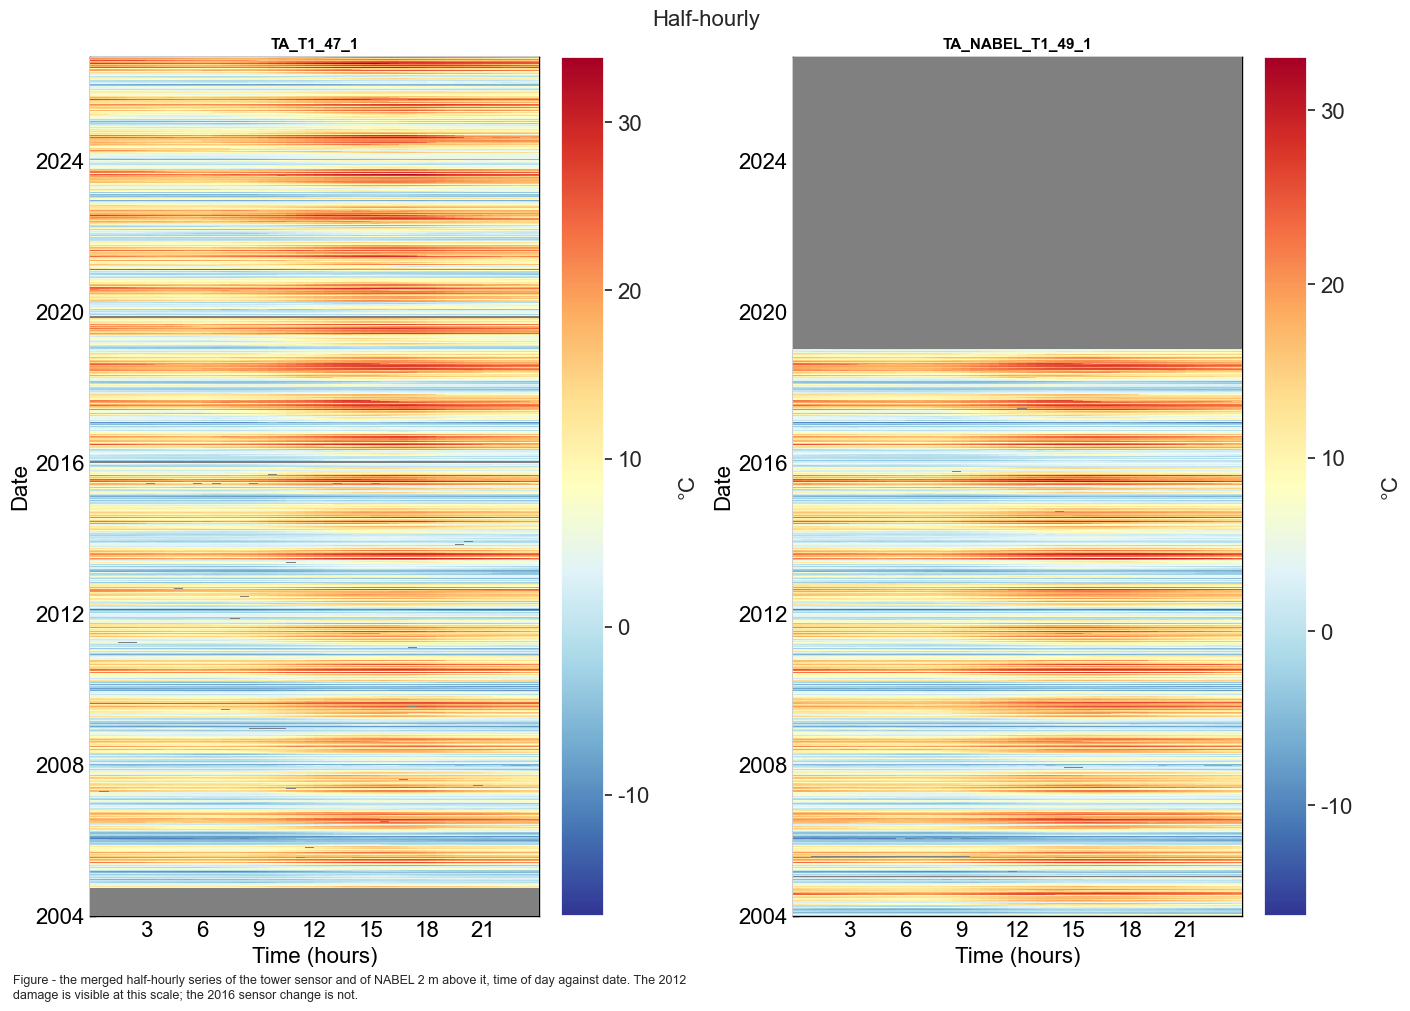

In [15]:
fig, axs = plt.subplots(ncols=2, figsize=(14, 10), dpi=100, layout="constrained")
fig.suptitle(f'Half-hourly', fontsize=16)
dv.plotting.HeatmapDateTime(series=ta_2004_2026['TA_T1_47_1']).plot(
    ax=axs[0], cb_digits_after_comma=0, zlabel='°C',
    format_style=dv.plotting.FormatStyle(title="TA_T1_47_1", title_fontsize=11))
dv.plotting.HeatmapDateTime(series=ta_2004_2026['TA_NABEL_T1_49_1']).plot(
    ax=axs[1], cb_digits_after_comma=0, zlabel='°C',
    format_style=dv.plotting.FormatStyle(title="TA_NABEL_T1_49_1", title_fontsize=11))
figcap(fig, "the merged half-hourly series of the tower sensor and of NABEL 2 m above it, "
            "time of day against date. The 2012 damage is visible at this scale; the 2016 "
            "sensor change is not.")

***

## ✴️ Corrections

### Timestamp shift in August 2012
**Info from fieldbook entry 17 Aug 2012:**
>   adjusted the logger date and time. On Servertime (Computer System Time) 17.08.2012 12:31.42 the loggertime was 16.08.2012 08:06:00. Synchronized time at 17.08.2012 11:40:00 servertime. The logger data aquisition on the moxa embedded was restarted

The logger clock was wrong, so every variable on that logger is affected. The correction from
notebook `01` is applied to `TA_T1_47_1`. In the heatmaps below, the warm band must sit around
midday after the correction.

#### 📊 Plot: the August 2012 clock shift, panel by panel

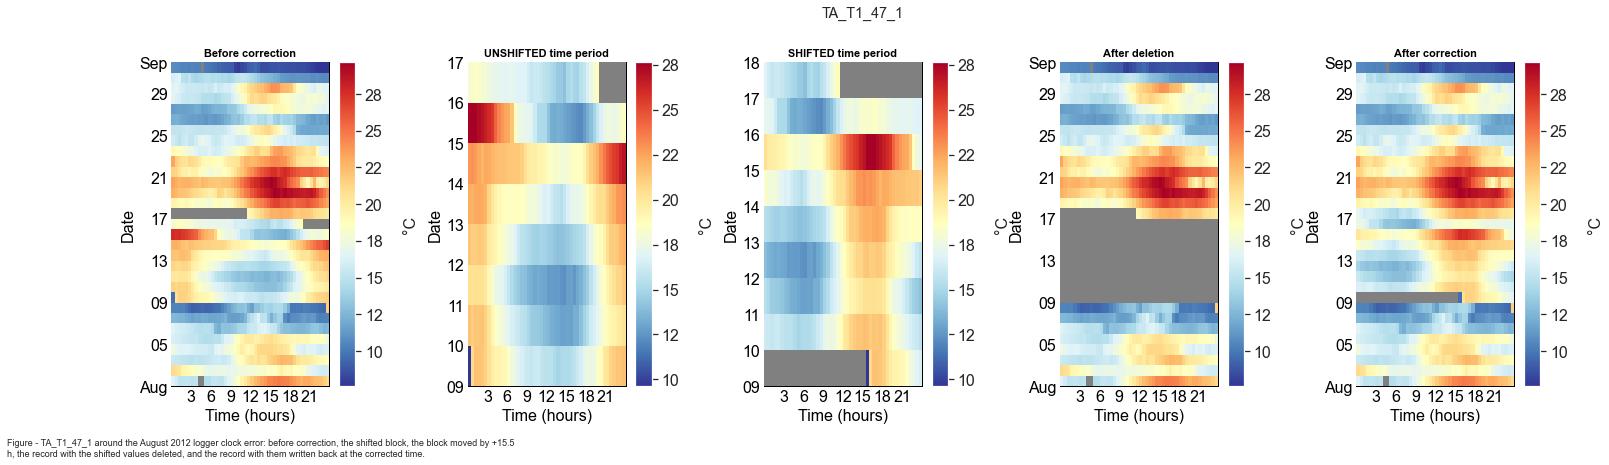

In [16]:
AFFECTED_VARS = ['TA_T1_47_1']
_df = ta_2004_2026.copy()

for av in AFFECTED_VARS:
    fig = plt.figure(figsize=(24, 6), dpi=72)
    fig.suptitle(f"{av}")
    gs = gridspec.GridSpec(1, 5)  # rows, cols
    gs.update(wspace=0.5, hspace=1, left=.1, right=.9, top=.85, bottom=.1)
    ax_before = fig.add_subplot(gs[0, 0])
    ax_unshifted = fig.add_subplot(gs[0, 1])
    ax_shifted = fig.add_subplot(gs[0, 2])
    ax_after = fig.add_subplot(gs[0, 3])
    ax_corrected = fig.add_subplot(gs[0, 4])

    # Show time period around issue, before correction
    _show_locs = (_df.index >= '2012-08-01 00:00') & (_df.index <= '2012-09-01 00:00')
    dv.plotting.HeatmapDateTime(series=_df.loc[_show_locs, av]).plot(
        ax=ax_before, cb_digits_after_comma=0, zlabel='°C',
        format_style=dv.plotting.FormatStyle(title="Before correction", title_fontsize=11))

    # Get shifted time period
    _series_corrected = _df.loc[_show_locs, av].copy()
    # Identify shifted time period
    ISSUE_START = '2012-08-09 00:00'
    ISSUE_END = '2012-08-17 00:00'
    _shifted_locs = (_df.index >= ISSUE_START) & (_df.index <= ISSUE_END)
    _series_shifted = _df.loc[_shifted_locs, av].copy()
    _series_shifted = _series_shifted.dropna()
    dv.plotting.HeatmapDateTime(series=_series_shifted).plot(
        ax=ax_unshifted, cb_digits_after_comma=0, zlabel='°C',
        format_style=dv.plotting.FormatStyle(title="UNSHIFTED time period", title_fontsize=11))

    # Shift by 15.5 hours during shifted time period, create corrected time series
    _series_shifted.index = _series_shifted.index + pd.Timedelta(hours=15.5)
    dv.plotting.HeatmapDateTime(series=_series_shifted).plot(
        ax=ax_shifted, cb_digits_after_comma=0, zlabel='°C',
        format_style=dv.plotting.FormatStyle(title="SHIFTED time period", title_fontsize=11))

    # Delete data between start of issue and the last timestamp of shifted data
    _overwrite_locs = (_df.index >= ISSUE_START) & (_df.index <= _series_shifted.index[-1])
    _df.loc[_overwrite_locs, av] = np.nan
    dv.plotting.HeatmapDateTime(series=_df.loc[_show_locs, av]).plot(
        ax=ax_after, cb_digits_after_comma=0, zlabel='°C',
        format_style=dv.plotting.FormatStyle(title="After deletion", title_fontsize=11))

    # Fill in corrected values
    _df.loc[_overwrite_locs, av] = _series_shifted
    dv.plotting.HeatmapDateTime(series=_df.loc[_show_locs, av]).plot(
        ax=ax_corrected, cb_digits_after_comma=0, zlabel='°C',
        format_style=dv.plotting.FormatStyle(title="After correction", title_fontsize=11))
    figcap(fig, f"{av} around the August 2012 logger clock error: before correction, the "
            f"shifted block, the block moved by +15.5 h, the record with the shifted values "
            f"deleted, and the record with them written back at the corrected time.")

In [17]:
ta_2004_2026 = _df.copy()
ta_2004_2026

,TA_T1_47_1,TA_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,-2.666667
2004-01-01 00:45:00,NaN,-2.566667
2004-01-01 01:15:00,NaN,-2.533333
2004-01-01 01:45:00,NaN,-2.633333
2004-01-01 02:15:00,NaN,-2.800000
...,...,...
2026-09-30 21:45:00,20.036860,NaN
2026-09-30 22:15:00,19.797794,NaN
2026-09-30 22:45:00,19.679122,NaN


### Power failure, late July to mid August 2012

August 2012 has a second fault besides the clock shift. A day-by-day search for the lag at which
`TA_T1_47_1` best matches the NABEL sensor (baseline agreement 0.7-0.9 degC) gives:

| date | best lag | RMSE at best lag | RMSE at zero lag |
|---|---|---|---|
| 2012-07-27 | 0 | 0.76 | 0.76 |
| 2012-07-30 | -24.0 h | 2.51 | 3.06 |
| 2012-08-01 | -1.0 h | 3.22 | 3.31 |
| 2012-08-06 | +1.5 h | 2.49 | 2.53 |
| 2012-08-08 | -35.5 h | 2.85 | 4.95 |
| 2012-08-09 | -33.0 h | 1.19 | 5.30 |
| **2012-08-11** | **+15.5 h** | **0.78** | 5.01 |
| **2012-08-14** | **+15.5 h** | **0.69** | 6.04 |
| **2012-08-16** | **+15.5 h** | **0.84** | 6.00 |
| 2012-08-17 | -0.5 h | 1.65 | 1.69 |
| 2012-08-18 | 0 | 0.64 | 0.64 |

- **11 to 16 August** locks onto `+15.5 h` and returns to the normal 0.7-0.8 degC. This is the
  clock error corrected above; `SW_IN` shows it on the same days.
- **29 July to 9 August** stays at 1.2-3.2 degC at any lag. The best lags near +/-24 h are
  aliases, since shifting a daily cycle by about a day roughly realigns it.

The fieldbook gives the cause and dates the repair to the day the degradation ends:

> **09.08.2012** Fixed the power problem on the tower: replaced battery and replaced some fuses
> (there were many falsely placed or broken) and replaced the whole power supply
>
> **10.08.2012** Some problems remain with logger, maybe it's the WLAN (could not log in the last
> two weeks), restared programs

Two weeks without login places the onset around 27 July, consistent with the 29 July seen in the
data. `SW_IN_T1_47_1` degrades over the same window on the same acquisition system, which points
to a supply fault upstream of both sensors.

The records cannot be repaired. They are deleted here and gap-filled later from NABEL. The windows
are on the **corrected** time axis: the first ends 10 August 15:30, because the shift moves the
9 August readings forward by 15.5 h; the second is the transitional tail after the last shifted
value; the third is the October-November period below. Notebook `01` removes the same windows.

### Storm damage, late October to early November 2012

The same lag search finds a third damaged period:

| date | best lag | RMSE at best lag | RMSE at zero lag |
|---|---|---|---|
| 2012-10-28 | +1.0 h | 0.89 | 0.95 |
| 2012-10-30 | +2.5 h | 2.56 | 2.66 |
| 2012-11-01 | -0.5 h | 2.89 | 2.90 |
| 2012-11-05 | -3.0 h | 5.66 | 5.88 |
| 2012-11-08 | -1.0 h | 2.25 | 2.29 |
| 2012-11-10 | 0 | 1.42 | 1.42 |

`TA` is still normal on 28 October (0.89 degC) and degrades from 29-30 October; `SW_IN` is
already bad on the 28th. The window starts on the 28th to match `SW_IN`, at the cost of one good
day of `TA`.

No time shift helps (the gain is at most a few hundredths), so this is not a clock problem. The
fieldbook records storm damage and cable work in this window:

> **01.11.2012** Checked Forestfloor and Hut for broken sensors due to fallen trees and big branches
>
> **06.11.2012** checked all sensor cables. especialy the cables at the forest floor are sometimes
> strongly stressed. tried to unstress the cables

The data return to normal from 10 November, right after that visit. Both entries name the
*forest floor* sensors, not the 47 m instruments, so the link is circumstantial. `SW_IN_T1_47_1`
and `TA_T1_47_1` fail on the same days, which again points to a shared cause.

On **30.10.2012** the fieldbook notes that the MOXA was "running on wrong time base: CEST instead
of CET", fixed at 10:11 that day. Daylight saving ended on 28 October, so timestamps may have been
an hour ahead for two days. The data show no such offset (it would appear as a best lag of
-2 records), and the period is removed in any case.

#### 📊 Plot: 2012 after removing the damaged periods

Removed 1215 degraded records from TA_T1_47_1 (gap-filled later from NABEL).


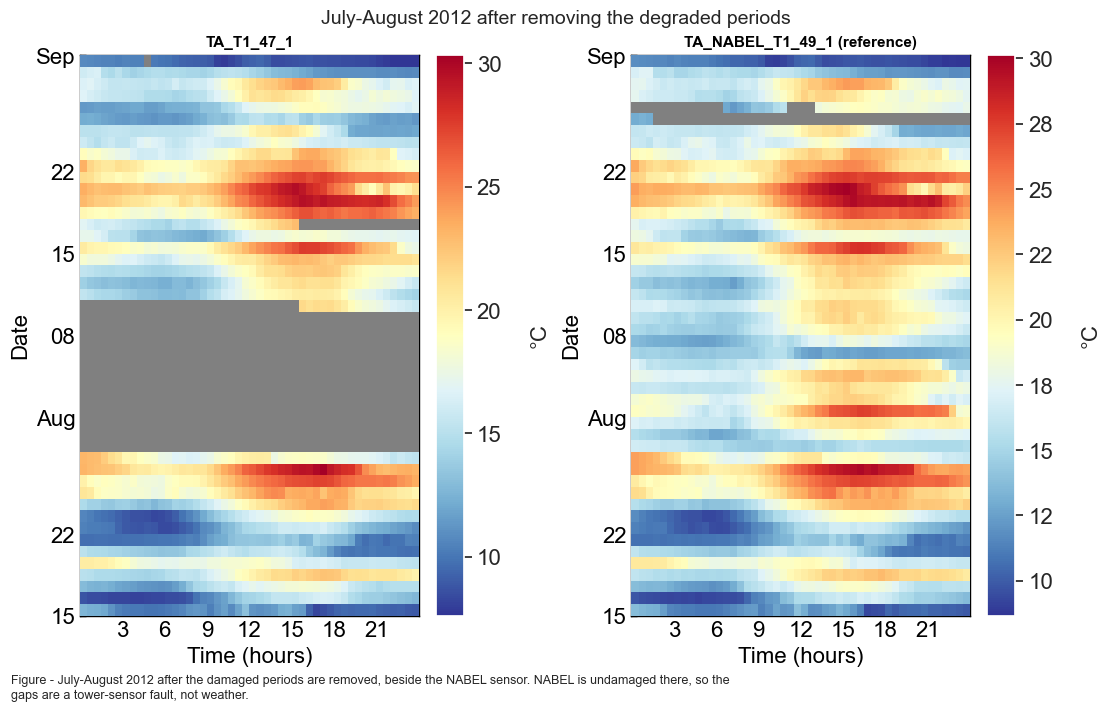

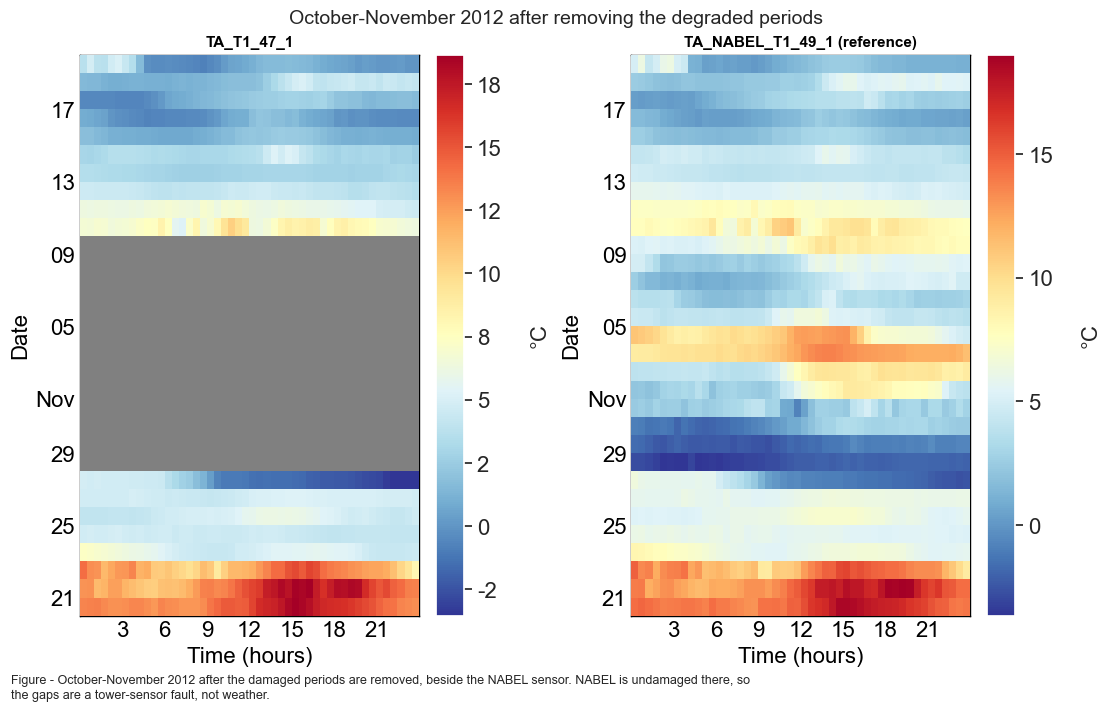

In [18]:
# Three damaged periods in 2012, all documented in the fieldbook and none repairable.
# Windows are on the CORRECTED time axis (i.e. after the +15.5 h shift above).
BAD_WINDOWS_2012 = [
    ('2012-07-29 00:00', '2012-08-10 15:30'),  # tower power supply failure (fieldbook 09.08.2012)
    ('2012-08-17 15:30', '2012-08-18 00:00'),  # transitional tail after the last shifted value
    ('2012-10-28 00:00', '2012-11-10 00:00'),  # storm damage, stressed cables (fieldbook 01./06.11.2012)
]
DEGRADED_VAR = 'TA_T1_47_1'

_before = int(ta_2004_2026[DEGRADED_VAR].notna().sum())
for _start, _end in BAD_WINDOWS_2012:
    _locs = (ta_2004_2026.index >= _start) & (ta_2004_2026.index <= _end)
    ta_2004_2026.loc[_locs, DEGRADED_VAR] = np.nan
_removed = _before - int(ta_2004_2026[DEGRADED_VAR].notna().sum())
print(f"Removed {_removed} degraded records from {DEGRADED_VAR} (gap-filled later from NABEL).")

# One heatmap pair per affected period, with the NABEL sensor as the reference.
for _lo, _hi, _label in [('2012-07-15', '2012-09-01', 'July-August'),
                         ('2012-10-20', '2012-11-20', 'October-November')]:
    fig, axs = plt.subplots(ncols=2, figsize=(11, 7), dpi=100, layout="constrained")
    fig.suptitle(f'{_label} 2012 after removing the degraded periods', fontsize=14)
    _show = (ta_2004_2026.index >= _lo) & (ta_2004_2026.index <= _hi)
    dv.plotting.HeatmapDateTime(series=ta_2004_2026.loc[_show, DEGRADED_VAR]).plot(
        ax=axs[0], cb_digits_after_comma=0, zlabel='°C',
        format_style=dv.plotting.FormatStyle(title=DEGRADED_VAR, title_fontsize=11))
    dv.plotting.HeatmapDateTime(series=ta_2004_2026.loc[_show, 'TA_NABEL_T1_49_1']).plot(
        ax=axs[1], cb_digits_after_comma=0, zlabel='°C',
        format_style=dv.plotting.FormatStyle(title='TA_NABEL_T1_49_1 (reference)', title_fontsize=11))
    figcap(fig, f"{_label} 2012 after the damaged periods are removed, beside the NABEL "
            f"sensor. NABEL is undamaged there, so the gaps are a tower-sensor fault, "
            f"not weather.")

### Probe handling, 16 May 2025, and probe swap, 5 June 2026

Two half-hours hold a record that is neither sensor state, and both are removed and gap-filled:

- **16 May 2025, 09:30 to 10:00.** The raw 1-minute `TA_T1_47_1` jumps by about 5 °C between
  09:32 and 09:42 (`TIMESTAMP_END`) while the 35 m sensor does not: the CS215 was handled during a
  site visit (step 1️⃣1️⃣ of the break section).
- **5 June 2026, 11:00 to 11:30.** The CS215 was replaced by a Campbell HygroVUE10 (step 1️⃣2️⃣).
  The raw record has a gap from 11:10 to 11:31, so the half-hour holds at most ten minutes of the
  old probe and none of the new one.

Each is filled by the model of the period it belongs to, homogenised with that period, and
carries source code `5`.

#### 📋 Table: tower record around the probe handling and the probe swap

In [19]:
# The probe handling and probe swap half-hours, removed before gap-filling like the 2012 windows,
# so that a partial or mixed record never enters the product as a measurement. Each is the
# half-hour immediately before the first record of the next sensor state. The screening may have
# emptied one already; it is removed here in either case.
PROBE_HALF_HOURS = {'probe handling': (HANDLING_RECORD, RESET_START),
                    'probe swap': (SWAP_RECORD, HV_START)}
_around = {}
for _label, (_record, _next) in PROBE_HALF_HOURS.items():
    assert _record in ta_2004_2026.index, f"the {_label} record is not on the product index"
    assert _record == _next - pd.Timedelta('30min'), \
        f"the {_label} record is not the half-hour immediately before the next sensor state"
    _downloaded = ta_2004_2026.loc[_record, 'TA_T1_47_1']
    ta_2004_2026.loc[_record, 'TA_T1_47_1'] = np.nan
    print(f"{_label} record {_record}: "
          f"{'already missing after screening' if pd.isna(_downloaded) else f'{_downloaded:.2f} degC as downloaded'}"
          f", removed")
    _around[f"{_label}, {_record:%d %b %Y}"] = ta_2004_2026.loc[
        _record - pd.Timedelta('2h'):_record + pd.Timedelta('2h'), 'TA_T1_47_1'].rename(
        lambda _t: f"{(_t - _record) / pd.Timedelta('1min'):+.0f} min")
tabcap("the tower record from two hours before to two hours after each removed probe half-hour, "
       "after the removal (degC)")
display(pd.DataFrame(_around))

probe handling record 2025-05-16 09:45:00: 13.14 degC as downloaded, removed
probe swap record 2026-06-05 11:15:00: already missing after screening, removed
Table - the tower record from two hours before to two hours after each removed probe half-hour,
after the removal (degC)



,"probe handling, 16 May 2025","probe swap, 05 Jun 2026"
TIMESTAMP_MIDDLE,,
-120 min,11.112872,9.804005
-90 min,11.583877,10.059655
-60 min,12.202828,11.049461
-30 min,12.192733,11.145333
+0 min,NaN,NaN
+30 min,12.623084,11.201055
+60 min,12.655438,11.383384
+90 min,13.282029,11.941312
+120 min,13.428972,13.033923


::: {.callout-note title="No zero-offset correction here"}
Notebook `01` removes a nighttime zero-offset from `SW_IN`, because radiation sensors can read a
small non-zero value at night when the true value is zero. Air temperature has no such reference
value, so no equivalent correction is applied.
:::

### 📋 Table: merged frame after the corrections

In [20]:
tabcap("the merged 30MIN frame after the 2012 corrections and the removal of the two probe half-hours, as it enters the break section below")
display(ta_2004_2026)
ta_2004_2026.describe()

Table - the merged 30MIN frame after the 2012 corrections and the removal of the two probe half-
hours, as it enters the break section below



,TA_T1_47_1,TA_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,-2.666667
2004-01-01 00:45:00,NaN,-2.566667
2004-01-01 01:15:00,NaN,-2.533333
2004-01-01 01:45:00,NaN,-2.633333
2004-01-01 02:15:00,NaN,-2.800000
...,...,...
2026-09-30 21:45:00,20.036860,NaN
2026-09-30 22:15:00,19.797794,NaN
2026-09-30 22:45:00,19.679122,NaN


,TA_T1_47_1,TA_NABEL_T1_49_1
count,382167.000000,262403.000000
mean,9.100843,8.941020
std,8.231389,8.028659
min,-17.200001,-16.366667
25%,2.733000,2.633333
50%,9.010000,9.100000
75%,15.165370,14.966667
max,33.895510,33.066667


***

## 🔎 The 2016 acquisition break

On 21 January 2016 the 47 m sensor and the acquisition system were replaced together, and the
record steps by about 1.3 °C, the same order as the warming signal. Its effect on the period means
and the trend is computed in *What the break does to the numbers this product is used for* below.

This section establishes, from data or from files on disk:

1. **that a step exists, and when** (difference against MeteoSwiss);
2. **that this notebook does not produce it** (the corrections above and the `mst`/`diive` splice);
3. **which sensor moved** (NABEL at 49 m spans the break on the same tower);
4. **which side of the break is correct** (at night, where a radiation-shield error cannot
   contribute);
5. **what caused it** (the two logger programs and the fieldbook);
6. **that the error is a constant**, which justifies the constant correction of step 8️⃣. The
   rejected alternatives follow it.

Step 9️⃣ scores the result against **MeteoSwiss**, which entered none of the derivation: the step
is gone at night and remains in daylight. Step 🔟 removes the daylight part by fitting each sensor
era's radiation-shield response against the aspirated NABEL sensor and standardising the later era
onto the earlier one. The exported homogenised column carries **both** terms. Step 1️⃣1️⃣ documents
the change of the CS215 on 16 May 2025, after which it no longer carries the shield excess, and
corrects that era by a night term. Step 1️⃣2️⃣ brings the HygroVUE10 that replaced the CS215 on
5 June 2026 onto the level of the normal CS215, so both terms then apply to it as well.

### 1️⃣ A step exists, and it is not weather

MeteoSwiss Lägern is 2.5 km from the tower and is operated by a different institution, so the
difference between the two stations removes the weather and leaves the instruments. A constant
offset is expected from the elevation difference; what matters is whether that offset stays
constant.


#### 📋 Table: tower minus MeteoSwiss per year

In [21]:
# The reference is stored on TIMESTAMP_END and is shifted onto TIMESTAMP_MID, as everywhere else
# in this notebook. `ta_2004_2026` already carries the 2012 corrections, so the comparison below is
# against the series as this notebook has it, not against the raw download.
# Radiation and wind are read here too but unused in this step: the closing step bins the
# residual by them, and one reference frame avoids two that could drift apart.
_ref = pd.read_parquet(REFPATH)[[REFCOL, REFCOL_SW, REFCOL_WS]]
_ref.index = _ref.index - pd.Timedelta(minutes=15)
_ref.index.name = ta_2004_2026.index.name

evidence = pd.concat([ta_2004_2026[['TA_T1_47_1', 'TA_NABEL_T1_49_1']], _ref], axis=1)
evidence = evidence.loc['2005':]

_res = (evidence['TA_T1_47_1'] - evidence[REFCOL]).dropna()
_yearly = _res.groupby(_res.index.year).agg(['mean', 'std', 'count'])
_yearly.columns = ['mean difference (degC)', 'SD (degC)', 'records']
_yearly.index.name = 'YEAR'
print("Tower 47 m minus MeteoSwiss Laegern, per year:")
tabcap("the difference between the tower and MeteoSwiss per year. A constant offset is expected from the elevation difference; the change between 2015 and 2016 is not")
display(_yearly.round(2))

# The step is large enough to state as a fact rather than to eyeball. Both eras are quoted on
# complete years so that a partial year cannot carry the difference.
# 2016 is left out of both periods: it is the year the changeover happened, so it belongs to
# neither era. The end year is taken from the data rather than written down.
# The later era is the normal CS215 and ends where its heated state begins (code 7, step 11), so
# that neither the heating nor the change of May 2025 enters a figure about the 2016 break.
_last = (EXCESS_START - pd.Timedelta('30min')).year
_pre = _res[(_res.index.year >= 2005) & (_res.index.year <= 2015)].mean()
_post = _res[(_res.index.year >= 2017) & (_res.index < EXCESS_START)].mean()
print(f"\n2005-2015: {_pre:+.2f} degC   2017 to {EXCESS_START:%d %b %Y}: {_post:+.2f} degC   "
      f"step: {_post - _pre:+.2f} degC")
assert abs(_post - _pre) > 1.0, "the step is not present - has the product or the reference changed?"


Tower 47 m minus MeteoSwiss Laegern, per year:
Table - the difference between the tower and MeteoSwiss per year. A constant offset is expected from
the elevation difference; the change between 2015 and 2016 is not



,mean difference (degC),SD (degC),records
YEAR,,,
2005,-0.05,0.82,17486
2006,-0.21,1.00,17494
2007,-0.16,0.97,17507
2008,-0.10,0.81,17548
2009,-0.11,0.88,17036
2010,0.03,0.66,17351
2011,0.05,0.91,17499
2012,0.08,0.78,16286
2013,0.03,0.89,17434



2005-2015: -0.04 degC   2017 to 22 Oct 2024: +1.48 degC   step: +1.53 degC


### 2️⃣ The step is not produced in this notebook

**The corrections above** act on August, October and November 2012, and on two single
half-hours, the probe handling of May 2025 and the probe swap of June 2026.

**The `mst`/`diive` splice** sits at the end of 2021, so both sides of the 2016 break come from the
same MeteoScreeningTool screening. The check below confirms that the `diive` record does not reach
back to 2016. The `mst` series carries one `raw_varname` (`TA_AVG_T1_47_1`), `gain 1.0` and
`offset 0.0` over its whole extent, so nothing was rescaled on import.

In [22]:
# The mst/diive boundary sits at the end of 2021, nowhere near the break. If the diive record began
# in 2016 this whole diagnosis would be a screening artefact instead of an instrument change.
_diive_first = nabel_eth_diive_ta['TA_T1_47_1'].dropna()
_diive_first = _diive_first.index[0] if len(_diive_first) else None
print(f"first diive-screened TA_T1_47_1 record: {_diive_first}")
assert _diive_first is None or _diive_first.year >= 2021, (
    "the diive screening reaches back to the break - the step could be a screening artefact")

# And this notebook's own corrections are confined to 2012, plus the two probe half-hours of 2025
# and 2026.
print("2012 removal windows applied above:")
for _start, _end in BAD_WINDOWS_2012:
    print(f"  {_start} -> {_end}")
for _label, (_record, _next) in PROBE_HALF_HOURS.items():
    print(f"{_label} record removed above: {_record}")
assert all(pd.Timestamp(_s).year == 2012 for _s, _e in BAD_WINDOWS_2012), \
    "a correction window outside 2012 - the reasoning below no longer holds"

first diive-screened TA_T1_47_1 record: 2022-01-01 00:15:00
2012 removal windows applied above:
  2012-07-29 00:00 -> 2012-08-10 15:30
  2012-08-17 15:30 -> 2012-08-18 00:00
  2012-10-28 00:00 -> 2012-11-10 00:00
probe handling record removed above: 2025-05-16 09:45:00
probe swap record removed above: 2026-06-05 11:15:00


### 3️⃣ The tower sensor moved, not the references

NABEL sits at 49 m on the **same tower**, two metres above the ETH sensor, and runs to the end of
2018, so it brackets the break. With MeteoSwiss this gives three pairwise differences. If
`NABEL - MeteoSwiss` is flat across the break, the two references agree and the change is at the
ETH sensor.

#### 📋 Table: pairwise differences across the break

In [23]:
# Three pairwise differences across the break. Complete years either side, so that the January
# 2016 outage does not sit inside a compared window.
_pairs = [('tower 47 m - NABEL 49 m', 'TA_T1_47_1', 'TA_NABEL_T1_49_1'),
          ('tower 47 m - MeteoSwiss ', 'TA_T1_47_1', REFCOL),
          ('NABEL 49 m - MeteoSwiss ', 'TA_NABEL_T1_49_1', REFCOL)]

# Named once, because the figure below marks the same boundary the table compares across. The
# window ends in 2018 because NABEL does; the break year is inside the later window rather than
# excluded, which is only sound because it holds no measurement before the changeover.
PAIR_WIN_PRE = (2013, 2015)
PAIR_WIN_POST = (2016, 2018)

_rows = []
for _label, _a, _b in _pairs:
    _d = (evidence[_a] - evidence[_b]).dropna()
    _p = _d[(_d.index.year >= PAIR_WIN_PRE[0]) & (_d.index.year <= PAIR_WIN_PRE[1])]
    _q = _d[(_d.index.year >= PAIR_WIN_POST[0]) & (_d.index.year <= PAIR_WIN_POST[1])]
    _rows.append({'pair': _label,
                  f'{PAIR_WIN_PRE[0]}-{PAIR_WIN_PRE[1]} (degC)': _p.mean(),
                  f'{PAIR_WIN_POST[0]}-{PAIR_WIN_POST[1]} (degC)': _q.mean(),
                  'step (degC)': _q.mean() - _p.mean(), 'records': len(_p) + len(_q)})
_step_table = pd.DataFrame(_rows).set_index('pair')
tabcap("the three pairwise differences across the break. Only the two that involve the tower sensor step, which attributes the change to it")
display(_step_table.round(2))

# The decisive assertion of this section: the two references agree with each other across the
# break. Without this, the step could belong to either station.
_ref_step = abs(_step_table.loc['NABEL 49 m - MeteoSwiss ', 'step (degC)'])
print(f"NABEL against MeteoSwiss changes by {_ref_step:.2f} degC across the break.")
assert _ref_step < 0.25, (
    "the two references disagree across the break - the step cannot be attributed to the tower "
    "sensor without further evidence")


Table - the three pairwise differences across the break. Only the two that involve the tower sensor
step, which attributes the change to it



,2013-2015 (degC),2016-2018 (degC),step (degC),records
pair,,,,
tower 47 m - NABEL 49 m,-1.05,0.55,1.60,104036
tower 47 m - MeteoSwiss,-0.01,1.53,1.54,104023
NABEL 49 m - MeteoSwiss,1.04,0.99,-0.06,105112


NABEL against MeteoSwiss changes by 0.06 degC across the break.


#### 📊 Plot: pairwise differences over the record

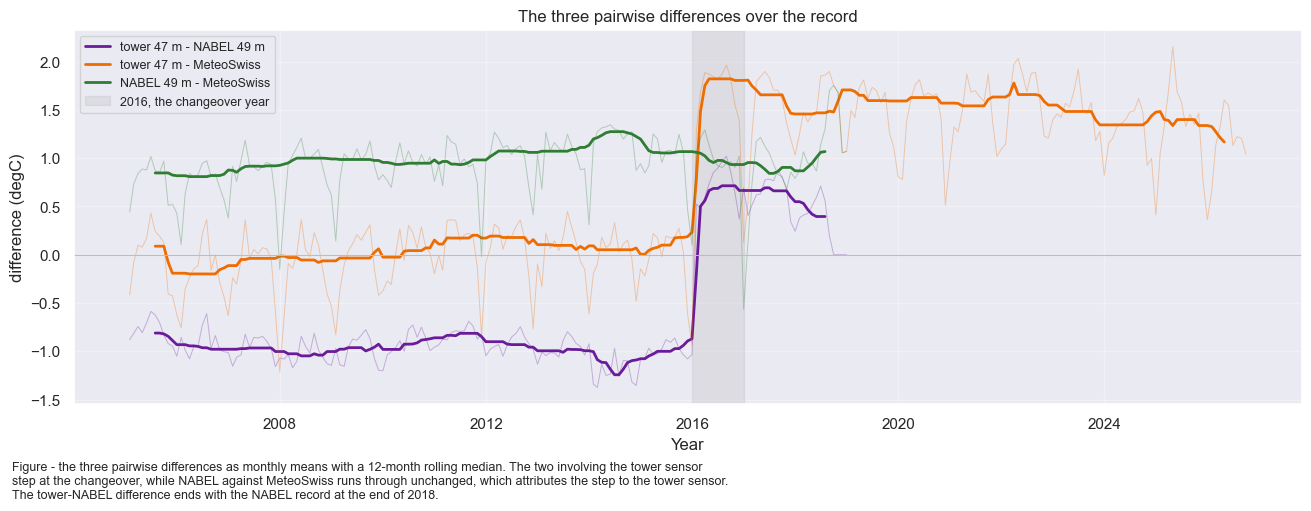

In [24]:
# The same three differences over the whole record, as monthly means with a 12-month rolling
# median over them. The table above is two windows of this figure; the figure shows whether the
# step is a step or the end of a drift, which two window means cannot.
fig, ax = plt.subplots(figsize=(13, 5), dpi=100, layout="constrained")
for (_label, _a, _b), _colour in zip(_pairs, ['#6A1B9A', '#EF6C00', '#2E7D32']):
    _d = (evidence[_a] - evidence[_b]).dropna().resample('ME').mean()
    ax.plot(_d.index, _d, color=_colour, lw=0.7, alpha=0.3)
    ax.plot(_d.index, _d.rolling(12, center=True).median(), color=_colour, lw=2, label=_label.strip())
ax.axvspan(pd.Timestamp(f'{PAIR_WIN_POST[0]}-01-01'), pd.Timestamp(f'{PAIR_WIN_POST[0] + 1}-01-01'),
           color='#9E9E9E', alpha=0.18, label=f'{PAIR_WIN_POST[0]}, the changeover year')
ax.axhline(0, color='#BDBDBD', lw=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("difference (degC)")
ax.set_title("The three pairwise differences over the record")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
figcap(fig, "the three pairwise differences as monthly means with a 12-month rolling median. "
            "The two involving the tower sensor step at the changeover, while NABEL against "
            "MeteoSwiss runs through unchanged, which attributes the step to the tower sensor. "
            "The tower-NABEL difference ends with the NABEL record at the end of 2018.")

### 4️⃣ Exactly when, and which side is correct

The changeover falls inside an outage, so the record itself dates the break. Which side is
*correct* is decided **at night**, when a radiation-shield error cannot act and two sensors two
metres apart on one tower should agree to a few tenths of a degree. Night is defined by potential
radiation from the site coordinates, so the test uses no external measurement.

In [25]:
# The outage that contains the changeover, located in the data.
_meas = ta_2004_2026['TA_T1_47_1'].loc['2015-12-01':'2016-03-01']
_missing = _meas.isna()
_blocks = _missing.ne(_missing.shift()).cumsum()
_runs = _missing[_missing].groupby(_blocks[_missing])
_longest = max(_runs, key=lambda kv: len(kv[1]))[1]

# The two boundaries are read off that outage rather than off a date written here. A hard-coded
# '2016-01-01' would also slice inclusively on both sides (pandas partial-string indexing), so a
# measurement on that day could put LAST_BEFORE after BREAK without anything complaining.
_series = ta_2004_2026['TA_T1_47_1'].dropna()
LAST_BEFORE = _series[_series.index < _longest.index[0]].index[-1]
BREAK = _series[_series.index > _longest.index[-1]].index[0]
print(f"outage:               {_longest.index[0]} -> {_longest.index[-1]} "
      f"({len(_longest)} records, {len(_longest) * 0.5:.0f} h)")
print(f"last measured before: {LAST_BEFORE}")
print(f"first measured after: {BREAK}   <- BREAK")
assert len(_longest) > 500, "the January 2016 outage is not in the data as expected"
assert LAST_BEFORE < _longest.index[0] <= _longest.index[-1] < BREAK, \
    "the break boundaries do not bracket the outage"
# The probe half-hours removed in Corrections (handling in May 2025, swap in June 2026) lie far
# from this break, so the step found here is not produced by those removals.
assert all(abs(_record - BREAK) > pd.Timedelta('365D') for _record, _next in PROBE_HALF_HOURS.values()), \
    "a probe half-hour removal lies within a year of the 2016 break - the reasoning below no longer holds"

# The first tower measurement of all. Everything before it is modelled throughout.
RECORD_START = _series.index[0]
print(f"tower record begins:  {RECORD_START}  "
      f"({(RECORD_START - ta_2004_2026.index[0]).days} days after the product starts)")

# Night from potential radiation: no reference measurement enters this test. It is computed over
# the WHOLE record, not over the evidence window below - the checks at export use this mask, and
# one restricted to 2005 onwards would silently skip 2004, which is the least constrained year.
_potrad = dv.variables.potrad(timestamp_index=ta_2004_2026.index, lat=SITE_LAT, lon=SITE_LON,
                              utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS)
NIGHT = _potrad <= 0

_night = evidence[['TA_T1_47_1', 'TA_NABEL_T1_49_1']].dropna()
_night = _night[NIGHT.reindex(_night.index).fillna(False)]
_era_pre = _night.loc[:LAST_BEFORE]
_era_post = _night.loc[BREAK:'2018']

for _label, _era in [('MP101A era (2005 - 2015)', _era_pre), ('CS215 era  (2016 - 2018)', _era_post)]:
    _bias = _era['TA_T1_47_1'] - _era['TA_NABEL_T1_49_1']
    print(f"  {_label}: tower minus NABEL at night = {_bias.mean():+.2f} degC "
          f"(SD {_bias.std():.2f}, n={len(_era):,})")


outage:               2016-01-01 00:15:00 -> 2016-01-21 13:45:00 (988 records, 494 h)
last measured before: 2015-12-31 23:45:00
first measured after: 2016-01-21 14:15:00   <- BREAK
tower record begins:  2004-09-20 10:45:00  (263 days after the product starts)
  MP101A era (2005 - 2015): tower minus NABEL at night = -1.09 degC (SD 0.25, n=90,942)
  CS215 era  (2016 - 2018): tower minus NABEL at night = +0.25 degC (SD 0.25, n=24,513)


#### 📊 Plot: the January 2016 changeover in context

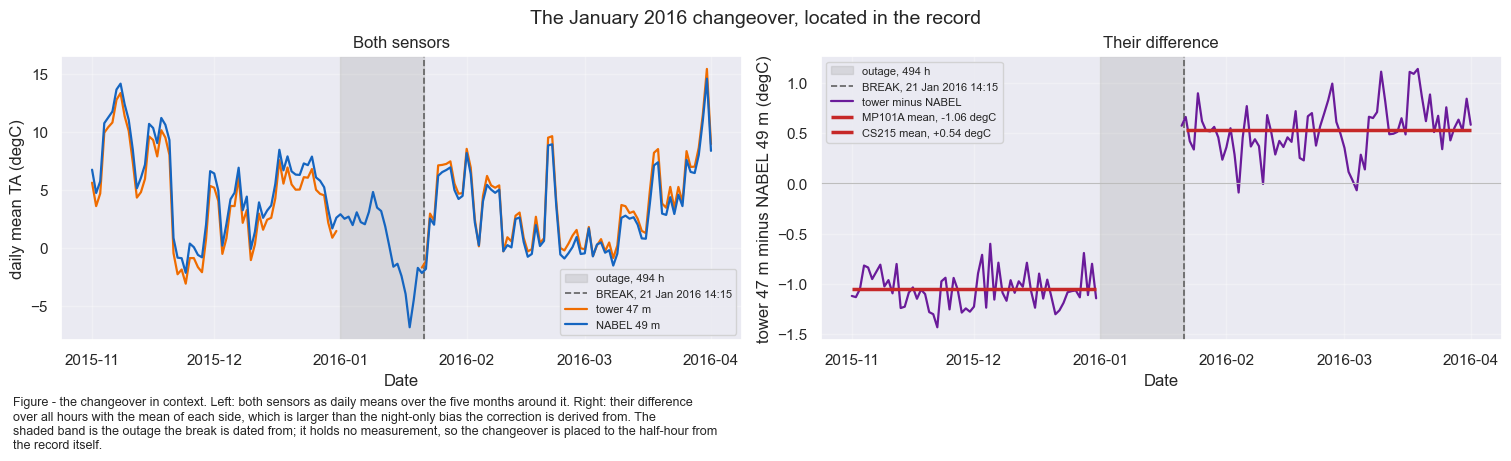

In [26]:
# The outage located above, drawn with the sensor it is dated against. Left: both series as daily
# means over the three months around it. Right: their difference, which is where the change is -
# the two eras sit on visibly different levels either side of a gap that contains no measurement.
_zoom_from, _zoom_to = '2015-11-01', '2016-04-01'
_zoom = ta_2004_2026.loc[_zoom_from:_zoom_to, ['TA_T1_47_1', 'TA_NABEL_T1_49_1']]
_zoom_daily = _zoom.resample('D').mean()
_zoom_diff = (_zoom['TA_T1_47_1'] - _zoom['TA_NABEL_T1_49_1']).resample('D').mean()

fig, axs = plt.subplots(ncols=2, figsize=(15, 4.5), dpi=100, layout="constrained")
fig.suptitle("The January 2016 changeover, located in the record", fontsize=14)

for _ax in axs:
    _ax.axvspan(_longest.index[0], _longest.index[-1], color='#9E9E9E', alpha=0.25,
                label=f"outage, {len(_longest) * 0.5:.0f} h")
    _ax.axvline(BREAK, color='#616161', lw=1.2, ls='--', label=f"BREAK, {BREAK:%d %b %Y %H:%M}")
    _ax.set_xlabel("Date")
    _ax.grid(alpha=0.3)

axs[0].plot(_zoom_daily.index, _zoom_daily['TA_T1_47_1'], color='#EF6C00', lw=1.6,
            label='tower 47 m')
axs[0].plot(_zoom_daily.index, _zoom_daily['TA_NABEL_T1_49_1'], color='#1565C0', lw=1.6,
            label='NABEL 49 m')
axs[0].set_ylabel("daily mean TA (degC)")
axs[0].set_title("Both sensors")
axs[0].legend(fontsize=8)

axs[1].plot(_zoom_diff.index, _zoom_diff, color='#6A1B9A', lw=1.6, label='tower minus NABEL')
axs[1].axhline(0, color='#BDBDBD', lw=0.8)
for _side, _label in [(slice(_zoom_from, LAST_BEFORE), 'MP101A'), (slice(BREAK, _zoom_to), 'CS215')]:
    _m = _zoom_diff.loc[_side].mean()
    axs[1].hlines(_m, *[_zoom_diff.loc[_side].index[i] for i in (0, -1)], color='#C62828', lw=2.5,
                  label=f"{_label} mean, {_m:+.2f} degC")
axs[1].set_ylabel("tower 47 m minus NABEL 49 m (degC)")
axs[1].set_title("Their difference")
axs[1].legend(fontsize=8)
figcap(fig, "the changeover in context. Left: both sensors as daily means over the five months "
            "around it. Right: their difference over all hours with the mean of each side, which "
            "is larger than the night-only bias the correction is derived from. The shaded band is "
            "the outage the break is dated from; it holds no measurement, so the changeover is "
            "placed to the half-hour from the record itself.")

The earlier era reads about 1.1 °C below NABEL for eleven years; the later era agrees with it to
about 0.25 °C, within the manufacturer's specification. **The pre-2016 era is the one in error.**
Although the record jumps *upwards* in 2016, it is the earlier years that are too cold.

### 5️⃣ What caused it: the two logger programs

Only the measurement instruction is extracted from each program. The files are signed by their
authors, so the header is never printed and the excerpts pass through the fieldbook redaction.

In [27]:
# --- Fieldbook and logger-script redaction ----------------------------------------------------
# Both the GIN export and the logger programs name people. This notebook renders to a public page,
# so every string taken out of either passes through redact_people() at the single point where it
# is flattened. Same map and same rules as notebook 08; it lives beside the export, OUTSIDE this
# repository, so the repo never carries a real name.
REDACT_MAP = Path(FIELDBOOK).with_name('redact_names.csv')
ALLOW_LIST = Path(FIELDBOOK).with_name('redact_allow.csv')
def unmapped_report_path(label: str) -> Path:
    """Where the unmapped-name candidates of one audit are written.

    Per label, because this notebook audits two sources: a single shared file would let the
    second audit overwrite the first one's findings.
    """
    _slug = re.sub(r'[^a-z0-9]+', '_', label.lower()).strip('_')
    return Path(FIELDBOOK).with_name(f'redact_unmapped_{_slug}.txt')


def load_redactions(path=None) -> dict:
    """Load the name -> pseudonym map.

    Raises if the map is missing. That is the point: carrying on with redaction quietly disabled
    prints real names into a published page and looks exactly like success.
    """
    path = REDACT_MAP if path is None else Path(path)
    if not path.is_file():
        raise FileNotFoundError(
            f"the redaction map is missing: {path}. Without it the names these files record would "
            f"print unredacted. Restore the file rather than skipping this.")
    tab = pd.read_csv(path, encoding='utf-8')
    missing = {'name', 'pseudonym'}.difference(tab.columns)
    if missing:
        raise ValueError(f"{path}: missing column(s) {sorted(missing)}.")
    pairs = {str(n).strip(): str(p).strip()
             for n, p in zip(tab['name'], tab['pseudonym']) if str(n).strip()}
    if not pairs:
        raise ValueError(f"{path}: holds no usable name -> pseudonym pairs.")
    return pairs


REDACTIONS = load_redactions()
# Longest surface form first, so a bare surname cannot corrupt a double-barrelled one that starts
# with it. Lookarounds rather than \b, because some forms end in an initial.
_REDACT_RX = re.compile(r'(?<!\w)(' + '|'.join(re.escape(n) for n in
                                               sorted(REDACTIONS, key=len, reverse=True))
                        + r')(?!\w)')


def redact_people(s) -> str:
    """Replace every mapped name with its stable pseudonym."""
    return _REDACT_RX.sub(lambda m: REDACTIONS[m.group(1)], str(s))


def strip_html(text) -> str:
    """Flatten one GIN fieldbook entry to plain text, with the people it names redacted."""
    flat = html.unescape(re.sub(r'<[^>]+>', ' ', str(text)))
    return redact_people(re.sub(r'\s+', ' ', flat).strip())


_NAME_TOKEN = r"[A-ZÄÖÜ][\wÄÖÜäöüß'-]{1,20}"
_NAME_UNIT = _NAME_TOKEN + r'(?:\s+' + _NAME_TOKEN + r'){0,2}'
_NAME_SHAPES = (
    re.compile(r'\((' + _NAME_UNIT + r'(?:\s*[,+&]\s*' + _NAME_UNIT + r')*)\s*'
               r'(?:\d{1,2}\.\d{1,2}\.\d{4})?\)'),
    re.compile(r'(?:with|by|durch|von|gemaess)\s+(' + _NAME_TOKEN + r'(?:\s+' + _NAME_TOKEN + r')?)'),
)


def audit_unmapped_names(texts, label='fieldbook', write_report: bool = True) -> int:
    """Raise if any name-shaped token survived redaction.

    A newer export can name someone the map has never seen. Candidates are never printed - an
    exception message is stored in a notebook like any other output - so they go to a file beside
    the map and only the count is shown.
    """
    allow = set(pd.read_csv(ALLOW_LIST, encoding='utf-8')['term'].astype(str).str.strip())
    found = {}
    for _t in texts:
        for _rx in _NAME_SHAPES:
            for _m in _rx.finditer(str(_t)):
                for _tok in re.findall(_NAME_TOKEN, _m.group(1)):
                    if _tok.isupper() or any(ch.isdigit() for ch in _tok) or _tok in allow:
                        continue
                    found[_tok] = found.get(_tok, 0) + 1
    if found:
        _report = unmapped_report_path(label)
        if write_report:
            _report.write_text(
                '\n'.join(f'{n}\t{t}' for t, n in sorted(found.items(), key=lambda kv: -kv[1])),
                encoding='utf-8')
        raise ValueError(
            f"{label}: {len(found)} name-shaped token(s) survived redaction. They are deliberately "
            f"NOT shown here - see {_report}. Add the people to redact_names.csv and the "
            f"technical terms to redact_allow.csv, then re-run.")
    print(f"  {label}: no unmapped name-shaped tokens ({len(allow)} allowlisted terms)")
    return 0


def program_excerpt(path, pattern: str, before: int = 6, after: int = 4,
                    expect: int = 1) -> str:
    """The lines of a logger program around `pattern`, redacted.

    Only the matched instruction is returned, never the file header: these programs are signed by
    their authors. Raises unless the pattern matches exactly `expect` times. Both directions
    matter: no match reads as 'the program does not measure this', and an over-broad pattern
    quietly prints the wrong instruction next to the argument it is supposed to support. The CR10X
    program refers to its air-temperature location four times - once to measure it, once per
    heating threshold, and once to average it into the output table.
    """
    lines = Path(path).read_text(encoding='latin-1').splitlines()
    blocks = []
    for i, line in enumerate(lines):
        if re.search(pattern, line):
            lo, hi = max(0, i - before), min(len(lines), i + after + 1)
            blocks.append('\n'.join(lines[lo:hi]))
    if len(blocks) != expect:
        raise ValueError(f"{Path(path).name}: {pattern!r} matched {len(blocks)} time(s), expected "
                         f"{expect}. The program layout has changed, the wrong file is configured, "
                         f"or the pattern is not specific enough.")
    return redact_people('\n\n'.join(blocks))


In [28]:
# The guards guard. A helper that silently returns nothing is worse than no helper, so both
# failure paths are exercised before anything is read.
try:
    program_excerpt(PROGRAM_AFTER, r'ThisPatternIsNotInAnyLoggerProgram')
except ValueError as _exc:
    print(f"OK, program_excerpt raised on a pattern that does not occur: {_exc}")
else:
    raise AssertionError("(!) program_excerpt accepted a pattern that does not occur.")

# 'Ada Lovelace' is nobody at this site, so the control can spell her out without disclosing
# anything - and it writes no report, so the real one is not overwritten by a test.
try:
    audit_unmapped_names(['12.05.2019 (Ada Lovelace) replaced the logger battery'],
                         'positive control', write_report=False)
except ValueError:
    print("OK, the unknown-name net fired on a name that is not in the map")
else:
    raise AssertionError("(!) the unknown-name net did not fire on an unmapped name.")


OK, program_excerpt raised on a pattern that does not occur: CH-LAE_iDL_T1_47_1.CR1: 'ThisPatternIsNotInAnyLoggerProgram' matched 0 time(s), expected 1. The program layout has changed, the wrong file is configured, or the pattern is not specific enough.
OK, the unknown-name net fired on a name that is not in the map


In [29]:
# The pre-2016 measurement, from the CR10X program of the old acquisition. Anchored on the sensor
# comment rather than on the storage location, because the program refers to that location four
# times and only one of them is the measurement.
print("=" * 78)
print(f"BEFORE: {Path(PROGRAM_BEFORE).name}")
print("=" * 78)
_excerpt_before = program_excerpt(PROGRAM_BEFORE, r'Rotronic MP101A', before=1, after=12)
print(_excerpt_before)

# The post-2016 measurement, from the CR1000 program installed at the changeover.
print("\n" + "=" * 78)
print(f"AFTER:  {Path(PROGRAM_AFTER).name}")
print("=" * 78)
_excerpt_after = program_excerpt(PROGRAM_AFTER, r'CS215', before=1, after=2)
print(_excerpt_after)

# These files are signed by their authors too, so they get the same two nets as the fieldbook:
# redaction inside program_excerpt, and the unknown-name audit here.
audit_unmapped_names([_excerpt_before, _excerpt_after], 'logger programs')

BEFORE: LAEGEREN.20060524.csi
;--------------------------------------------------------
; Rotronic MP101A temperature and relative humidity probe
;--------------------------------------------------------


14:  Volt (SE) (P1)
 1: 1        Reps
 2: 35       2500 mV 50 Hz Rejection Range
 3: 4        SE Channel
 4: 18       Loc [ Temp_air  ]
 5: 0.1      Mult
 6: 0        Offset



AFTER:  CH-LAE_iDL_T1_47_1.CR1
		PortSet(1,0)
		'C'CS215 Temperature & Relative Humidity Sensor measurements 'TA_T1_47_1' and 'RH_T1_47_1'
		SDI12Recorder(TARH_T1_47_1(),3,"0","M!",1,0)
		
  logger programs: no unmapped name-shaped tokens (58 allowlisted terms)


0

**Before**: a **Rotronic MP101A** read as a single-ended voltage with `Mult 0.1` and `Offset 0`,
that is ten millivolts per degree, with zero volts as zero degrees. The same instruction, channel
and constants appear in every tower program version from 26 May 2004 to 24 May 2006, and the
yearly differences in step 1️⃣ show no later change.

**After**: a **Campbell CS215** read over SDI-12 with multiplier `1` and offset `0`. The sensor
delivers degrees and the logger does not scale them, so a wrong multiplier cannot be the cause.

Under `Mult 0.1`, **one degree in the record is ten millivolts at the logger input**.

### 6️⃣ The fieldbook: the changeover is documented to the day

The filter below is wide because fault entries at this site are often filed under another device,
and the decisive entries here carry no device tag.

In [30]:
fb = pd.read_csv(FIELDBOOK)
fb['Date'] = pd.to_datetime(fb['Date'], format='%d.%m.%Y', errors='coerce')
fb['text'] = fb['Text'].apply(strip_html)
audit_unmapped_names(fb['text'], 'fieldbook entries')

# The window from the last measurement before the outage to a fortnight after the record resumes.
# Rows dated exactly 2016-01-01 are dropped: that date is a backdated GIN inventory import of the
# whole site, not a set of events, and it would bury the entries that matter.
_win = fb[(fb['Date'] >= '2016-01-02') & (fb['Date'] <= '2016-02-14')]
_win = _win[_win['text'].str.len() > 40].sort_values('Date')
print(f"fieldbook: {len(fb):,} entries, {fb['Date'].min().date()} -> {fb['Date'].max().date()}")
print(f"entries between 02 Jan and 14 Feb 2016: {len(_win)}\n")
assert len(_win) > 0, "no fieldbook entries in the changeover window - is this the right export?"

# Only the entries that name the tower logger, its program or the new tower box.
_rx = r'logger|loggerprogram|CR1000|towerbox|tower box|wall mounting|iDL_T1_47|T1_47'
for _, _r in _win[_win['text'].str.contains(_rx, case=False, regex=True)].iterrows():
    print(f"--- {_r['Date'].date()}")
    print(f"    {_r['text'][:600]}\n")


  fieldbook entries: no unmapped name-shaped tokens (58 allowlisted terms)
fieldbook: 2,133 entries, 2003-10-24 -> 2026-10-16
entries between 02 Jan and 14 Feb 2016: 19

--- 2016-01-08
    08.01.2016 (person 14, person 01) starting 0930 the eddy boom was retracted for installation work Installed the 7200 including the analyzer and flow module box. Attached the necessary mountings to the boom the tower handrails replaced the broken vektor instruments A100L cup anemometer with a new vector instruments A100LK cup anemometer wwith SN 16697 installed a new direct Kipp&Zonen par ( SN:) sensor and replaced the reflective par ( SN:) on the boom with the Kipp&Zonen par ( SN:) installed the new towerbox and connected the ethernet and 24V power cable to the box tested unispec –> ok tested 

--- 2016-01-21
    Added new device. When installing the new wall installation in the hut including power supply, logger, ioLogik and more

--- 2016-01-21
    21.01.2016 (person 05 remote) Calibrated LI-7000 0

Three entries bracket the outage: a new tower box with its own 24 V supply (8 January); the hut and
profile loggers shut down and remounted (21 January); and the re-upload of the logger program
**`CH-LAE_CR1000_T1_47_1-20160118.CR1`**, dated 18 January inside the outage, with the
registration of `CR1000_E5522` at the tower top (10 February). In the database, the logger's panel
temperature (`T_CR1000_AVG_T1_47_1`) and the profile channel `TA_PRF_T1_54_1` both have their
**first record** at the moment the tower record resumes.

The fieldbook records no replacement of the air-temperature sensor: GIN registers no temperature
or humidity device at `CH-LAE_T1_47` before the HygroVUE10 of June 2026 (step 1️⃣2️⃣ asserts this).
The identity of the two earlier sensors comes only from the two logger programs.

### 7️⃣ The error is a constant, so a constant corrects it

A single offset is legitimate only if the error is a single offset. With a voltage scaled by
`Mult 0.1`, a **zero-point error** (a constant voltage at the input) gives a bias that is constant
in °C, and a **span or gain error** gives one that grows with temperature. The night bias against
NABEL is therefore binned by air temperature below: a flat profile indicates a zero-point error,
and a sloped one would rule out a constant correction.

#### 📋 Table: night bias by air temperature, per era

In [31]:
# Night bias against NABEL, binned by air temperature, per era.
_bins = [(-20, -5), (-5, 0), (0, 5), (5, 10), (10, 15), (15, 20), (20, 35)]
_rows = []
for _lo, _hi in _bins:
    _row = {'TA bin (degC)': f"{_lo} to {_hi}"}
    for _label, _era in [('MP101A era', _era_pre), ('CS215 era', _era_post)]:
        _s = _era[(_era['TA_NABEL_T1_49_1'] > _lo) & (_era['TA_NABEL_T1_49_1'] <= _hi)]
        _row[_label] = (_s['TA_T1_47_1'] - _s['TA_NABEL_T1_49_1']).mean() if len(_s) > 200 else np.nan
        _row[f'n ({_label})'] = len(_s)
    _rows.append(_row)
_bias_profile = pd.DataFrame(_rows).set_index('TA bin (degC)')
tabcap("the night bias against NABEL binned by air temperature, per era. A flat profile is a zero-point error; a sloped one would rule a constant correction out")
display(_bias_profile.round(2))

# Fitted per era: the intercept is the bias at 0 degC, the slope is the temperature dependence.
_fits = {}
for _label, _era in [('MP101A era', _era_pre), ('CS215 era', _era_post)]:
    _bias = _era['TA_T1_47_1'] - _era['TA_NABEL_T1_49_1']
    _slope, _intercept = np.polyfit(_era['TA_NABEL_T1_49_1'].to_numpy(), _bias.to_numpy(), 1)
    _fits[_label] = (_slope, _intercept)
    print(f"  {_label}: bias = {_slope:+.5f} * TA {_intercept:+.4f} degC   "
          f"(implied input error at 0 degC: {_intercept * 10:+.1f} mV at Mult 0.1)")

# A slope of 0.007 degC per degC is 0.3 degC over the full 40 degC range of this record, against a
# constant of about 1.3 degC. The error is overwhelmingly a zero-point offset.
assert abs(_fits['MP101A era'][0]) < 0.02, (
    "the pre-2016 bias depends on temperature more strongly than a zero-point error allows - "
    "a constant offset is not the right correction")


Table - the night bias against NABEL binned by air temperature, per era. A flat profile is a zero-
point error; a sloped one would rule a constant correction out



,MP101A era,n (MP101A era),CS215 era,n (CS215 era)
TA bin (degC),,,,
-20 to -5,-1.01,4399,0.21,639
-5 to 0,-1.09,13131,0.16,3596
0 to 5,-1.17,20565,0.18,5798
5 to 10,-1.18,19215,0.25,4997
10 to 15,-1.06,19097,0.30,4309
15 to 20,-0.95,10811,0.32,3538
20 to 35,-0.86,3724,0.36,1636


  MP101A era: bias = +0.00690 * TA -1.1396 degC   (implied input error at 0 degC: -11.4 mV at Mult 0.1)
  CS215 era: bias = +0.00837 * TA +0.1801 degC   (implied input error at 0 degC: +1.8 mV at Mult 0.1)


#### 📊 Plot: night bias by air temperature, per era

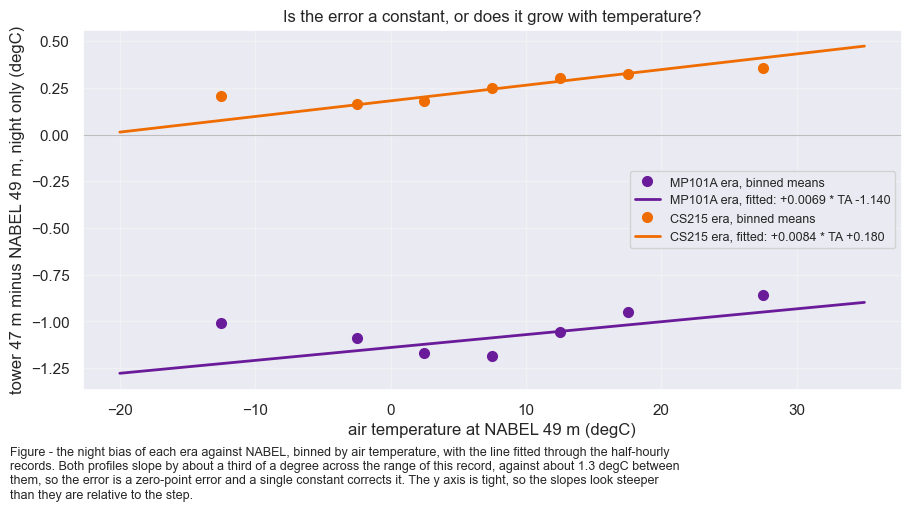

In [32]:
# The table above, drawn with the fitted lines. A zero-point error is horizontal, a gain error
# slopes. The lines are fitted to the half-hourly records, not to the binned points shown.
fig, ax = plt.subplots(figsize=(9, 5), dpi=100, layout="constrained")
_centres = np.array([(_lo + _hi) / 2 for _lo, _hi in _bins])
_grid = np.linspace(min(_lo for _lo, _hi in _bins), max(_hi for _lo, _hi in _bins), 100)
for _label, _colour in [('MP101A era', '#6A1B9A'), ('CS215 era', '#EF6C00')]:
    ax.plot(_centres, _bias_profile[_label].to_numpy(), 'o', color=_colour, ms=7,
            label=f"{_label}, binned means")
    _slope, _intercept = _fits[_label]
    ax.plot(_grid, _slope * _grid + _intercept, '-', color=_colour, lw=2,
            label=f"{_label}, fitted: {_slope:+.4f} * TA {_intercept:+.3f}")
ax.axhline(0, color='#BDBDBD', lw=0.8)
ax.set_xlabel("air temperature at NABEL 49 m (degC)")
ax.set_ylabel("tower 47 m minus NABEL 49 m, night only (degC)")
ax.set_title("Is the error a constant, or does it grow with temperature?")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
figcap(fig, "the night bias of each era against NABEL, binned by air temperature, with the line "
            "fitted through the half-hourly records. Both profiles slope by about a third of a "
            "degree across the range of this record, against about 1.3 degC between them, so the "
            "error is a zero-point error and a single constant corrects it. The y axis is tight, "
            "so the slopes look steeper than they are relative to the step.")

The profile is flat. The fitted pre-2016 bias has a slope of about `+0.007` °C per °C (0.3 °C over
the 40 °C range of the record) against a constant of about 1.3 °C: a zero-point error of about
**−11 mV** at the logger input.

Two causes fit this chain: a ground-potential difference of a few millivolts on the single-ended
channel, fed by a cable from 47 m, or a zero-trim error in the probe output. Either gives a
constant voltage, independent of temperature, stratification and wind, that disappears only with
the analog path, as it did in 2016 when the CS215 made the signal digital. The evidence does not
separate the two (the probe's configuration sheet would be needed), but it establishes the class
of error, which is what the correction depends on.

### 8️⃣ The correction

The homogenised column raises the pre-2016 era onto the post-2016 level, as the `_HOMOGENIZED`
column of notebook `08` does, because the later era agrees with the reference. The constant is the
**difference of the two fitted intercepts**, the step between the eras at 0 °C. It is preferred
over the difference of the night means (they agree to a few hundredths of a degree) because it
removes the small temperature dependence measured above. The measured column is left unchanged.

#### 📋 Table: records per acquisition era

In [33]:
# The homogenisation constant, derived from the fits above rather than written down.
OFFSET = _fits['CS215 era'][1] - _fits['MP101A era'][1]
print(f"Homogenisation offset for the pre-{BREAK.year} era: {OFFSET:+.4f} degC")
print(f"  (CS215 intercept {_fits['CS215 era'][1]:+.4f} minus "
      f"MP101A intercept {_fits['MP101A era'][1]:+.4f})")

# A guard on the derived constant. If a future re-run produces something far from the measured
# step, the fit has gone wrong and the correction must not be applied silently.
assert 1.0 < OFFSET < 1.6, f"the derived offset {OFFSET:.3f} degC is outside the expected range"

# The source flag, on the full product index. Two codes mark records no sensor produced: the
# outage that contains the changeover, and the months before the record begins.
source_flag = pd.Series(SOURCE_CS215, index=ta_2004_2026.index, name='FLAG_TA_T1_47_1_SOURCE')
source_flag[source_flag.index <= LAST_BEFORE] = SOURCE_MP101A
source_flag[(source_flag.index > LAST_BEFORE) & (source_flag.index < BREAK)] = SOURCE_CHANGEOVER
source_flag[source_flag.index < RECORD_START] = SOURCE_PRERECORD
# The CS215 changes of 2024-2025 (step 11): the heated era up to the handling, and the CS215 after
# it up to the probe change. Then the HygroVUE10 era (step 12), and last the two probe half-hours,
# whose measured value is removed in the Corrections section. All timestamps are settings, checked
# against the data and the fieldbook in steps 11 and 12.
source_flag[(source_flag.index >= EXCESS_START) & (source_flag.index < HANDLING_RECORD)] = SOURCE_CS215_HEATED
source_flag[(source_flag.index >= RESET_START) & (source_flag.index < HV_START)] = SOURCE_CS215_MAY2025
source_flag[source_flag.index >= HV_START] = SOURCE_HYGROVUE
source_flag[source_flag.index.isin([HANDLING_RECORD, SWAP_RECORD])] = SOURCE_SWAP

print("\nSource flag:")
_counts = source_flag.value_counts().sort_index()
tabcap("how many records each acquisition era accounts for. Codes 2, 3 and 5 mark records that no sensor produced")
display(pd.DataFrame({'records': _counts,
                      'meaning': [FLAG_SOURCE_LEGEND[i] for i in _counts.index]}))
assert source_flag.isin(FLAG_SOURCE_LEGEND).all(), "unknown code in the source flag"
assert (source_flag == SOURCE_CHANGEOVER).sum() == len(_longest), \
    "the changeover code does not cover exactly the outage that contains the break"
assert (source_flag == SOURCE_PRERECORD).sum() == (ta_2004_2026.index < RECORD_START).sum(), \
    "the pre-record code does not cover exactly the period before the first measurement"
assert (source_flag == SOURCE_HYGROVUE).sum() == (ta_2004_2026.index >= HV_START).sum(), \
    "the HygroVUE10 code does not cover exactly the records from the probe change on"
assert (source_flag == SOURCE_CS215_HEATED).sum() == \
    ((ta_2004_2026.index >= EXCESS_START) & (ta_2004_2026.index < HANDLING_RECORD)).sum(), \
    "code 7 does not cover exactly the heated era up to the handling"
assert (source_flag == SOURCE_CS215_MAY2025).sum() == \
    ((ta_2004_2026.index >= RESET_START) & (ta_2004_2026.index < HV_START)).sum() - 1, \
    "code 6 does not cover exactly the CS215 after the handling, less the probe swap record"
assert EXCESS_START < HANDLING_RECORD < RESET_START < SWAP_RECORD < HV_START, \
    "the era boundaries of 2024-2026 are not in order"
assert (source_flag == SOURCE_SWAP).sum() == 2, "the probe half-hour code does not mark exactly two records"
assert ta_2004_2026.loc[source_flag == SOURCE_SWAP, 'TA_T1_47_1'].isna().all(), \
    "a probe half-hour still carries a measured value"


Homogenisation offset for the pre-2016 era: +1.3197 degC
  (CS215 intercept +0.1801 minus MP101A intercept -1.1396)

Source flag:
Table - how many records each acquisition era accounts for. Codes 2, 3 and 5 mark records that no
sensor produced



,records,meaning
FLAG_TA_T1_47_1_SOURCE,,
0,153428,"0 = Campbell CS215, SDI-12, 21 Jan 2016 - 21 O..."
1,197739,"1 = Rotronic MP101A, analog single-ended, 2004..."
2,988,"2 = acquisition changeover, 01 - 21 Jan 2016: ..."
3,12645,3 = before the tower record begins (2004): no ...
4,5641,"4 = Campbell HygroVUE10, SDI-12, from 05 Jun 2..."
5,2,5 = probe handling or swap half-hour (16 May 2...
6,18482,6 = Campbell CS215 after the 16 May 2025 chang...
7,9907,7 = Campbell CS215 with excess daytime heating...


#### What was rejected, and the numbers that rejected it

**Substituting NABEL 49 m for the early years.** NABEL is the better instrument (aspirated,
maintained by a monitoring network, 99.7 % present in 2004 against 28 % for the tower), but
splicing it to a passively shielded sensor moves the whole shield difference to a join at the end
of the NABEL record. Scored against MeteoSwiss in `TA_HOMOGENIZATION_OPTIONS.ipynb`, the daytime
step it creates in 2019 is larger than the one it removes in 2016. It would also put another
institution's instrument under `TA_T1_47_1` for every year up to 2018, and cannot cover the
record after it.

**Putting the whole record on the aspirated scale.** Subtracting each era's *entire* response
against NABEL scores better on every criterion (residual step, radiation profile, scatter against
MeteoSwiss). It is not adopted because the column would then estimate an aspirated sensor at 47 m
instead of reporting the 47 m sensor, corrected. That is a different product.

**Leaving the shield difference in place.** Version 6 of this notebook did this, because the CS215
response is fitted on three NABEL years and applied to the whole era, that era contains a screen
wiring fault (June 2022) and a shelter destroyed and replaced (late 2025), and the term rests on a
gap-filled radiation driver. The companion notebook tested all three and none held: the
extrapolated years land on the earlier era's own level, the two site events move the corrected and
uncorrected series by the same amount, and refitting on measured radiation changes the result by
hundredths of a degree. The correction is adopted from version 7.

### 9️⃣ What the correction achieved, and what it did not

The offset was derived against **NABEL**, so it is tested against **MeteoSwiss Lägern**, which did
not enter the derivation, separately for **night and day**. At night no shield error acts, so the
residual against a station 2.5 km away tests the level of the record alone. In daylight the two
shields differ, and a constant cannot correct a daytime-only difference. Only **measured records**
are used, so gap-filling has no influence on this step.

In [34]:
# Two helpers for this step. Both average over a selection, and both would report a mean over a
# handful of half-hours in the same column as a mean over three years, so both refuse to.
def residual_step(residual, window, pre_years, post_years, min_records=500):
    """Mean of `residual` over `pre_years` and over `post_years`, within `window`.

    `residual` is a tower-minus-reference series and `window` a boolean mask on the same index,
    selecting night, day or all hours. The two are intersected, so a window that misses a period
    is possible and has to be loud rather than plausible.
    """
    _pre = window & residual.index.year.isin(list(pre_years))
    _post = window & residual.index.year.isin(list(post_years))
    if _pre.sum() < min_records or _post.sum() < min_records:
        raise ValueError(f"too few records to compare: {_pre.sum()} in {list(pre_years)}, "
                         f"{_post.sum()} in {list(post_years)}, need {min_records} in each")
    return _pre.sum() + _post.sum(), residual[_pre].mean(), residual[_post].mean()


def binned_residual(frame, column, bins, min_records=150):
    """Mean residual and record count per bin of `column`, over the rows of `frame`.

    An empty or nearly empty `frame` produces a column of nan means and zero counts, which plots
    as an absent line rather than as an error, so the bin occupancy is checked here instead.
    """
    _f = frame.dropna(subset=[column, 'residual'])
    _g = _f.groupby(pd.cut(_f[column], bins), observed=False)['residual']
    _mean, _count = _g.mean(), _g.count()
    if _count.min() < min_records:
        raise ValueError(f"bin {_count.idxmin()} of {column} holds {_count.min()} records, "
                         f"fewer than the {min_records} needed to average")
    return _mean, _count

In [35]:
# The guards guard. Each helper is fed input that does not fail on its own: a period the record
# does not cover, a window of a single day, and a selection of a single month binned across the
# full range of a driver. All three produce a number or a plottable line if nothing stops them.
_probe = (evidence['TA_T1_47_1'] - evidence[REFCOL]).dropna()
_all_hours = pd.Series(True, index=_probe.index)
_one_day = pd.Series(_probe.index.normalize() == pd.Timestamp('2014-04-10'), index=_probe.index)

for _label, _window, _pre_years, _post_years in [
        ("a period the record does not cover", _all_hours, [1999], [2017, 2018, 2019]),
        ("a window of one calendar day", _one_day, [2014], [2018])]:
    try:
        residual_step(_probe, _window, _pre_years, _post_years)
    except ValueError as _e:
        print(f"residual_step raises on {_label}: {_e}")
    else:
        raise AssertionError(f"residual_step accepted {_label}")

_thin = evidence.loc['2014-04', [REFCOL_SW]].assign(residual=1.0)
try:
    binned_residual(_thin, REFCOL_SW, [0, 50, 100, 200, 300, 450, 600, 1200])
except ValueError as _e:
    print(f"binned_residual raises on one month of records: {_e}")
else:
    raise AssertionError("binned_residual accepted one month of records as a radiation profile")

residual_step raises on a period the record does not cover: too few records to compare: 0 in [1999], 51801 in [2017, 2018, 2019], need 500 in each
residual_step raises on a window of one calendar day: too few records to compare: 48 in [2014], 0 in [2018], need 500 in each
binned_residual raises on one month of records: bin (200, 300] of SW_IN_LAE_MS holds 70 records, fewer than the 150 needed to average


#### 📋 Table: step against MeteoSwiss, before and after the constant

In [36]:
# Measured records only: `evidence` holds the tower series as downloaded, before any gap-filling,
# so the argument below cannot be influenced by a model. The homogenised values are the measured
# ones with OFFSET added before the break, which is what the exported column will hold.
residual_check = pd.DataFrame({
    'measured': evidence['TA_T1_47_1'],
    'homogenised': evidence['TA_T1_47_1'] + np.where(evidence.index < BREAK, OFFSET, 0.0),
    'reference': evidence[REFCOL],
    'sw_reference': evidence[REFCOL_SW],
    'ws_reference': evidence[REFCOL_WS],
}).dropna(subset=['measured', 'reference'])
# The 2016 break is evaluated on the two sensors either side of it, measured as they normally are:
# MP101A (code 1) and the normal CS215 (code 0). The heated CS215 and the CS215 after May 2025
# (codes 7 and 6, step 11) and the HygroVUE10 (step 12) are evaluated in their own steps; the two
# terms of this section do not describe their records. The full post-break era therefore ends where
# code 7 begins, and the years from then on are absent from the tables of steps 9 and 10.
residual_check = residual_check[
    source_flag.reindex(residual_check.index).isin([SOURCE_MP101A, SOURCE_CS215]).to_numpy()]
residual_check['night'] = NIGHT.reindex(residual_check.index).fillna(False).astype(bool)
residual_check['residual'] = residual_check['homogenised'] - residual_check['reference']

# Three complete years either side, break year in neither. Step 3 must end in 2018 with NABEL;
# MeteoSwiss covers the record, so 2016 is dropped here as in the period means.
# The full-era steps beside them show that the three-year window does not drive the result.
# Splitting by calendar year is exact: the break year holds no measurement before the break.
STEP_PRE_YEARS = list(range(BREAK.year - 3, BREAK.year))
STEP_POST_YEARS = list(range(BREAK.year + 1, BREAK.year + 4))
_years = sorted(set(residual_check.index.year))
FULL_PRE_YEARS = [_y for _y in _years if _y < BREAK.year]
FULL_POST_YEARS = [_y for _y in _years if BREAK.year <= _y <= LAST_FULL_YEAR]
_pre_label = f"{STEP_PRE_YEARS[0]}-{STEP_PRE_YEARS[-1]} (degC)"
_post_label = f"{STEP_POST_YEARS[0]}-{STEP_POST_YEARS[-1]} (degC)"
_full_label = f"step, {FULL_PRE_YEARS[0]}-{FULL_PRE_YEARS[-1]} to {FULL_POST_YEARS[0]}-{FULL_POST_YEARS[-1]} (degC)"

_night = residual_check['night']
_windows = [('night', _night), ('day', ~_night),
            ('all hours', pd.Series(True, index=residual_check.index))]

print(f"Overlap with MeteoSwiss: {len(residual_check):,} measured half-hours, "
      f"{residual_check.index[0]:%Y-%m-%d} to {residual_check.index[-1]:%Y-%m-%d} "
      f"({_night.mean() * 100:.0f} % of them at night)")
assert len(residual_check) > 300_000, "the overlap with the reference station is much smaller than expected"
assert 0.4 < _night.mean() < 0.6, "the night mask covers an implausible share of the record"

_rows = []
for _wname, _wmask in _windows:
    for _col in ['measured', 'homogenised']:
        _r = residual_check[_col] - residual_check['reference']
        _n, _a, _b = residual_step(_r, _wmask, STEP_PRE_YEARS, STEP_POST_YEARS)
        _, _fa, _fb = residual_step(_r, _wmask, FULL_PRE_YEARS, FULL_POST_YEARS)
        _rows.append({'window': _wname, 'column': _col, _pre_label: _a, _post_label: _b,
                      'step (degC)': _b - _a, _full_label: _fb - _fa, 'records': _n})
homogenisation_steps = pd.DataFrame(_rows).set_index(['window', 'column'])
tabcap("the step across the sensor change against MeteoSwiss, night and day, before and after the constant offset, on three complete years either side and over the full eras")
display(homogenisation_steps.round(2))

_step = homogenisation_steps['step (degC)']
print(f"\nNight, as measured:  {_step[('night', 'measured')]:+.2f} degC   "
      f"against an applied offset of {OFFSET:+.2f} degC")
print(f"Night, homogenised:  {_step[('night', 'homogenised')]:+.2f} degC")
print(f"Day, homogenised:    {_step[('day', 'homogenised')]:+.2f} degC")

# The two references agree on the size of the step, which is the first thing worth asserting: the
# offset was fitted against NABEL at night, and it is recovered here against MeteoSwiss at night.
assert abs(_step[('night', 'measured')] - OFFSET) < 0.15, (
    "the night step against MeteoSwiss disagrees with the offset derived against NABEL - the two "
    "references no longer support the same correction")
# At night the correction removes the step. That is what it was derived to do.
assert abs(_step[('night', 'homogenised')]) < 0.15, \
    "the homogenised column still steps at night - the correction does not do what it was derived for"
# In daylight it does not, and that is the limitation this product carries.
assert _step[('day', 'homogenised')] - _step[('night', 'homogenised')] > 0.2, (
    "the daytime residual step has disappeared - the limitation stated below no longer holds and "
    "the text must be re-derived")
# And none of it is an artefact of the three-year window.
assert (homogenisation_steps['step (degC)'] - homogenisation_steps[_full_label]).abs().max() < 0.15, (
    "the three-year window and the full eras no longer report the same step - the window has "
    "become a choice that matters and the text around this cell must say which one it means")

Overlap with MeteoSwiss: 342,986 measured half-hours, 2005-01-01 to 2024-10-21 (48 % of them at night)
Table - the step across the sensor change against MeteoSwiss, night and day, before and after the
constant offset, on three complete years either side and over the full eras



2013-2015 (degC)  2017-2019 (degC)  step (degC)  step, 2005-2015 to 2016-2024 (degC)  records
window    column                                                                                                    
night     measured                -0.21              1.10         1.31                                 1.36    49680
          homogenised              1.11              1.10        -0.01                                 0.04    49680
day       measured                 0.18              1.87         1.69                                 1.70    54532
          homogenised              1.50              1.87         0.37                                 0.38    54532
all hours measured                -0.01              1.50         1.51                                 1.54   104212
          homogenised              1.31              1.50         0.19                                 0.22   104212


Night, as measured:  +1.31 degC   against an applied offset of +1.32 degC
Night, homogenised:  -0.01 degC
Day, homogenised:    +0.37 degC


#### 📊 Plot: residual against MeteoSwiss, before and after the constant

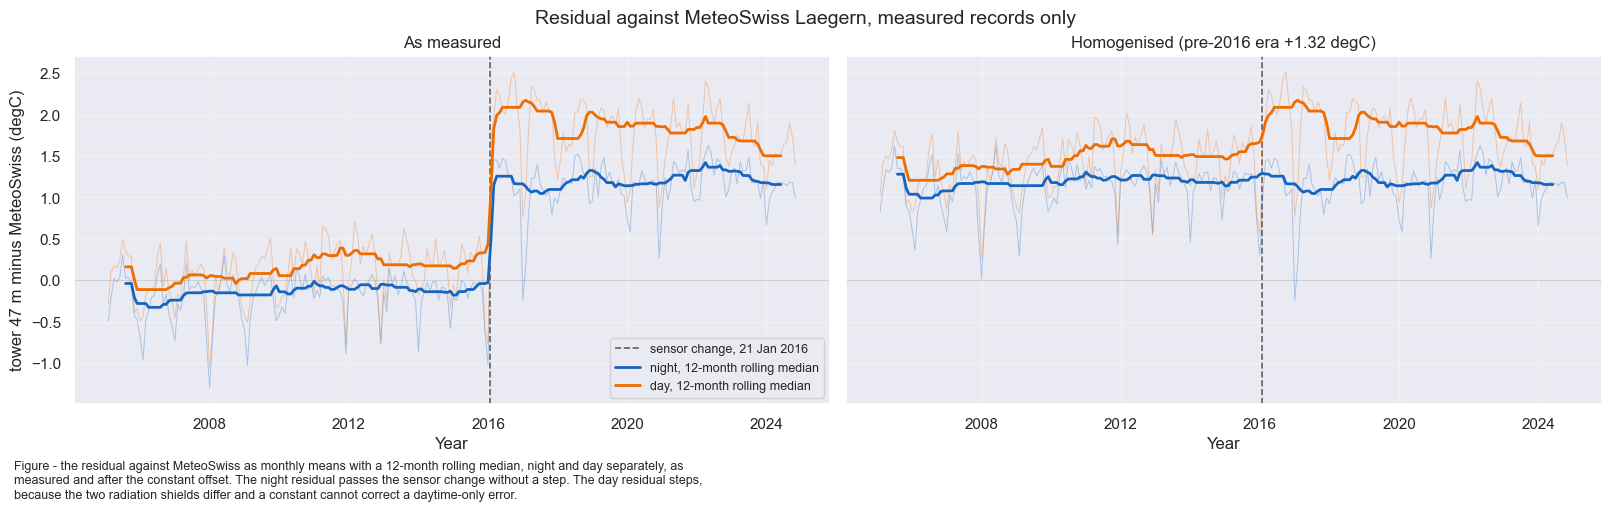

In [37]:
# The residual as monthly means with a 12-month rolling median over them, night and day drawn
# separately, before and after the correction. The rolling median is there to take the seasonal
# cycle of the difference between the two stations out of the picture; the thin line behind it is
# the monthly series it is computed from.
fig, axs = plt.subplots(ncols=2, figsize=(16, 5), dpi=100, layout="constrained", sharey=True)
fig.suptitle("Residual against MeteoSwiss Laegern, measured records only", fontsize=14)

for _ax, _col, _title in [(axs[0], 'measured', 'As measured'),
                          (axs[1], 'homogenised', f'Homogenised (pre-{BREAK.year} era {OFFSET:+.2f} degC)')]:
    _r = residual_check[_col] - residual_check['reference']
    _ax.axhline(0, color='#BDBDBD', lw=0.8, zorder=0)
    _ax.axvline(BREAK, color='#616161', lw=1.2, ls='--', zorder=1,
                label=f"sensor change, {BREAK:%d %b %Y}")
    for _label, _mask, _colour in [('night', _night, '#1565C0'), ('day', ~_night, '#EF6C00')]:
        _monthly = _r[_mask].resample('ME').mean()
        _ax.plot(_monthly.index, _monthly, color=_colour, lw=0.7, alpha=0.3, zorder=2)
        _ax.plot(_monthly.index, _monthly.rolling(12, center=True).median(), color=_colour, lw=2,
                 zorder=3, label=f"{_label}, 12-month rolling median")
    _ax.set_title(_title)
    _ax.set_xlabel("Year")
    _ax.grid(alpha=0.3)

axs[0].set_ylabel("tower 47 m minus MeteoSwiss (degC)")
axs[0].legend(fontsize=9, loc='lower right')
figcap(fig, "the residual against MeteoSwiss as monthly means with a 12-month rolling median, "
            "night and day separately, as measured and after the constant offset. The night "
            "residual passes the sensor change without a step. The day residual steps, because "
            "the two radiation shields differ and a constant cannot correct a daytime-only error.")

#### 📋 Table: residual against MeteoSwiss per year

In [38]:
# The same residual per year, so that the step above can be read against the ordinary
# year-to-year variation of the difference between two stations 2.5 km apart.
_res_h = residual_check['residual']
_year = _res_h.index.year
residual_per_year = pd.DataFrame({
    'night (degC)': _res_h[_night].groupby(_year[_night]).mean(),
    'day (degC)': _res_h[~_night].groupby(_year[~_night]).mean(),
    'all hours (degC)': _res_h.groupby(_year).mean(),
    'measured records': _res_h.groupby(_year).count(),
})
residual_per_year.index.name = 'YEAR'
tabcap("the residual of the homogenised column against MeteoSwiss per year, night and day. The night column carries no discontinuity at the sensor change; the day column does")
display(residual_per_year.round(2))

_night_col = residual_per_year['night (degC)']
_spread = _night_col.max() - _night_col.min()
print(f"Night residual over the whole record: {_night_col.min():.2f} to {_night_col.max():.2f} degC "
      f"(spread {_spread:.2f} degC)")
print(f"Day residual, {STEP_PRE_YEARS[0]}-{STEP_PRE_YEARS[-1]}: "
      f"{residual_per_year.loc[STEP_PRE_YEARS, 'day (degC)'].min():.2f} to "
      f"{residual_per_year.loc[STEP_PRE_YEARS, 'day (degC)'].max():.2f} degC;   "
      f"{STEP_POST_YEARS[0]}-{STEP_POST_YEARS[-1]}: "
      f"{residual_per_year.loc[STEP_POST_YEARS, 'day (degC)'].min():.2f} to "
      f"{residual_per_year.loc[STEP_POST_YEARS, 'day (degC)'].max():.2f} degC")

# The night residual of the homogenised column carries no discontinuity at the break that stands
# out from its own year-to-year variation. Stated as a comparison rather than as a threshold,
# because the threshold that matters is what the same quantity does in ordinary years.
assert abs(homogenisation_steps.loc[('night', 'homogenised'), 'step (degC)']) < _spread, (
    "the night step survives the correction at a size larger than the interannual spread of the "
    "same residual - the homogenisation is no longer supported")

Table - the residual of the homogenised column against MeteoSwiss per year, night and day. The night
column carries no discontinuity at the sensor change; the day column does



,night (degC),day (degC),all hours (degC),measured records
YEAR,,,,
2005,1.10,1.42,1.27,17486
2006,0.91,1.28,1.11,17494
2007,0.99,1.32,1.16,17507
2008,1.09,1.34,1.22,17548
2009,1.01,1.40,1.21,17036
2010,1.20,1.49,1.35,17351
2011,1.14,1.59,1.37,17499
2012,1.19,1.60,1.40,16286
2013,1.13,1.54,1.35,17434


Night residual over the whole record: 0.91 to 1.30 degC (spread 0.39 degC)
Day residual, 2013-2015: 1.47 to 1.54 degC;   2017-2019: 1.80 to 1.97 degC


The night residual crosses January 2016 without a step and stays inside its own year-to-year range
over the whole record. The daytime residual steps and stays higher, so what survives the
correction acts in daylight only. The cell below tests what it scales with.

#### 📋 Table: daytime residual by radiation, per era

In [39]:
# The homogenised residual binned by the reference station's shortwave and wind speed, over the
# three years either side used in the step table. Neither driver is measured at the tower,
# which matters for the wind (see below).
SW_BINS = [0, 50, 100, 200, 300, 450, 600, 1200]   # W m-2, incoming shortwave at the reference
WS_BINS = [0, 1.5, 2.5, 3.5, 5.0, 7.0, 25.0]       # m s-1, wind speed at the reference
STRONG_SUN = 300                                   # W m-2, above which the eras differ most

_eras = {f"MP101A {STEP_PRE_YEARS[0]}-{STEP_PRE_YEARS[-1]}": STEP_PRE_YEARS,
         f"CS215 {STEP_POST_YEARS[0]}-{STEP_POST_YEARS[-1]}": STEP_POST_YEARS}
_pre_name, _post_name = list(_eras)
_in_era = {_name: residual_check.index.year.isin(_years) for _name, _years in _eras.items()}

# By radiation, day records only.
_cols = {}
for _name, _sel in _in_era.items():
    _cols[f'{_name} (degC)'], _cols[f'n ({_name})'] = binned_residual(
        residual_check[_sel & ~_night], 'sw_reference', SW_BINS)
sw_profile = pd.DataFrame(_cols)
sw_profile['difference (degC)'] = (sw_profile[f'{_post_name} (degC)']
                                   - sw_profile[f'{_pre_name} (degC)'])
sw_profile.index.name = 'incoming shortwave at the reference (W m-2)'
tabcap("the daytime residual of the homogenised column binned by the radiation at the reference station, per era. The two eras agree in the dark and separate as the sun rises")
display(sw_profile.round(2))

Table - the daytime residual of the homogenised column binned by the radiation at the reference
station, per era. The two eras agree in the dark and separate as the sun rises



,MP101A 2013-2015 (degC),n (MP101A 2013-2015),CS215 2017-2019 (degC),n (CS215 2017-2019),difference (degC)
incoming shortwave at the reference (W m-2),,,,,
"(0, 50]",1.19,6677,1.24,6664,0.06
"(50, 100]",1.28,3613,1.44,3402,0.16
"(100, 200]",1.43,4427,1.75,4053,0.33
"(200, 300]",1.56,2931,2.08,2742,0.52
"(300, 450]",1.62,3261,2.33,3087,0.71
"(450, 600]",1.83,2282,2.47,2642,0.64
"(600, 1200]",1.94,4193,2.40,4551,0.46


#### 📋 Table: residual by wind speed, per era

In [40]:
# By wind speed, at night and in strong sun. Night is the control: whatever the wind does to the
# difference between two stations 100 m apart in elevation, it does in both eras.
_cols = {}
for _wlabel, _wsel in [('night', _night),
                       (f'day, > {STRONG_SUN} W m-2',
                        ~_night & (residual_check['sw_reference'] > STRONG_SUN))]:
    _means = {}
    for _name, _sel in _in_era.items():
        _short = _name.split()[0]
        _cols[f'{_wlabel}, {_short} (degC)'], _ = binned_residual(
            residual_check[_sel & _wsel], 'ws_reference', WS_BINS)
        _means[_short] = _cols[f'{_wlabel}, {_short} (degC)']
    _cols[f'{_wlabel}, difference (degC)'] = (_means[_post_name.split()[0]]
                                              - _means[_pre_name.split()[0]])
ws_profile = pd.DataFrame(_cols)
ws_profile.index.name = 'wind speed at the reference (m s-1)'
tabcap("the same residual binned by the wind speed at the reference station, at night and in strong sun. The reference wind does not separate the eras at either level of radiation")
display(ws_profile.round(2))

Table - the same residual binned by the wind speed at the reference station, at night and in strong
sun. The reference wind does not separate the eras at either level of radiation



,"night, MP101A (degC)","night, CS215 (degC)","night, difference (degC)","day, > 300 W m-2, MP101A (degC)","day, > 300 W m-2, CS215 (degC)","day, > 300 W m-2, difference (degC)"
wind speed at the reference (m s-1),,,,,,
"(0.0, 1.5]",0.94,0.76,-0.17,1.24,1.79,0.55
"(1.5, 2.5]",0.87,0.74,-0.12,1.56,2.28,0.72
"(2.5, 3.5]",0.95,0.85,-0.10,1.90,2.50,0.60
"(3.5, 5.0]",1.11,1.04,-0.06,2.04,2.66,0.61
"(5.0, 7.0]",1.21,1.28,0.07,2.18,2.75,0.57
"(7.0, 25.0]",1.23,1.34,0.12,2.06,2.68,0.62


#### 📊 Plot: era difference by radiation and wind speed


Era difference at 0-50 W m-2: +0.06 degC;   largest of the radiation bins: +0.71 degC
Era difference by wind speed - night: -0.17 to +0.12 degC;   strong sun: +0.55 to +0.72 degC


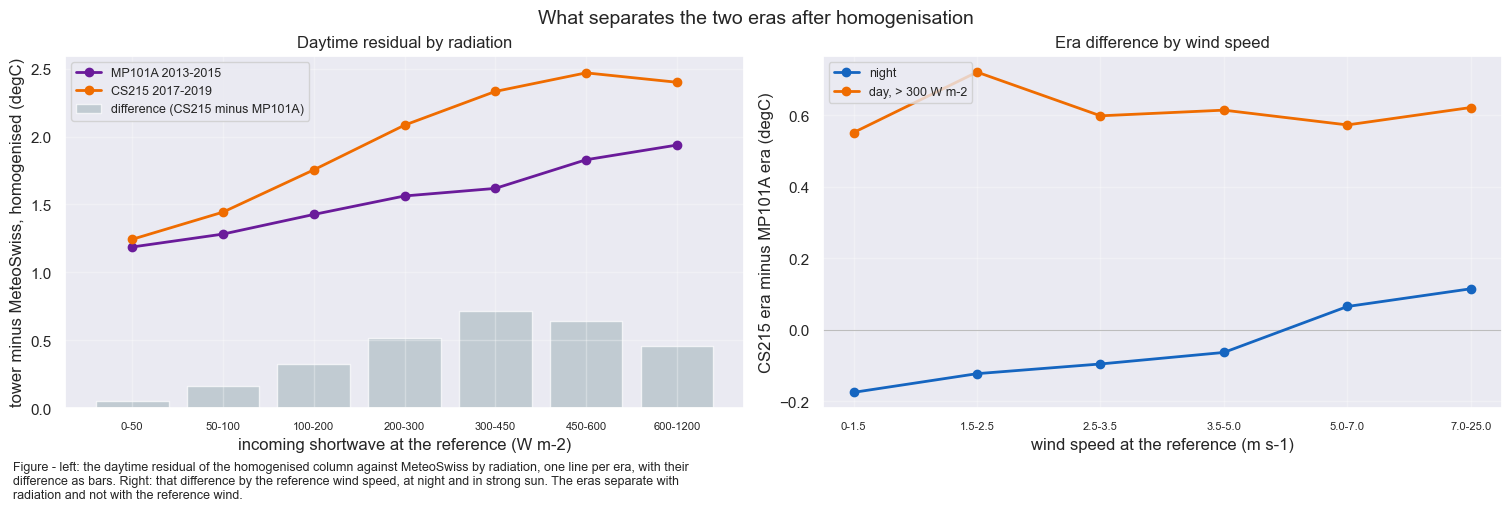

In [41]:
fig, axs = plt.subplots(ncols=2, figsize=(15, 5), dpi=100, layout="constrained")
fig.suptitle("What separates the two eras after homogenisation", fontsize=14)

_x = np.arange(len(sw_profile))
axs[0].axhline(0, color='#BDBDBD', lw=0.8)
axs[0].bar(_x, sw_profile['difference (degC)'], color='#B0BEC5', alpha=0.7, zorder=0,
           label='difference (CS215 minus MP101A)')
for _name, _colour in [(_pre_name, '#6A1B9A'), (_post_name, '#EF6C00')]:
    axs[0].plot(_x, sw_profile[f'{_name} (degC)'], 'o-', color=_colour, lw=2, zorder=2, label=_name)
axs[0].set_xticks(_x)
axs[0].set_xticklabels([f"{_a}-{_b}" for _a, _b in zip(SW_BINS[:-1], SW_BINS[1:])], fontsize=8)
axs[0].set_xlabel("incoming shortwave at the reference (W m-2)")
axs[0].set_ylabel("tower minus MeteoSwiss, homogenised (degC)")
axs[0].set_title("Daytime residual by radiation")
axs[0].grid(alpha=0.3)
axs[0].legend(fontsize=9, loc='upper left')

_x = np.arange(len(ws_profile))
axs[1].axhline(0, color='#BDBDBD', lw=0.8)
for _wlabel, _colour in [('night', '#1565C0'), (f'day, > {STRONG_SUN} W m-2', '#EF6C00')]:
    axs[1].plot(_x, ws_profile[f'{_wlabel}, difference (degC)'], 'o-', color=_colour, lw=2,
                label=_wlabel)
axs[1].set_xticks(_x)
axs[1].set_xticklabels([f"{_a}-{_b}" for _a, _b in zip(WS_BINS[:-1], WS_BINS[1:])], fontsize=8)
axs[1].set_xlabel("wind speed at the reference (m s-1)")
axs[1].set_ylabel("CS215 era minus MP101A era (degC)")
axs[1].set_title("Era difference by wind speed")
axs[1].grid(alpha=0.3)
axs[1].legend(fontsize=9, loc='upper left')
figcap(fig, "left: the daytime residual of the homogenised column against MeteoSwiss by "
            "radiation, one line per era, with their difference as bars. Right: that difference "
            "by the reference wind speed, at night and in strong sun. The eras separate with "
            "radiation and not with the reference wind.")

# The mechanism, asserted. In the dark the two eras agree; in sun they do not, and the separation
# grows with radiation. If that ordering ever reverses, the residual is not radiative and the
# paragraphs around this cell are wrong.
_dark = sw_profile['difference (degC)'].iloc[0]
_sunlit = sw_profile['difference (degC)'].max()
print(f"\nEra difference at {SW_BINS[0]}-{SW_BINS[1]} W m-2: {_dark:+.2f} degC;   "
      f"largest of the radiation bins: {_sunlit:+.2f} degC")
assert abs(_dark) < 0.2, "the two eras differ in the dark as well - the residual is not radiative"
assert _sunlit > 0.4, "the daytime era difference has gone - the text around this cell must be re-derived"

# The reference station's wind does not separate the eras at either level of radiation: at night
# the difference is near zero at every wind speed, and in strong sun it is near constant. That is
# not evidence against a ventilation effect at the tower, it is the reference wind failing to
# stand in for one - MeteoSwiss Laegern sits on the ridge, 2.5 km away and about 100 m higher.
_night_by_ws = ws_profile['night, difference (degC)']
_sun_by_ws = ws_profile[f'day, > {STRONG_SUN} W m-2, difference (degC)']
print(f"Era difference by wind speed - night: {_night_by_ws.min():+.2f} to {_night_by_ws.max():+.2f} degC;   "
      f"strong sun: {_sun_by_ws.min():+.2f} to {_sun_by_ws.max():+.2f} degC")
assert _night_by_ws.abs().max() < 0.25, \
    "the night era difference depends on the reference wind - the night result is not clean"
assert _sun_by_ws.min() > 0.3, \
    "the daytime era difference vanishes at some wind speed - the reading below no longer holds"

The daytime residual scales with incoming radiation. The eras agree in the darkest bin, as at
night, and separate as radiation rises, most in the middle of the range and somewhat less in the
brightest bin. This is the signature of a radiation-shield difference: the CS215 sits in a passive
shield, the MP101A was shielded differently, and a difference between them can appear only in
sunlight. The constant cannot remove it.

The reference wind speed separates the eras neither at night nor in strong sun. This does not rule
out a ventilation effect at the tower, because MeteoSwiss Lägern sits on the ridge 2.5 km away and
about 100 m higher. The residual rises with that wind in both eras (two stations at different
elevations agree more closely in well-mixed air), and the rise cancels in the era difference. The
ventilation behaviour of the CS215 is measured against NABEL and stated in the limitation below.

### 🔟 Removing what a constant cannot: the shield term

NABEL at 49 m is aspirated, so its own radiative error is negligible, and it overlaps eleven years
of the MP101A and three of the CS215. The difference `47 m − NABEL` as a function of the tower's
incoming shortwave is therefore the **radiation-shield response** of the sensor in place.

Removing the **radiation-dependent part of the difference between the two responses** puts the
CS215 era onto the MP101A era's shield behaviour, and the constant of step 8️⃣ keeps one night
level. The exported column thus has the night level of the CS215 era and the daytime behaviour of
the MP101A era. The MP101A's own shield error remains in both eras, so the record is
self-consistent across the sensor change but not corrected to an aspirated measurement.

`TA_HOMOGENIZATION_OPTIONS.ipynb` scores the alternatives, chooses the polynomial order and tests
the objections to fitting the CS215 era on three years. Only the checks that must hold on **this**
run are repeated here.

In [42]:
# Gap-filled SW_IN from notebook 01. It is loaded here rather than in the Drivers section below,
# because the shield term is a function of it; the Drivers section then reuses this object.
swin_gf = dv.load_parquet(filepath=str(Path(OUTPATH) / f"{SWIN_FILE}.parquet"))
print(f"Loaded {SWIN_FILE}: {list(swin_gf.columns)}")
print(f"  {swin_gf.index[0]} -> {swin_gf.index[-1]} ({len(swin_gf):,} records)")
assert swin_gf[SWIN_COL].notna().all(), "the SW_IN product has gaps, so the shield term cannot be applied everywhere"

# The fit set: measured tower TA, measured NABEL and the tower's own radiation. Measured records
# only - a modelled one would report what the gap-filler was told about the eras.
shield_fit = pd.concat([ta_2004_2026[['TA_T1_47_1', 'TA_NABEL_T1_49_1']],
                        swin_gf[SWIN_COL]], axis=1).dropna()
shield_fit['bias'] = shield_fit['TA_T1_47_1'] - shield_fit['TA_NABEL_T1_49_1']
shield_fit['era'] = np.where(shield_fit.index < BREAK, 'MP101A', 'CS215')

# The order is chosen in TA_HOMOGENIZATION_OPTIONS.ipynb, on the held-out error over the three
# NABEL years of the CS215 era and on how far the curve departs from that era's own binned means.
# The second of those is re-checked below, because it is the one a changed record can invalidate.
SHIELD_ORDER = 2
SHIELD_BINS = [0, 25, 75, 150, 250, 350, 450, 550, 650, 800, 1200]
SHAPE_TOLERANCE = 0.15   # degC, largest allowed departure from an era's own binned means

print(f"\nshield fit rows: {len(shield_fit):,} "
      f"({shield_fit.index[0]:%Y-%m} to {shield_fit.index[-1]:%Y-%m})")
print(shield_fit.groupby('era').size().rename('records').to_string())
assert set(shield_fit['era']) == {'MP101A', 'CS215'}, "the shield fit set does not cover both eras"
assert shield_fit.index.max() < EXCESS_START, \
    "the shield fit holds a record of code 7, 6 or 4, which its two era labels do not describe"
assert shield_fit.groupby('era').size().min() > 20_000, "one era has too few records to fit"


def shield_basis(sw, order=None):
    """Polynomial design matrix in incoming shortwave, scaled to kW m-2 so the powers stay conditioned."""
    _x = np.asarray(sw, dtype=float) / 1000.0
    _order = SHIELD_ORDER if order is None else order
    return np.column_stack([_x ** _k for _k in range(1, _order + 1)] + [np.ones(len(_x))])


def fit_shield(frame):
    """Least-squares shield response against NABEL, per era. Raises on an era the frame lacks."""
    _coef = {}
    for _era in ('MP101A', 'CS215'):
        _g = frame[frame['era'] == _era]
        if len(_g) < 5_000:
            raise ValueError(f"era {_era} holds {len(_g)} rows, too few to fit a shield response")
        _beta, *_ = np.linalg.lstsq(shield_basis(_g[SWIN_COL]), _g['bias'].to_numpy(), rcond=None)
        _coef[_era] = _beta
    return _coef


def binned_shield(frame):
    """Mean bias, mean radiation and record count per radiation bin, for one era.

    The mean radiation of each bin is returned rather than the bin centre: the top bin spans
    400 W m-2 and its records sit near its lower edge, so testing or drawing it at the centre
    would place it where nothing was measured.
    """
    _g = frame.groupby(pd.cut(frame[SWIN_COL], SHIELD_BINS), observed=False)
    return pd.DataFrame({'sw': _g[SWIN_COL].mean(), 'bias': _g['bias'].mean(),
                         'records': _g['bias'].size()})

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\01_METEO_SW_IN_GAPFILLED_2004-2026.09.parquet (0.013 seconds).

Loaded 01_METEO_SW_IN_GAPFILLED_2004-2026.09: ['SW_IN_T1_47_1_gfXG', 'FLAG_SW_IN_T1_47_1_ISFILLED']
  2004-01-01 00:15:00 -> 2026-09-30 23:45:00 (398,832 records)

shield fit rows: 246,660 (2004-09 to 2018-12)
era
CS215      51600
MP101A    195060


In [43]:
# The guard guards: an era the frame does not cover must raise, not silently return one era's fit
# for both - which would make the correction below exactly zero and look like success.
try:
    fit_shield(shield_fit[shield_fit['era'] == 'MP101A'])
except ValueError as _e:
    print(f"fit_shield raises when an era is absent: {_e}")
else:
    raise AssertionError("fit_shield accepted a frame holding only one era")

fit_shield raises when an era is absent: era CS215 holds 0 rows, too few to fit a shield response


#### 📋 Table: fitted shield response per sensor era

In [44]:
SHIELD = fit_shield(shield_fit)
# Beyond the radiation the fit saw, the polynomial says nothing, so it is not asked: the driver is
# clipped to the 99.9th percentile of the fitted range and the response is held flat above it.
SHIELD_SW_MAX = float(shield_fit[SWIN_COL].quantile(0.999))


def shield_bias(era, sw):
    """The fitted bias of `era` against the aspirated sensor, at one or more levels of radiation."""
    return shield_basis(np.clip(np.atleast_1d(sw), 0.0, SHIELD_SW_MAX)) @ SHIELD[era]


_rows = []
for _era in ('MP101A', 'CS215'):
    _rows.append({'era': _era, 'records': int((shield_fit['era'] == _era).sum()),
                  'bias at 0 W m-2 (degC)': shield_bias(_era, 0)[0],
                  'bias at 400 W m-2 (degC)': shield_bias(_era, 400)[0],
                  'bias at 800 W m-2 (degC)': shield_bias(_era, 800)[0]})
shield_table = pd.DataFrame(_rows).set_index('era')
shield_table['rise from 0 to 800 (degC)'] = (shield_table['bias at 800 W m-2 (degC)']
                                             - shield_table['bias at 0 W m-2 (degC)'])
tabcap("the fitted shield response of each sensor era against the aspirated NABEL sensor. The "
       "difference of the intercepts is the zero-point error the constant removes; the "
       "difference of the rises is what it cannot remove")
display(shield_table.round(3))

print(f"radiation the fit saw, 99.9th percentile: {SHIELD_SW_MAX:.0f} W m-2 (the response is held "
      f"flat above it)")
print("zero-point difference between the eras: "
      f"{shield_table.loc['CS215', 'bias at 0 W m-2 (degC)'] - shield_table.loc['MP101A', 'bias at 0 W m-2 (degC)']:+.2f} degC "
      f"against the constant of {OFFSET:+.2f} degC derived in step 8")
print("difference in the rise from 0 to 800 W m-2:  "
      f"{shield_table.loc['CS215', 'rise from 0 to 800 (degC)'] - shield_table.loc['MP101A', 'rise from 0 to 800 (degC)']:+.2f} degC")

# Both sensors must read warm relative to an aspirated one as radiation rises, and the CS215 must
# do so more. If either failed, the correction below would have the wrong sign.
for _era in ('MP101A', 'CS215'):
    assert shield_table.loc[_era, 'rise from 0 to 800 (degC)'] > 0, \
        f"the {_era} era does not warm in sun relative to the aspirated sensor"
assert (shield_table.loc['CS215', 'rise from 0 to 800 (degC)']
        > shield_table.loc['MP101A', 'rise from 0 to 800 (degC)']), \
    "the CS215 no longer warms more in sun than the MP101A - the correction would reverse sign"

# And the chosen order still describes the data. This is the check the order was selected on in
# the companion notebook, repeated here so a changed record cannot invalidate it silently.
for _era in ('MP101A', 'CS215'):
    _obs = binned_shield(shield_fit[shield_fit['era'] == _era])
    _departure = np.abs(shield_bias(_era, _obs['sw']) - _obs['bias'])
    print(f"  {_era:7s} largest departure from its own binned means: {_departure.max():.3f} degC")
    assert _departure.max() < SHAPE_TOLERANCE, (
        f"the fitted {_era} response departs from its own binned means by {_departure.max():.2f} "
        f"degC - order {SHIELD_ORDER} no longer describes the data and must be re-chosen in "
        f"TA_HOMOGENIZATION_OPTIONS.ipynb")

Table - the fitted shield response of each sensor era against the aspirated NABEL sensor. The
difference of the intercepts is the zero-point error the constant removes; the difference of the
rises is what it cannot remove



,records,bias at 0 W m-2 (degC),bias at 400 W m-2 (degC),bias at 800 W m-2 (degC),rise from 0 to 800 (degC)
era,,,,,
MP101A,195060,-1.089,-0.614,-0.676,0.413
CS215,51600,0.251,1.267,1.139,0.888


radiation the fit saw, 99.9th percentile: 980 W m-2 (the response is held flat above it)
zero-point difference between the eras: +1.34 degC against the constant of +1.32 degC derived in step 8
difference in the rise from 0 to 800 W m-2:  +0.48 degC
  MP101A  largest departure from its own binned means: 0.056 degC
  CS215   largest departure from its own binned means: 0.108 degC


#### 📊 Plot: shield response per sensor era

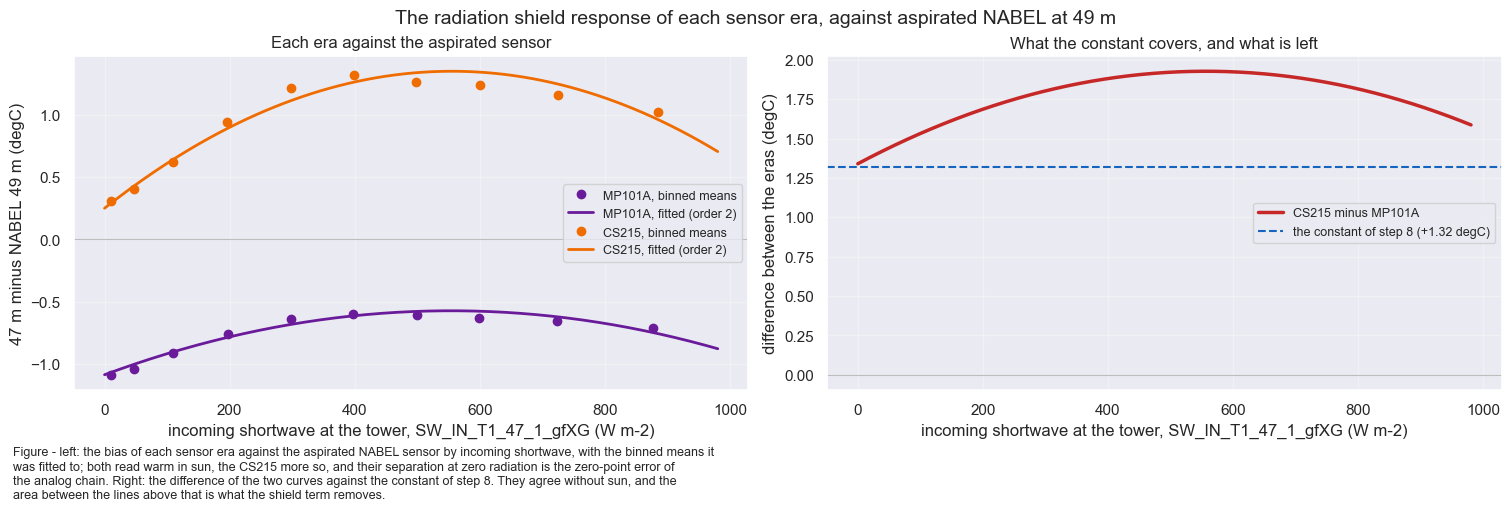

In [45]:
# The shield response, drawn against the binned data it was fitted to. The curves are drawn only
# over the range the fit saw, and the binned means at each bin's own mean radiation.
_grid = np.linspace(0, SHIELD_SW_MAX, 200)
fig, axs = plt.subplots(ncols=2, figsize=(15, 5), dpi=100, layout="constrained")
fig.suptitle("The radiation shield response of each sensor era, against aspirated NABEL at 49 m",
             fontsize=14)

for _era, _colour in [('MP101A', '#6A1B9A'), ('CS215', '#EF6C00')]:
    _obs = binned_shield(shield_fit[shield_fit['era'] == _era])
    axs[0].plot(_obs['sw'], _obs['bias'], 'o', color=_colour, ms=6, label=f"{_era}, binned means")
    axs[0].plot(_grid, shield_bias(_era, _grid), '-', color=_colour, lw=2,
                label=f"{_era}, fitted (order {SHIELD_ORDER})")
axs[0].axhline(0, color='#BDBDBD', lw=0.8)
axs[0].set_xlabel(f"incoming shortwave at the tower, {SWIN_COL} (W m-2)")
axs[0].set_ylabel("47 m minus NABEL 49 m (degC)")
axs[0].set_title("Each era against the aspirated sensor")
axs[0].grid(alpha=0.3)
axs[0].legend(fontsize=9)

axs[1].plot(_grid, shield_bias('CS215', _grid) - shield_bias('MP101A', _grid), color='#C62828',
            lw=2.5, label='CS215 minus MP101A')
axs[1].axhline(OFFSET, color='#1565C0', lw=1.5, ls='--',
               label=f"the constant of step 8 ({OFFSET:+.2f} degC)")
axs[1].axhline(0, color='#BDBDBD', lw=0.8)
axs[1].set_xlabel(f"incoming shortwave at the tower, {SWIN_COL} (W m-2)")
axs[1].set_ylabel("difference between the eras (degC)")
axs[1].set_title("What the constant covers, and what is left")
axs[1].grid(alpha=0.3)
axs[1].legend(fontsize=9)
figcap(fig, "left: the bias of each sensor era against the aspirated NABEL sensor by incoming "
            "shortwave, with the binned means it was fitted to; both read warm in sun, the CS215 "
            "more so, and their separation at zero radiation is the zero-point error of the analog "
            "chain. Right: the difference of the two curves against the constant of step 8. They "
            "agree without sun, and the area between the lines above that is what the shield term "
            "removes.")

#### 📋 Table: step against MeteoSwiss at three correction stages

In [46]:
# The correction. Two terms acting on different eras, and neither touches the other's records. Two
# more are derived later and act on their own eras only: the night term of the CS215 after its
# change of May 2025 (step 11), and the transfer of the HygroVUE10 that replaced it in June 2026
# (step 12). Until those steps have run, C6_TERMS and HV_TERMS are empty and homogenize() refuses
# the records they describe rather than passing them through on the correction of another era.
def radiative_excess(sw):
    """The radiation-dependent part of the CS215-minus-MP101A difference, in degC.

    Zero where there is no sun, by construction: the zero-radiation part of that difference is the
    zero-point error of the analog chain, which OFFSET already removes. Subtracting it here as well
    would correct the night twice.
    """
    _x = shield_basis(np.clip(np.atleast_1d(sw), 0.0, SHIELD_SW_MAX))
    _x0 = shield_basis(np.zeros(len(np.atleast_1d(sw))))
    return (_x - _x0) @ (SHIELD['CS215'] - SHIELD['MP101A'])


C6_TERMS = None   # the night term of the CS215 after the May 2025 change, set in step 11
HV_TERMS = None   # the HygroVUE10 transfer, set in step 12


def hv_excess(sw, terms=None):
    """The radiation-dependent part of the HygroVUE10-minus-CS215 difference, in degC.

    Built like radiative_excess(): the same basis, the driver clipped to the radiation range both
    samples were fitted on, and zero where there is no sun by construction. `terms` defaults to
    the fit of step 12; the month hold-out there passes its own refits.
    """
    _t = HV_TERMS if terms is None else terms
    if _t is None:
        raise RuntimeError("the HygroVUE10 terms are derived in step 12, which has not run yet")
    _sw = np.atleast_1d(np.asarray(sw, dtype=float))
    _x = shield_basis(np.clip(_sw, 0.0, _t['sw_max']))
    _x0 = shield_basis(np.zeros(len(_sw)))
    return (_x - _x0) @ (_t['beta_hv'] - _t['beta_cs'])


def homogenize(values, index, sw):
    """The homogenised series: one night level and one daytime shield behaviour for all eras.

    By time, so a modelled record is corrected as the period that modelled it:
    - before BREAK (MP101A, the changeover outage): the constant;
    - BREAK to RESET_START (CS215 codes 0 and 7, and the handling record): the shield term;
    - RESET_START to HV_START (CS215 code 6, and the probe swap record): the constant night term of
      step 11 only, since the CS215 no longer carries the shield excess the shield term removes;
    - from HV_START (HygroVUE10): hv_excess and the night term of step 12, then the shield term.
    """
    _index = pd.DatetimeIndex(index)
    _sw = np.atleast_1d(np.asarray(sw, dtype=float))
    _c6 = np.asarray((_index >= RESET_START) & (_index < HV_START))
    _hv = np.asarray(_index >= HV_START)
    _out = np.asarray(values, dtype=float) + np.where(_index < BREAK, OFFSET, 0.0)
    _out = _out - np.where(np.asarray(_index >= BREAK) & ~_c6, radiative_excess(_sw), 0.0)
    if _c6.any():
        if C6_TERMS is None:
            raise RuntimeError(f"{int(_c6.sum())} records of the CS215 after May 2025 passed to "
                               f"homogenize() before step 11 has derived their term")
        _out = _out - np.where(_c6, C6_TERMS['night'], 0.0)
    if _hv.any():
        if HV_TERMS is None:
            raise RuntimeError(f"{int(_hv.sum())} HygroVUE10 records passed to homogenize() before "
                               f"step 12 has derived their terms")
        _out = _out - np.where(_hv, hv_excess(_sw) + HV_TERMS['night'], 0.0)
    return _out


# The guard guards. At zero radiation the excess must be exactly zero, or every night record of
# the CS215 era would move and the constant of step 8 would be corrected twice.
assert abs(radiative_excess([0.0])[0]) < 1e-12, \
    "the radiative term is not zero in the dark - it would correct the night level a second time"
# And it must be positive in sun: the CS215 reads warmer than the MP101A there, so the correction
# can only ever cool the later era.
_probe = radiative_excess(np.linspace(0, SHIELD_SW_MAX, 50))
assert (_probe >= -1e-9).all(), \
    "the radiative term turns negative inside the fitted range - it would warm the CS215 era"
print(f"radiative excess of the CS215 shield: 0.00 degC in the dark, "
      f"{_probe.max():+.2f} degC at most, at {np.linspace(0, SHIELD_SW_MAX, 50)[_probe.argmax()]:.0f} W m-2")

# What it does to the residual of step 9, on measured records only and against MeteoSwiss - which
# entered neither the constant nor the shield fit.
residual_check['shield'] = homogenize(residual_check['measured'],
                                      residual_check.index,
                                      swin_gf[SWIN_COL].reindex(residual_check.index))
_rows = []
for _wname, _wmask in _windows:
    for _col in ['measured', 'homogenised', 'shield']:
        _n, _a, _b = residual_step(residual_check[_col] - residual_check['reference'], _wmask,
                                   STEP_PRE_YEARS, STEP_POST_YEARS)
        _rows.append({'window': _wname, 'column': _col, _pre_label: _a, _post_label: _b,
                      'step (degC)': _b - _a, 'records': _n})
shield_steps = pd.DataFrame(_rows).set_index(['window', 'column'])
tabcap("the step across the sensor change against MeteoSwiss as measured, after the constant "
       "alone, and after the constant and the shield term. 'shield' is the column exported below")
display(shield_steps.round(2))

_day_before = shield_steps.loc[('day', 'homogenised'), 'step (degC)']
_day_after = shield_steps.loc[('day', 'shield'), 'step (degC)']
_night_after = shield_steps.loc[('night', 'shield'), 'step (degC)']
print(f"\nDaytime step: {_day_before:+.2f} degC with the constant alone, {_day_after:+.2f} degC "
      f"with the shield term as well.")
print(f"Night step:   {_night_after:+.2f} degC, unchanged by the shield term as it must be.")

# The shield term must not undo what step 8 achieved at night.
assert abs(_night_after - shield_steps.loc[('night', 'homogenised'), 'step (degC)']) < 0.02, \
    "the shield term moved the night step, which it is defined not to do"
# And it must remove most of the daytime step, or it is not worth the column it changes.
assert abs(_day_after) < 0.5 * abs(_day_before), (
    f"the shield term reduces the daytime step from {_day_before:+.2f} to only {_day_after:+.2f} "
    f"degC - less than half, which is not what TA_HOMOGENIZATION_OPTIONS.ipynb measured")

radiative excess of the CS215 shield: 0.00 degC in the dark, +0.59 degC at most, at 560 W m-2
Table - the step across the sensor change against MeteoSwiss as measured, after the constant alone,
and after the constant and the shield term. 'shield' is the column exported below



2013-2015 (degC)  2017-2019 (degC)  step (degC)  records
window    column                                                               
night     measured                -0.21              1.10         1.31    49680
          homogenised              1.11              1.10        -0.01    49680
          shield                   1.11              1.10        -0.01    49680
day       measured                 0.18              1.87         1.69    54532
          homogenised              1.50              1.87         0.37    54532
          shield                   1.50              1.56         0.06    54532
all hours measured                -0.01              1.50         1.51   104212
          homogenised              1.31              1.50         0.19   104212
          shield                   1.31              1.34         0.03   104212


Daytime step: +0.37 degC with the constant alone, +0.06 degC with the shield term as well.
Night step:   -0.01 degC, unchanged by the shield term as it must be.


#### 📊 Plot: residual against MeteoSwiss at three correction stages

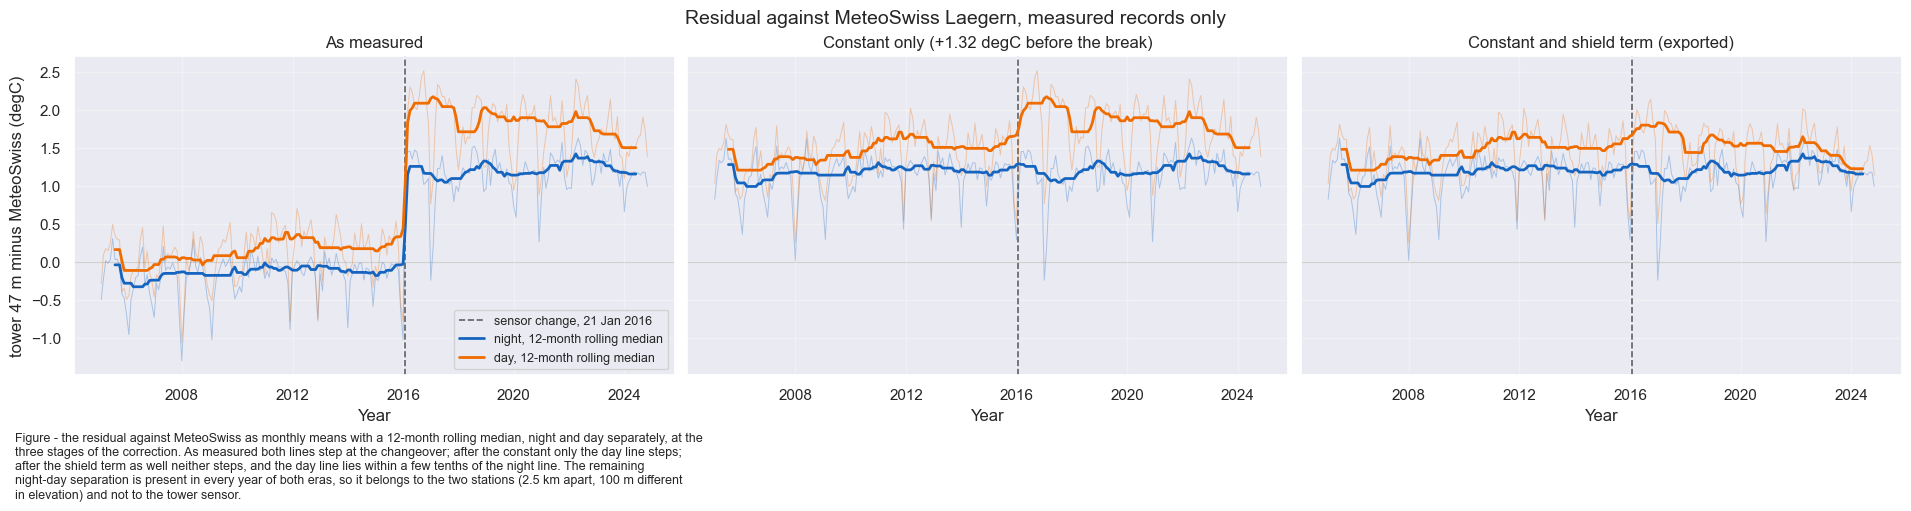

In [47]:
# The figure of step 9, redrawn with the shield term added as a third panel. Same axes, same
# night/day split, same reference - so the three panels are the record before any correction,
# after the constant, and after both terms, and can be read across.
fig, axs = plt.subplots(ncols=3, figsize=(19, 5), dpi=100, layout="constrained", sharey=True)
fig.suptitle("Residual against MeteoSwiss Laegern, measured records only", fontsize=14)

for _ax, _col, _title in [
        (axs[0], 'measured', 'As measured'),
        (axs[1], 'homogenised', f'Constant only ({OFFSET:+.2f} degC before the break)'),
        (axs[2], 'shield', 'Constant and shield term (exported)')]:
    _r = residual_check[_col] - residual_check['reference']
    _ax.axhline(0, color='#BDBDBD', lw=0.8, zorder=0)
    _ax.axvline(BREAK, color='#616161', lw=1.2, ls='--', zorder=1,
                label=f"sensor change, {BREAK:%d %b %Y}")
    for _label, _mask, _colour in [('night', _night, '#1565C0'), ('day', ~_night, '#EF6C00')]:
        _monthly = _r[_mask].resample('ME').mean()
        _ax.plot(_monthly.index, _monthly, color=_colour, lw=0.7, alpha=0.3, zorder=2)
        _ax.plot(_monthly.index, _monthly.rolling(12, center=True).median(), color=_colour, lw=2,
                 zorder=3, label=f"{_label}, 12-month rolling median")
    _ax.set_title(_title)
    _ax.set_xlabel("Year")
    _ax.grid(alpha=0.3)

axs[0].set_ylabel("tower 47 m minus MeteoSwiss (degC)")
axs[0].legend(fontsize=9, loc='lower right')
figcap(fig, "the residual against MeteoSwiss as monthly means with a 12-month rolling median, "
            "night and day separately, at the three stages of the correction. As measured both "
            "lines step at the changeover; after the constant only the day line steps; after the "
            "shield term as well neither steps, and the day line lies within a few tenths of the "
            "night line. The remaining night-day separation is present in every year of both eras, "
            "so it belongs to the two stations (2.5 km apart, 100 m different in elevation) and "
            "not to the tower sensor.")

The shield term removes most of the daytime step that the constant leaves, and the night step is
unchanged. What remains is the ordinary disagreement between two stations 2.5 km apart. It still
rises with radiation in both eras, because the MP101A's own shield error is present in both.

### 1️⃣1️⃣ The May 2025 change

Between the 2016 break and the probe change of 2026 the CS215 itself changed once, on
**16 May 2025**, and before that read abnormally warm in sun from autumn 2024. The field
name and the database tags did not change.

**What happened.**

- **19 September 2024.** The fieldbook records intake tubing from the tower attached at the 47 m
  sonic. Over the following weeks the daytime excess of the probe over the 35 m sensor of the
  same tower grows beyond anything it shows before (code `7`, dated by the rule below).
- **16 May 2025, 09:30 to 10:00.** The raw 1-minute `TA_T1_47_1` jumps by about 5 °C between
  09:32 and 09:42 (`TIMESTAMP_END`) while the 35 m sensor does not: the probe was handled. The
  fieldbook records a site visit that day, with the heating connection of the tower inlet found
  melted and disconnected. This half-hour is removed in *Corrections* and carries source code
  `5`. From the next half-hour on (code `6`), the daytime excess is gone, and the CS215 as
  measured reads close to the normal CS215 after the shield term of step 🔟.

**The evidence** below is computed against two references: the 35 m sensor of the same tower
(`TA_T1_35_1`, raw, see *Data sources*), and the pair of that sensor against Lägern as a witness,
which holds no 47 m measurement and so cannot step at a change of the 47 m probe.

**The correction.**

- **Code 0** (normal CS215) and **code 7**: the shield term of step 🔟. Code 7 is not corrected
  further, so in sun it stays too warm (measured below).
- **Code 6**: no shield term. The change is established, so its night level is corrected: a
  constant equal to its night difference against the normal CS215 of the HygroVUE10 comparison
  years, against Lägern, matched month by month. Its uncertainty is the year-to-year scatter of
  the same quantity among those years.

In [48]:
# The two fieldbook entries that bracket the excess heating. TUBING_DATE and HANDLING_RECORD are
# settings; here they are checked against the entries, so a mistyped date fails. `fb` is the
# redacted export read in step 6. Neither entry names the temperature probe: the first is filed
# under the sonic at 47 m, the second carries no device at all.
_tubing = fb[(fb['Date'] == TUBING_DATE)
             & fb['Location'].astype(str).str.contains('T1_47', regex=False)
             & fb['text'].str.contains('intake tubing', case=False, regex=False)]
_heating = fb[(fb['Date'] == HANDLING_RECORD.normalize())
              & fb['text'].str.contains('inlet', case=False, regex=False)
              & fb['text'].str.contains('heating', case=False, regex=False)]
for _label, _rows in [('intake tubing at 47 m', _tubing), ('inlet heating disconnected', _heating)]:
    print(f"--- {_label}")
    for _, _r in _rows.drop_duplicates('text').iterrows():
        print(f"    {_r['Date'].date()}  {_r['Event Tag']:7s} {_r['Device Model']}: {_r['text'][:300]}")
assert len(_tubing) > 0, f"no fieldbook entry on {TUBING_DATE.date()} attaches intake tubing at T1_47"
assert len(_heating) > 0, \
    f"no fieldbook entry on {HANDLING_RECORD.date()} disconnects the heating of the tower inlet"
# The CS215 itself is never registered at T1_47 (step 12), so no entry names it.
assert not (fb['Location'].astype(str).str.contains('T1_47', regex=False)
            & fb['Device Model'].astype(str).str.contains('CS215', regex=False)).any(), \
    "the fieldbook now registers a CS215 at T1_47 - its entries may date the change and must be read"

--- intake tubing at 47 m
    2024-09-19  HW_MOD  HS-50 Head: Worked in the hut: moved pump to pump house drilled hole to pump house mounted hose to backwall inserted sonic Y-cable attached intake tubing from tower
--- inlet heating disconnected
    2025-05-16  HW_MOD  na: Exchanged filters: 2 um at instrument 15 um at inlet on tower the heating connection was melted (see images) small leakage possible thus, heating disconnected and switched off


#### 📋 Table: the 16 May 2025 step, tower pair and witness pair

In [49]:
# Three pairs on measured records: the 47 m CS215 against the 35 m sensor of the same tower, the
# 35 m sensor against Laegern (the witness pair, which contains no 47 m measurement), and the 47 m
# sensor against Laegern. Classes on tower SW_IN: night, 200-500 and above 500 W m-2.
MAY_SW_BINS = [0, 200, 350, 500, 650, 1200]   # W m-2, Laegern shortwave by day, as in step 12
MAY_STEP_DAYS = 14                            # days either side of a candidate split
MAY_SCAN = ('2025-03-01', '2025-09-01')       # candidate days for the split, around the handling
PAIRS = {'TA 47 m - TA 35 m': ('tower', 'witness'),
         'TA 35 m - Laegern': ('witness', 'reference'),
         'TA 47 m - Laegern': ('tower', 'reference')}
PAIR_CLASSES = ['night', 'SW_IN 200-500', 'SW_IN > 500']

pair_frame = pd.DataFrame({
    'tower': evidence['TA_T1_47_1'],
    'witness': witness_ta.reindex(evidence.index),
    'reference': evidence[REFCOL],
    'sw': swin_gf[SWIN_COL].reindex(evidence.index),
    'sw_reference': evidence[REFCOL_SW],
    'source': source_flag.reindex(evidence.index),
})
pair_frame = pair_frame.loc[witness_ta.first_valid_index():]
pair_frame['night'] = NIGHT.reindex(pair_frame.index).fillna(False).astype(bool)
for _name, (_a, _b) in PAIRS.items():
    pair_frame[_name] = pair_frame[_a] - pair_frame[_b]
pair_frame['class'] = np.select(
    [pair_frame['night'], pair_frame['sw'].between(200, 500, inclusive='left'), pair_frame['sw'] >= 500],
    PAIR_CLASSES, default='other')


def step_at(frame, split, column, days=MAY_STEP_DAYS, cls='SW_IN > 500'):
    """Mean of `column` in class `cls` over `days` after `split` minus the same over `days` before."""
    _before = frame.loc[split - pd.Timedelta(f'{days}D'):split - pd.Timedelta('1min')]
    _after = frame.loc[split:split + pd.Timedelta(f'{days}D') - pd.Timedelta('1min')]
    return (_after.loc[_after['class'] == cls, column].mean()
            - _before.loc[_before['class'] == cls, column].mean())


# Evidence first: the day of the largest change in TA 47 m - TA 35 m in sun is searched blind over
# half a year, then compared with the declared handling record.
_scan = pd.DataFrame({_name: {_d: step_at(pair_frame, _d, _name)
                              for _d in pd.date_range(*MAY_SCAN, freq='D')} for _name in PAIRS})
_found = _scan['TA 47 m - TA 35 m'].idxmin()
_split = RESET_START   # the comparison is split at the handling: before it, the 14 days up to it
_at_handling = pd.DataFrame({_name: {_c: step_at(pair_frame, _split, _name, cls=_c)
                                     for _c in PAIR_CLASSES} for _name in PAIRS}).T
_at_handling.columns = [f"{_c} (degC)" for _c in _at_handling.columns]
tabcap(f"the change in each pair over the {MAY_STEP_DAYS} days after the 16 May 2025 handling "
       f"against the {MAY_STEP_DAYS} days before it, by class, measured records only. In sun the "
       f"tower pair changes by more than at any day of the half-year, the witness pair by an "
       f"ordinary amount")
display(_at_handling.round(2))

_tower_step = _at_handling.loc['TA 47 m - TA 35 m', 'SW_IN > 500 (degC)']
_witness_step = _at_handling.loc['TA 35 m - Laegern', 'SW_IN > 500 (degC)']
_tower_rank = float((_scan['TA 47 m - TA 35 m'].abs() < abs(_tower_step)).mean())
_witness_rank = float((_scan['TA 35 m - Laegern'].abs() < abs(_witness_step)).mean())
print(f"largest change of TA 47 m - TA 35 m in sun, searched over {MAY_SCAN[0]} to {MAY_SCAN[1]}: "
      f"{_scan['TA 47 m - TA 35 m'].min():+.2f} degC at a split on {_found.date()}")
print(f"at the handling: tower pair {_tower_step:+.2f} degC, larger than at {100 * _tower_rank:.0f} % of "
      f"the day splits; witness pair {_witness_step:+.2f} degC, larger than at {100 * _witness_rank:.0f} %")
# The step is found where the fieldbook and the raw record put it. Day splits resolve a day.
assert abs((_found - HANDLING_RECORD.normalize()).days) <= 1, (
    f"the largest change of TA 47 m - TA 35 m in sun is at {_found.date()}, not within a day of the "
    f"handling on {HANDLING_RECORD.date()}")
assert _tower_step < -0.5, "the 47 m sensor no longer cools against the 35 m sensor at the handling"
assert _tower_rank == 1.0, "the change at the handling is not the largest of the half-year"
# The witness pair holds no 47 m measurement. Its change at the handling is smaller than half the
# tower's and lies inside its own ordinary range, below the upper decile of its changes over the
# half-year: the 35 m sensor and Laegern did not move, so the change is at 47 m.
assert abs(_witness_step) < 0.5 * abs(_tower_step), \
    "the witness pair changes at the handling by half as much as the tower pair or more"
assert _witness_rank < 0.9, \
    "the witness pair changes at the handling by more than in nine of ten splits - it is not a witness"

Table - the change in each pair over the 14 days after the 16 May 2025 handling against the 14 days
before it, by class, measured records only. In sun the tower pair changes by more than at any day of
the half-year, the witness pair by an ordinary amount



,night (degC),SW_IN 200-500 (degC),SW_IN > 500 (degC)
TA 47 m - TA 35 m,0.19,-0.99,-1.11
TA 35 m - Laegern,-0.27,-0.50,-0.36
TA 47 m - Laegern,-0.08,-1.49,-1.46


largest change of TA 47 m - TA 35 m in sun, searched over 2025-03-01 to 2025-09-01: -1.08 degC at a split on 2025-05-15
at the handling: tower pair -1.11 degC, larger than at 100 % of the day splits; witness pair -0.36 degC, larger than at 56 %


#### 📋 Table: tower pair and witness pair per era

In [50]:
# The same pairs per era. Era means are not season-matched (code 7 is mostly winter and spring), so
# each era is also compared with the normal CS215 (code 0, from the start of the witness record)
# month by month: per calendar month and class, the era's mean minus the mean of the code-0 years in
# that month, averaged over the months both cover with at least 20 records.
MAY_ERAS = {SOURCE_CS215: 'code 0', SOURCE_CS215_HEATED: 'code 7', SOURCE_CS215_MAY2025: 'code 6'}


def era_minus_normal(frame, column, code, cls, min_records=20):
    """Month-matched mean of `column` in class `cls`: era `code` minus the normal CS215."""
    _f = frame[(frame['class'] == cls) & frame[column].notna()]
    _ref = _f[_f['source'] == SOURCE_CS215]
    _ref = _ref.groupby([_ref.index.month, _ref.index.year])[column].agg(['mean', 'count'])
    _ref = _ref[_ref['count'] >= min_records]['mean'].groupby(level=0).mean()
    _era = _f[_f['source'] == code]
    _era = _era.groupby(_era.index.month)[column].agg(['mean', 'count'])
    _era = _era[_era['count'] >= min_records]['mean']
    _d = (_era - _ref).dropna()
    return _d.mean(), len(_d)


_rows = []
for _name in PAIRS:
    for _cls in PAIR_CLASSES:
        _row = {'pair': _name, 'class': _cls}
        for _code, _label in MAY_ERAS.items():
            _row[f'{_label} (degC)'] = pair_frame.loc[(pair_frame['source'] == _code)
                                                      & (pair_frame['class'] == _cls), _name].mean()
        for _code in (SOURCE_CS215_HEATED, SOURCE_CS215_MAY2025):
            _d, _n = era_minus_normal(pair_frame, _name, _code, _cls)
            _row[f'{MAY_ERAS[_code]} minus code 0, month-matched (degC)'] = _d
            _row[f'months ({MAY_ERAS[_code]})'] = _n
        _rows.append(_row)
may_era_table = pd.DataFrame(_rows).set_index(['pair', 'class'])
tabcap("each pair per era as a plain mean, and each later era against the normal CS215 month by "
       "month, by class, measured records only. Code 0 here starts with the witness record in 2022")
display(may_era_table.round(2))

_heated = may_era_table.loc[('TA 47 m - TA 35 m', 'SW_IN 200-500'), 'code 7 minus code 0, month-matched (degC)']
_after = may_era_table.loc[('TA 47 m - TA 35 m', 'SW_IN > 500'), 'code 6 minus code 0, month-matched (degC)']
print(f"TA 47 m - TA 35 m against the normal CS215, month-matched: code 7 {_heated:+.2f} degC at "
      f"200-500 W m-2; code 6 {_after:+.2f} degC above 500 W m-2")
# Code 7 heats more than the normal CS215 in sun; code 6 heats less. The class above 500 W m-2 is
# thin in the winter months of code 7, so its excess is asserted on the 200-500 class.
assert _heated > 0.4, "code 7 no longer reads warm against the 35 m sensor in sun - the excess has gone"
assert _after < -0.3, "code 6 no longer reads cooler in sun than the normal CS215 against the 35 m sensor"

Table - each pair per era as a plain mean, and each later era against the normal CS215 month by
month, by class, measured records only. Code 0 here starts with the witness record in 2022



code 0 (degC)  code 7 (degC)  code 6 (degC)  code 7 minus code 0, month-matched (degC)  months (code 7)  code 6 minus code 0, month-matched (degC)  months (code 6)
pair              class                                                                                                                                                                             
TA 47 m - TA 35 m night                   0.03          -0.01           0.15                                       0.02                8                                       0.11               12
                  SW_IN 200-500           0.61           1.27           0.26                                       0.72                8                                      -0.38               12
                  SW_IN > 500             0.65           1.37           0.17                                       0.90                3                                      -0.54                9
TA 35 m - Laegern night                   1.17           0.87           0.96                                      -0.30                8                                      -0.16               12
                  SW_IN 200-500           1.34           1.00           1.08                                      -0.60                8                                      -0.33               12
                  SW_IN > 500             1.54           1.75           1.50                                      -0.03                3                                       0.09                9
TA 47 m - Laegern night                   1.21           0.85           1.11                                      -0.30                8                                      -0.06               12
                  SW_IN 200-500           1.97           2.27           1.34                                       0.13                8                                      -0.71               12
                  SW_IN > 500             2.18           3.12           1.68                                       0.88                3                                      -0.43                9

TA 47 m - TA 35 m against the normal CS215, month-matched: code 7 +0.72 degC at 200-500 W m-2; code 6 -0.54 degC above 500 W m-2


The excess of code 7 grows over weeks rather than stepping, so its onset is dated by the rule
stated in the cell below and checked against the fieldbook entry it is attributed to. Its end is
the handling record, which the step table above locates.

In [51]:
# The onset of code 7. The excess grows over weeks after the tubing entry rather than stepping, and
# sunny half-hours are scarce in autumn, so it is dated by a rule on a smoothed statistic:
#   the excess on a day is TA 47 m - TA 35 m over the sunlit records (tower SW_IN > EXCESS_SW_MIN)
#   of the EXCESS_WINDOW days centred on it, minus the same over the night records, where the
#   window holds at least EXCESS_MIN_RECORDS sunlit records. The onset is the first day on or after
#   TUBING_DATE on which the excess exceeds the largest value it reaches before TUBING_DATE.
# Day minus night removes any change in the level of the pair; only the daytime excess remains.
EXCESS_SW_MIN = 200          # W m-2
EXCESS_WINDOW = 31           # days
EXCESS_MIN_RECORDS = 50      # sunlit half-hours in the window


def excess_statistic(frame):
    """The centred-window daytime excess of TA 47 m - TA 35 m over its night level, per day."""
    _d = frame['TA 47 m - TA 35 m']
    _day = frame.index.normalize()
    _sun = (frame['sw'] > EXCESS_SW_MIN) & _d.notna()
    _ngt = frame['night'] & _d.notna()
    _days = pd.date_range(_day.min(), _day.max(), freq='D')

    def _roll(s):
        return s.reindex(_days).fillna(0).rolling(EXCESS_WINDOW, center=True,
                                                   min_periods=EXCESS_WINDOW).sum()
    _n_sun = _roll(_sun.groupby(_day).sum())
    _stat = (_roll(_d.where(_sun).groupby(_day).sum()) / _n_sun
             - _roll(_d.where(_ngt).groupby(_day).sum()) / _roll(_ngt.groupby(_day).sum()))
    return _stat.where(_n_sun >= EXCESS_MIN_RECORDS)


# Up to the handling only: after it the probe is a different sensor state (code 6).
excess_daily = excess_statistic(pair_frame.loc[:HANDLING_RECORD - pd.Timedelta('30min')])
EXCESS_NORMAL_MAX = float(excess_daily.loc[:TUBING_DATE - pd.Timedelta('1D')].max())
_later = excess_daily.loc[TUBING_DATE:]
_onset = _later[_later > EXCESS_NORMAL_MAX].index.min()
print(f"daytime excess of TA 47 m - TA 35 m, largest before {TUBING_DATE.date()}: "
      f"{EXCESS_NORMAL_MAX:.2f} degC")
print(f"first exceeded on {_onset.date()}, {(_onset - TUBING_DATE).days} days after the tubing entry; "
      f"largest before the handling {excess_daily.max():.2f} degC on {excess_daily.idxmax().date()}")
assert _onset.normalize() == EXCESS_START.normalize(), (
    f"the rule dates the onset to {_onset.date()}, the settings to {EXCESS_START.date()}")
assert 0 < (_onset - TUBING_DATE).days <= 60, \
    "the onset is not within two months after the tubing entry that the excess is attributed to"
# The excess persists to the handling rather than being a passing episode: the last month before it
# lies above the normal maximum as well.
_last = excess_daily.loc[HANDLING_RECORD.normalize() - pd.Timedelta('45D'):].dropna()
assert len(_last) > 0 and (_last > EXCESS_NORMAL_MAX).all(), \
    "the excess is not present in the weeks before the handling"

daytime excess of TA 47 m - TA 35 m, largest before 2024-09-19: 1.01 degC
first exceeded on 2024-10-22, 33 days after the tubing entry; largest before the handling 1.89 degC on 2025-01-30


#### 📊 Plot: tower pair, witness pair and onset statistic, 2022-2026

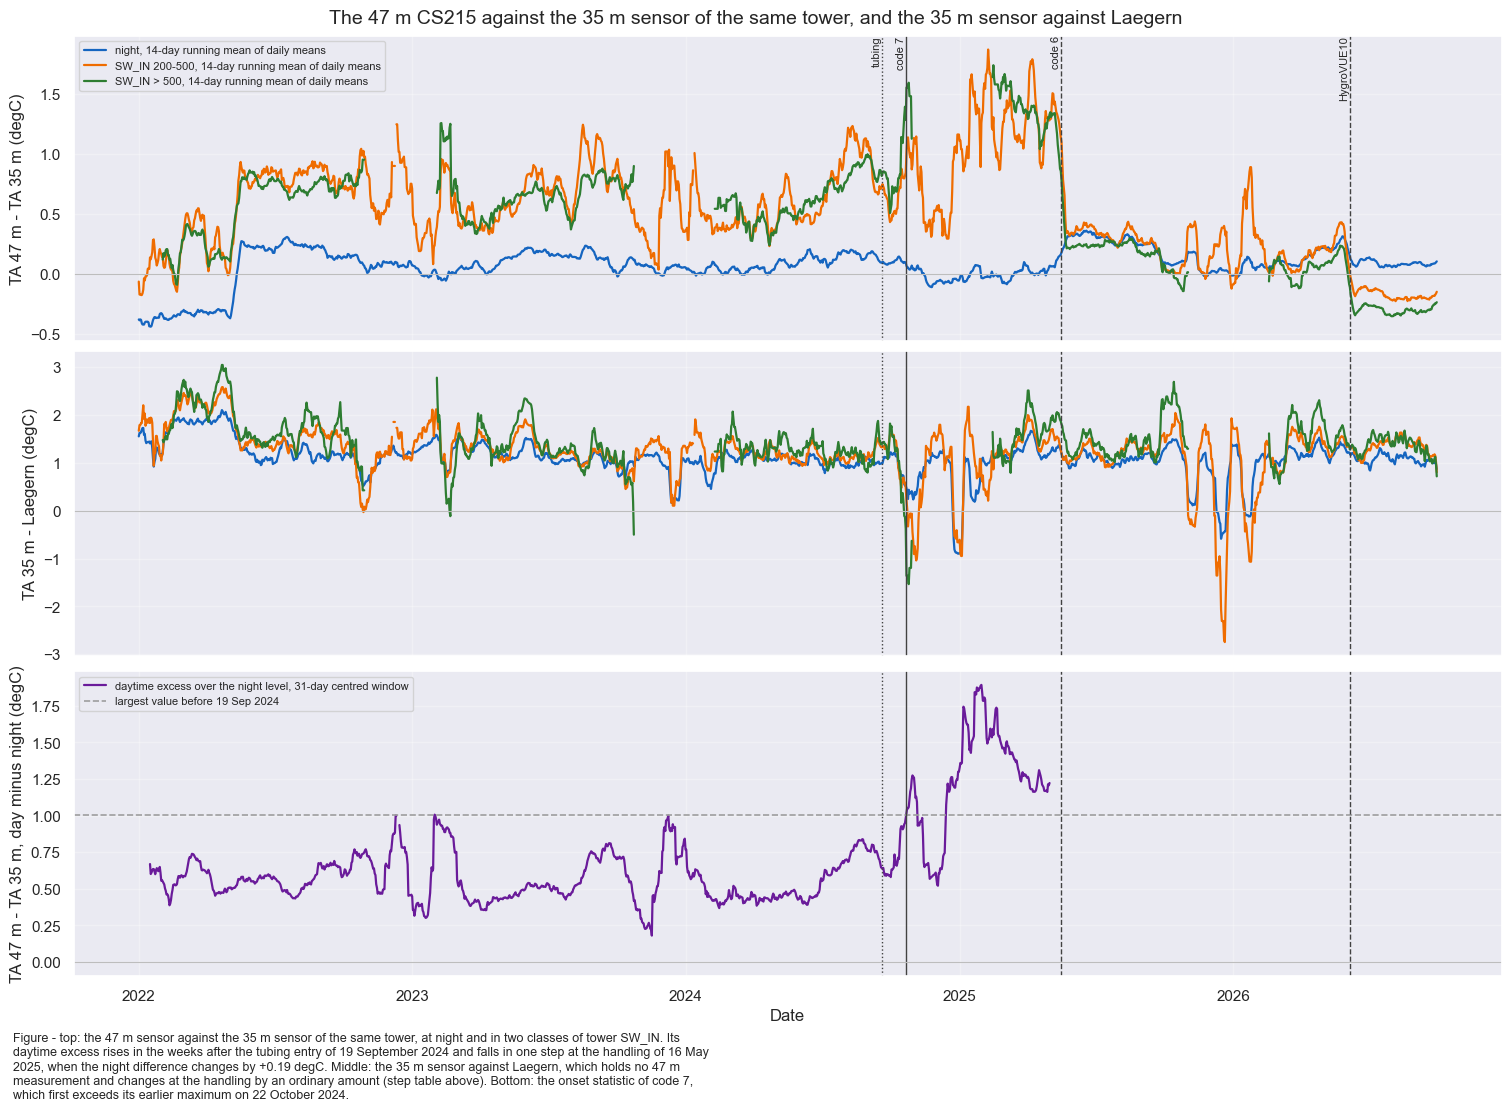

In [52]:
# The tables above as time series: daily class means of the two pairs with a 14-day centred running
# mean, and the onset statistic with the level it is compared against.
fig, axs = plt.subplots(nrows=3, figsize=(15, 11), dpi=100, layout="constrained", sharex=True)
fig.suptitle("The 47 m CS215 against the 35 m sensor of the same tower, and the 35 m sensor against "
             "Laegern", fontsize=14)
_colours = {'night': '#1565C0', 'SW_IN 200-500': '#EF6C00', 'SW_IN > 500': '#2E7D32'}
_day = pair_frame.index.normalize()
for _ax, _name in zip(axs[:2], ['TA 47 m - TA 35 m', 'TA 35 m - Laegern']):
    for _cls, _colour in _colours.items():
        _s = pair_frame[_name].where(pair_frame['class'] == _cls).groupby(_day).mean()
        _s = _s.reindex(pd.date_range(_s.index.min(), _s.index.max(), freq='D'))
        _ax.plot(_s.index, _s.rolling(14, center=True, min_periods=4).mean(), color=_colour, lw=1.6,
                 label=f"{_cls}, 14-day running mean of daily means")
    _ax.set_ylabel(f"{_name} (degC)")
    _ax.grid(alpha=0.3)
axs[0].legend(fontsize=8, loc='upper left')
axs[2].plot(excess_daily.index, excess_daily, color='#6A1B9A', lw=1.6,
            label=f"daytime excess over the night level, {EXCESS_WINDOW}-day centred window")
axs[2].axhline(EXCESS_NORMAL_MAX, color='#9E9E9E', lw=1.2, ls='--',
               label=f"largest value before {TUBING_DATE:%d %b %Y}")
axs[2].set_ylabel("TA 47 m - TA 35 m, day minus night (degC)")
axs[2].grid(alpha=0.3)
axs[2].legend(fontsize=8, loc='upper left')
for _ax in axs:
    for _at, _ls in [(TUBING_DATE, ':'), (EXCESS_START, '-'), (RESET_START, '--'), (HV_START, '--')]:
        _ax.axvline(_at, color='#424242', lw=1.0, ls=_ls)
    _ax.axhline(0, color='#BDBDBD', lw=0.8)
for _at, _txt in [(TUBING_DATE, 'tubing'), (EXCESS_START, 'code 7'), (RESET_START, 'code 6'),
                  (HV_START, 'HygroVUE10')]:
    axs[0].annotate(_txt, (_at, 1.0), xycoords=('data', 'axes fraction'), fontsize=8,
                    rotation=90, ha='right', va='top')
axs[2].set_xlabel("Date")
figcap(fig, f"top: the 47 m sensor against the 35 m sensor of the same tower, at night and in two "
            f"classes of tower SW_IN. Its daytime excess rises in the weeks after the tubing entry "
            f"of {TUBING_DATE:%d %B %Y} and falls in one step at the handling of "
            f"{HANDLING_RECORD:%d %B %Y}, when the night difference changes by "
            f"{_at_handling.loc['TA 47 m - TA 35 m', 'night (degC)']:+.2f} degC. Middle: the 35 m "
            f"sensor against Laegern, which holds no 47 m measurement and changes at the handling "
            f"by an ordinary amount (step table above). "
            f"Bottom: the onset statistic of code 7, which first exceeds its earlier maximum on "
            f"{EXCESS_START:%d %B %Y}.")

#### The correction of code 6

Code 6 is compared with the normal CS215 against Lägern, month by month over the calendar months
in which every radiation class is populated in both. The first table gives the night level per
month and the night term; the next two test the corrected era at night and by radiation, and on
months left out of the derivation. The last table measures what the shield term leaves in code 7.

#### 📋 Table: night level of code 6 and the normal CS215 per calendar month

In [53]:
# The correction of code 6, against Laegern on measured records. The reference is the normal CS215
# (code 0) of HV_CS215_YEARS, homogenised as exported; code 6 is taken as measured. Code 6 covers a
# full year, so the two are matched month by month: per calendar month and class (night, and the
# Laegern shortwave bins by day), code 6 pooled over its months, the reference as the mean of its
# yearly means, averaged over the months used.
# The months used are those in which every class holds at least C6_MIN_RECORDS records in code 6
# and in each reference year. In the remaining months the sun does not reach the upper radiation
# bins, so the comparison of the day cannot be made in them; the full-calendar night value is
# printed beside the one used.
HV_TOLERANCE = 0.15     # degC, largest difference left after a correction (also used in step 12)
C6_MIN_RECORDS = 20     # records per calendar month, class and year


def radiation_class(frame):
    """'night', or the Laegern shortwave bin by day ('day, 0-200 W m-2', ...), per record."""
    _cls = pd.Series('unbinned', index=frame.index, dtype=object)
    _cls[frame['night']] = 'night'
    _day = ~frame['night']
    _bins = pd.cut(frame.loc[_day, 'sw_reference'], MAY_SW_BINS)
    _cls[_day] = [f"day, {int(_b.left)}-{int(_b.right)} W m-2" if pd.notna(_b) else 'unbinned'
                  for _b in _bins]
    return _cls


C6_CLASSES = ['night'] + [f"day, {_lo}-{_hi} W m-2" for _lo, _hi in zip(MAY_SW_BINS[:-1], MAY_SW_BINS[1:])]

c6_compare = pd.DataFrame({
    'tower': evidence['TA_T1_47_1'],
    'reference': evidence[REFCOL],
    'sw': swin_gf[SWIN_COL].reindex(evidence.index),
    'sw_reference': evidence[REFCOL_SW],
    'source': source_flag.reindex(evidence.index),
}).dropna(subset=['tower', 'reference', 'sw'])
c6_compare['night'] = NIGHT.reindex(c6_compare.index).fillna(False).astype(bool)
c6_compare['sample'] = np.select(
    [(c6_compare['source'] == SOURCE_CS215) & c6_compare.index.year.isin(HV_CS215_YEARS),
     c6_compare['source'] == SOURCE_CS215_MAY2025], ['CS215', 'code 6'], default='')
c6_compare = c6_compare[c6_compare['sample'] != '']
c6_compare['class'] = radiation_class(c6_compare)
c6_compare['year'] = c6_compare.index.year
c6_compare['month'] = c6_compare.index.month
c6_compare['residual'] = c6_compare['tower'] - c6_compare['reference']
assert (c6_compare.loc[c6_compare['sample'] == 'CS215', 'source'] == SOURCE_CS215).all(), \
    "the reference sample holds a record that is not the normal CS215"


def c6_monthly(frame, column):
    """Per (month, class): the reference as the mean of its yearly means, code 6 pooled, and counts."""
    _ref = frame[frame['sample'] == 'CS215'].groupby(['month', 'year', 'class'])[column].agg(['mean', 'count'])
    _c6 = frame[frame['sample'] == 'code 6'].groupby(['month', 'class'])[column].agg(['mean', 'count'])
    return _ref, _c6


def c6_months(frame, classes=C6_CLASSES):
    """The calendar months in which every class is populated in code 6 and in each reference year."""
    _ref, _c6 = c6_monthly(frame, 'residual')
    _ok_ref = (_ref['count'].unstack('class').reindex(columns=classes).fillna(0) >= C6_MIN_RECORDS)
    _ok_ref = _ok_ref.all(axis=1).unstack('year').reindex(columns=HV_CS215_YEARS).fillna(False).all(axis=1)
    _ok_c6 = (_c6['count'].unstack('class').reindex(columns=classes).fillna(0) >= C6_MIN_RECORDS).all(axis=1)
    _months = sorted(set(_ok_ref[_ok_ref].index) & set(_ok_c6[_ok_c6].index))
    if len(_months) < 3:
        raise ValueError(f"{len(_months)} calendar months hold every class, need three to match seasons")
    return _months


def c6_profile(frame, column_ref, column_c6, months, classes=C6_CLASSES):
    """Month-matched mean per class over `months`: reference, code 6, and code 6 minus reference."""
    _f = frame[frame['month'].isin(months)]
    _ref = _f[_f['sample'] == 'CS215'].groupby(['month', 'year', 'class'])[column_ref].mean()
    _ref = _ref.groupby(['month', 'class']).mean().unstack('class').reindex(columns=classes)
    _c6 = _f[_f['sample'] == 'code 6'].groupby(['month', 'class'])[column_c6].mean()
    _c6 = _c6.unstack('class').reindex(columns=classes)
    if _ref.isna().any().any() or _c6.isna().any().any():
        raise ValueError("a class is empty in one of the months used")
    return pd.DataFrame({'normal CS215 (degC)': _ref.mean(), 'code 6 (degC)': _c6.mean(),
                         'code 6 minus normal CS215 (degC)': (_c6 - _ref).mean()})


def c6_terms(frame, months):
    """The night term of code 6 over `months`, with the year-to-year scatter of the reference."""
    _night = c6_profile(frame, 'residual', 'residual', months, classes=['night'])
    _ref = frame[(frame['sample'] == 'CS215') & frame['month'].isin(months) & frame['night']]
    _ref = _ref.groupby(['month', 'year'])['residual'].mean().unstack('year')
    _scatter = max(abs((_ref[_y] - _ref.drop(columns=_y).mean(axis=1)).mean()) for _y in _ref.columns)
    return dict(night=float(_night.loc['night', 'code 6 minus normal CS215 (degC)']),
                night_scatter=float(_scatter), months=list(months))


C6_MONTHS = c6_months(c6_compare)
C6_TERMS = c6_terms(c6_compare, C6_MONTHS)
_by_month = c6_compare[c6_compare['night']].groupby(['month', 'sample', 'year'])['residual'].mean()
_by_month = _by_month.unstack(['sample', 'year'])
_by_month = _by_month[sorted(_by_month.columns, key=lambda _c: (_c[0] != 'CS215', _c[1]))]
_by_month.columns = [f"{_s} {_y}" for _s, _y in _by_month.columns]
_c6_cols = [_c for _c in _by_month.columns if _c.startswith('code 6')]
_ref_cols = [_c for _c in _by_month.columns if _c.startswith('CS215')]
_c6_pooled = c6_compare[c6_compare['night'] & (c6_compare['sample'] == 'code 6')].groupby('month')['residual'].mean()
_by_month['code 6 minus normal CS215'] = _c6_pooled - _by_month[_ref_cols].mean(axis=1)
_by_month['used'] = _by_month.index.isin(C6_MONTHS)
tabcap("the night residual against Laegern per calendar month and year, for the normal CS215 of "
       f"{HV_CS215_YEARS[0]}-{HV_CS215_YEARS[-1]} and for code 6, with the month-matched difference and "
       "the months in which every class is populated (degC)")
display(_by_month.round(2))

_full = (_c6_pooled - _by_month[_ref_cols].mean(axis=1)).dropna().mean()
print(f"months used: {C6_MONTHS}")
print(f"night term of code 6: {C6_TERMS['night']:+.3f} degC; year-to-year scatter of the normal "
      f"CS215 night level over the same months {C6_TERMS['night_scatter']:.3f} degC (largest departure of "
      f"one year from the mean of the others). Over all calendar months: {_full:+.3f} degC.")
assert C6_TERMS['night_scatter'] > 0, "the reference night scatter is zero - the years are not independent"
assert abs(C6_TERMS['night']) < 0.5, f"the night term {C6_TERMS['night']:+.3f} degC is implausibly large"
# The limitation stated below: the term is smaller than its own uncertainty.
assert abs(C6_TERMS['night']) < C6_TERMS['night_scatter'], (
    "the night term now exceeds its uncertainty - the limitations of step 11 must be re-derived")

Table - the night residual against Laegern per calendar month and year, for the normal CS215 of
2022-2024 and for code 6, with the month-matched difference and the months in which every class is
populated (degC)



,CS215 2022,CS215 2023,CS215 2024,code 6 2025,code 6 2026,code 6 minus normal CS215,used
month,,,,,,,
1,0.97,1.35,0.97,NaN,0.62,-0.48,False
2,1.42,1.17,1.06,NaN,1.16,-0.05,False
3,1.52,1.43,1.12,NaN,1.26,-0.10,True
4,1.63,1.32,1.18,NaN,1.47,0.09,True
5,1.53,1.33,1.18,1.31,1.45,0.06,True
6,1.27,1.48,1.17,1.47,1.36,0.15,True
7,1.47,1.18,1.14,1.29,NaN,0.03,True
8,1.43,1.22,1.18,1.36,NaN,0.08,True
9,1.31,1.18,1.18,1.31,NaN,0.09,True


months used: [3, 4, 5, 6, 7, 8, 9]
night term of code 6: +0.058 degC; year-to-year scatter of the normal CS215 night level over the same months 0.216 degC (largest departure of one year from the mean of the others). Over all calendar months: -0.057 degC.


In [54]:
# The guards guard. A comparison restricted to two months would match seasons on too little of the
# year, and homogenize() must refuse code-6 records while their term is not derived rather than
# returning them with the shield term of the normal CS215.
try:
    c6_months(c6_compare[c6_compare['month'].isin([6, 7])])
except ValueError as _e:
    print(f"c6_months raises on two calendar months: {_e}")
else:
    raise AssertionError("c6_months accepted two calendar months as a season match")
_saved_c6, C6_TERMS = C6_TERMS, None
try:
    homogenize([20.0], pd.DatetimeIndex([RESET_START]), [500.0])
except RuntimeError as _e:
    print(f"homogenize raises on a code-6 record without its term: {_e}")
else:
    raise AssertionError("homogenize passed a code-6 record through without its term")
finally:
    C6_TERMS = _saved_c6

c6_months raises on two calendar months: 2 calendar months hold every class, need three to match seasons
homogenize raises on a code-6 record without its term: 1 records of the CS215 after May 2025 passed to homogenize() before step 11 has derived their term


#### 📋 Table: code 6 against the normal CS215, homogenised

In [55]:
# Both samples homogenised as exported: the normal CS215 carries the shield term, code 6 the night
# term only. After it, code 6 must lie on the normal CS215 at night and in every radiation bin.
c6_compare['homogenised'] = homogenize(c6_compare['tower'], c6_compare.index, c6_compare['sw'])
c6_compare['residual_homogenised'] = c6_compare['homogenised'] - c6_compare['reference']
c6_check = pd.concat({
    'as measured': c6_profile(c6_compare, 'residual', 'residual', C6_MONTHS),
    'code 6 measured, normal CS215 homogenised': c6_profile(c6_compare, 'residual_homogenised',
                                                           'residual', C6_MONTHS),
    'both homogenised': c6_profile(c6_compare, 'residual_homogenised', 'residual_homogenised', C6_MONTHS),
}, axis=1)
tabcap(f"code 6 against the normal CS215 ({HV_CS215_YEARS[0]}-{HV_CS215_YEARS[-1]}) against Laegern, "
       f"month-matched over months {C6_MONTHS[0]}-{C6_MONTHS[-1]}, at night and by Laegern shortwave: "
       f"as measured, with only the reference homogenised, and with both homogenised (degC)")
display(c6_check.round(3))
_left = c6_check[('both homogenised', 'code 6 minus normal CS215 (degC)')]
print("code 6 minus normal CS215, both homogenised: "
      + ", ".join(f"{_c} {_v:+.3f}" for _c, _v in _left.items()) + " degC")
assert np.isclose(_left['night'], 0.0, atol=1e-9), "the night term does not set the night level it was derived from"
for _c, _v in _left.items():
    assert abs(_v) < HV_TOLERANCE, (
        f"{_c}: homogenised code 6 differs from the homogenised normal CS215 by {_v:+.3f} degC, more "
        f"than {HV_TOLERANCE} degC")

Table - code 6 against the normal CS215 (2022-2024) against Laegern, month-matched over months 3-9,
at night and by Laegern shortwave: as measured, with only the reference homogenised, and with both
homogenised (degC)



as measured                                                code 6 measured, normal CS215 homogenised                                                   both homogenised                                               
                    normal CS215 (degC) code 6 (degC) code 6 minus normal CS215 (degC)                       normal CS215 (degC) code 6 (degC) code 6 minus normal CS215 (degC) normal CS215 (degC) code 6 (degC) code 6 minus normal CS215 (degC)
class                                                                                                                                                                                                                                             
night                             1.307         1.364                            0.058                                     1.307         1.364                            0.058               1.307         1.307                            0.000
day, 0-200 W m-2                  1.512         1.354                           -0.158                                     1.371         1.354                           -0.017               1.371         1.297                           -0.074
day, 200-350 W m-2                2.033         1.575                           -0.458                                     1.596         1.575                           -0.020               1.596         1.518                           -0.078
day, 350-500 W m-2                2.153         1.539                           -0.613                                     1.607         1.539                           -0.068               1.607         1.482                           -0.125
day, 500-650 W m-2                2.128         1.537                           -0.591                                     1.561         1.537                           -0.025               1.561         1.479                           -0.082
day, 650-1200 W m-2               2.128         1.673                           -0.455                                     1.654         1.673                            0.019               1.654         1.615                           -0.039

code 6 minus normal CS215, both homogenised: night +0.000, day, 0-200 W m-2 -0.074, day, 200-350 W m-2 -0.078, day, 350-500 W m-2 -0.125, day, 500-650 W m-2 -0.082, day, 650-1200 W m-2 -0.039 degC


#### 📋 Table: month hold-out of the code-6 night term

In [56]:
# The check above is scored on the months the night term was derived from. Here each month is left
# out in turn, the night term is derived from the others, and the held-out month is predicted: its
# all-hours mean of code 6 minus that term, against the normal CS215 homogenised. The tolerance is
# the same statistic among the reference years: how far one year's month departs from the mean of
# the other years in that month.
_ref_month = (c6_compare[c6_compare['sample'] == 'CS215']
              .groupby(['month', 'year'])['residual_homogenised'].mean().unstack('year'))
_rows = []
for _m in C6_MONTHS:
    _terms = c6_terms(c6_compare, [_x for _x in C6_MONTHS if _x != _m])
    _held = c6_compare[(c6_compare['sample'] == 'code 6') & (c6_compare['month'] == _m)]
    _rows.append({'month': _m, 'code 6 records': len(_held),
                  'night term of the refit (degC)': _terms['night'],
                  'as measured (degC)': _held['residual'].mean() - _ref_month.loc[_m].mean(),
                  'held out, corrected (degC)': (_held['residual'] - _terms['night']).mean()
                                                - _ref_month.loc[_m].mean()})
c6_holdout = pd.DataFrame(_rows).set_index('month')
C6_HOLDOUT_TOLERANCE = max(abs(_ref_month.loc[_m, _y] - _ref_month.loc[_m].drop(_y).mean())
                           for _m in C6_MONTHS for _y in _ref_month.columns)
tabcap("the month hold-out of the code-6 night term: each month predicted with the term derived "
       "from the other months, as its all-hours mean against the homogenised normal CS215 (degC)")
display(c6_holdout.round(3))
print(f"tolerance, the largest departure of one reference year's month from the other years' mean "
      f"of that month: {C6_HOLDOUT_TOLERANCE:.3f} degC")
print(f"held-out error {c6_holdout['held out, corrected (degC)'].abs().max():.3f} degC at most; night "
      f"term of the refits {c6_holdout['night term of the refit (degC)'].min():+.3f} to "
      f"{c6_holdout['night term of the refit (degC)'].max():+.3f} degC (full {C6_TERMS['night']:+.3f})")
assert (c6_holdout['code 6 records'] > 500).all(), "a held-out month holds too few records to score"
assert (c6_holdout['held out, corrected (degC)'].abs() < C6_HOLDOUT_TOLERANCE).all(), (
    "a held-out month departs from the normal CS215 by more than one reference year departs from "
    "the others - the night term does not carry to months it was not derived from")

Table - the month hold-out of the code-6 night term: each month predicted with the term derived from
the other months, as its all-hours mean against the homogenised normal CS215 (degC)



,code 6 records,night term of the refit (degC),as measured (degC),"held out, corrected (degC)"
month,,,,
3,1488,0.084,-0.131,-0.215
4,1440,0.052,0.147,0.095
5,2236,0.057,0.043,-0.014
6,1654,0.042,0.087,0.046
7,1488,0.062,-0.060,-0.122
8,1488,0.054,0.012,-0.041
9,1440,0.052,-0.022,-0.074


tolerance, the largest departure of one reference year's month from the other years' mean of that month: 0.573 degC
held-out error 0.215 degC at most; night term of the refits +0.042 to +0.084 degC (full +0.058)


#### 📋 Table: code 7 against the normal CS215, homogenised

In [57]:
# Code 7 is homogenised as the normal CS215 and not corrected further: its excess grew over weeks
# rather than stepping, so there is no boundary from which a fixed term could apply, and a term
# fitted to it would replace measurements with a guess.
# What that leaves is measured here, month-matched against the normal CS215 of the same calendar
# months (any months in which a class is populated, as code 7 covers only October to May).
_f = pd.DataFrame({
    'tower': evidence['TA_T1_47_1'],
    'reference': evidence[REFCOL],
    'sw': swin_gf[SWIN_COL].reindex(evidence.index),
    'sw_reference': evidence[REFCOL_SW],
    'source': source_flag.reindex(evidence.index),
}).dropna(subset=['tower', 'reference', 'sw'])
_f = _f[((_f['source'] == SOURCE_CS215) & _f.index.year.isin(HV_CS215_YEARS))
        | (_f['source'] == SOURCE_CS215_HEATED)]
_f['night'] = NIGHT.reindex(_f.index).fillna(False).astype(bool)
_f['class'] = radiation_class(_f)
_f['residual'] = homogenize(_f['tower'], _f.index, _f['sw']) - _f['reference']
_rows = {}
for _cls in C6_CLASSES:
    _d, _n = era_minus_normal(_f, 'residual', SOURCE_CS215_HEATED, _cls)
    _rows[_cls] = {'code 7 minus normal CS215, homogenised (degC)': _d, 'months': _n}
c7_left = pd.DataFrame(_rows).T
tabcap("code 7 against the normal CS215 after homogenisation, month-matched against Laegern: what "
       "the shield term of the normal CS215 leaves in the heated era (degC)")
display(c7_left.round(2))
C7_UNDERCORRECTION = float(c7_left.loc[C6_CLASSES[1:], 'code 7 minus normal CS215, homogenised (degC)'].max())
print(f"code 7 stays too warm in sun after homogenisation by up to {C7_UNDERCORRECTION:.2f} degC")
# The limitation stated for code 7 holds on this run.
assert C7_UNDERCORRECTION > 0.3, "code 7 no longer reads warm after homogenisation - its limitation must be re-derived"

Table - code 7 against the normal CS215 after homogenisation, month-matched against Laegern: what
the shield term of the normal CS215 leaves in the heated era (degC)



,"code 7 minus normal CS215, homogenised (degC)",months
night,-0.30,8.0
"day, 0-200 W m-2",-0.10,8.0
"day, 200-350 W m-2",0.03,8.0
"day, 350-500 W m-2",0.31,7.0
"day, 500-650 W m-2",0.83,3.0
"day, 650-1200 W m-2",0.92,3.0


code 7 stays too warm in sun after homogenisation by up to 0.92 degC


#### Limitations of the May 2025 terms

- **Code 7 is under-corrected in sun** by the amount in the last table: it receives the shield
  term of the normal CS215 and nothing more. Daytime values and daily maxima from its onset to
  16 May 2025 are biased warm. Filter on the source flag where this matters.
- **The onset of code 7 is dated by a rule** on a statistic over a centred window of a month. The
  excess grows gradually, so records shortly before the onset may already carry part of it.
- **The night term of code 6 is small against its uncertainty**, the year-to-year scatter printed
  with it, and rests on one reference 2.5 km away. It is applied because the change is
  established, not because the night difference is resolved.
- **The comparison covers the months in which every radiation class is populated.** In the other
  months the day cannot be compared in every class; the night value over all calendar months is
  printed beside the one used.

### 1️⃣2️⃣ The June 2026 probe change

On **5 June 2026** a Campbell **HygroVUE10** (SN E6730, SDI-12) replaced the CS215 at 47 m. The
field name `TA_T1_47_1` and its database tags did not change. The change is dated by three
independent observations:

- **The raw record.** The 1-minute `TA_T1_47_1` has a gap from 11:10 to 11:31 (local time,
  `TIMESTAMP_END`) that day. The first HygroVUE10 half-hour is therefore the one ending 12:00
  (`HV_START`), and the half-hour 11:00 to 11:30 is a partial or mixed record (`SWAP_RECORD`,
  removed in *Corrections*, source code `5`).
- **The fieldbook.** It adds the HygroVUE10 at `CH-LAE_T1_47` on 5 June, and on 11 June changes its
  SDI-12 configuration ID together with the logger program. It has no entry for the removal of the
  CS215, which GIN never registered at that location. The cell below asserts both dates.
- **The data.** The residual against MeteoSwiss Lägern changes level from that day, most in sun
  (tables below).

**Reference level.** The HygroVUE10 era is brought onto the level of the normal CS215, and the
shield term of step 🔟 is then applied to it as to that era, so all eras end on the same reference. The
measured column keeps the HygroVUE10 values as measured.

**Method.** NABEL ended in 2018, so Lägern is the only reference that spans the change, and the
transfer is fitted against it on two season-matched samples: the HygroVUE10 from 12 June to
30 September 2026 (5 to 11 June, before the configuration change, are transitional and enter no
fit), and the normal CS215 (code 0) on the same calendar dates of 2022 to 2024. 2025 is not
used: the CS215 was heated until 16 May that year and changed state after it (step 1️⃣1️⃣).

- **Radiation term.** The residual (tower minus Lägern) of each sample is fitted against tower
  `SW_IN` with `shield_basis`, the basis of the shield term. `hv_excess` is the difference of the
  two curves with its zero-radiation part removed, so it is zero in the dark, and the driver is
  clipped to the range both samples cover.
- **Night term.** A constant equal to the night difference between the samples. The probe change
  is established (fieldbook, raw-data gap, radiation-dependent step), so the night level is
  corrected as well. The year-to-year scatter of the CS215 night level (largest departure of one
  CS215 year from the mean of the other two) is reported as its uncertainty.
- **Scoring.** With no second reference to score against, each month of 2026 is left out in turn,
  the transfer is refitted on the rest, and the month is predicted.

In [58]:
# The probe change in the fieldbook. HV_START and HV_FIT_START are declared in the settings; here
# they are checked against the entries that date them, so a mistyped setting or a changed export
# fails instead of moving an era boundary silently. `fb` is the redacted export read in step 6.
_at_t147 = fb['Location'].astype(str).str.contains('T1_47', regex=False)
_hv_rows = fb[_at_t147 & fb['Device Model'].astype(str).str.contains('HygroVUE10', regex=False)]
_hv_rows = _hv_rows.sort_values('Date')
print("Fieldbook entries for the HygroVUE10 at CH-LAE_T1_47:")
for _, _r in _hv_rows.iterrows():
    print(f"--- {_r['Date'].date()}  {_r['Event Tag']:7s} {_r['Device Name']}")
    print(f"    {_r['text'][:300]}")
assert len(_hv_rows) > 0, "no HygroVUE10 entry at T1_47 - is FIELDBOOK the export of October 2026?"

_hv_add = _hv_rows[_hv_rows['Event Tag'] == 'ADD']
assert len(_hv_add) == 1, f"{len(_hv_add)} HygroVUE10 ADD entries at T1_47, expected one"
assert _hv_add['Date'].iloc[0].date() == HV_START.date(), (
    f"the fieldbook adds the HygroVUE10 on {_hv_add['Date'].iloc[0].date()}, the settings date "
    f"its first record to {HV_START.date()}")
# The configuration change that ends the transitional days. The fit sample starts the day after it.
_hv_config = _hv_rows[_hv_rows['Event Tag'] == 'CONFIG']
assert len(_hv_config) > 0, "no configuration entry for the HygroVUE10 at T1_47"
assert _hv_config['Date'].max().date() == (HV_FIT_START - pd.Timedelta('1D')).date(), (
    f"the last HygroVUE10 configuration entry is dated {_hv_config['Date'].max().date()}, not the "
    f"day before HV_FIT_START ({HV_FIT_START.date()})")

# The HygroVUE10 is the first temperature and humidity device GIN registers at T1_47, and the
# CS215 it replaced is never registered there, so its removal has no entry. The swap is dated to
# the half-hour by the raw record (settings), and the fieldbook confirms the day.
_rhta_t147 = fb['Operation Tag'].astype(str).str.contains('iRHTA_T1_47', regex=False)
assert fb.loc[_rhta_t147, 'Date'].min().date() == HV_START.date(), \
    "GIN registers a temperature and humidity device at T1_47 before the HygroVUE10"
assert not (_at_t147 & fb['Device Model'].astype(str).str.contains('CS215', regex=False)).any(), \
    "the fieldbook now registers a CS215 at T1_47 - its entries may date the swap and must be read"
print(f"\nOK: the HygroVUE10 is added on {HV_START.date()}, reconfigured on "
      f"{_hv_config['Date'].max().date()}; no CS215 is registered at T1_47.")

Fieldbook entries for the HygroVUE10 at CH-LAE_T1_47:
--- 2026-06-05  ADD     HygroVUE10_E6730
    Move device to location
--- 2026-06-11  CONFIG  HygroVUE10_E6730
    Modified configuration ID of the Hygrovue sensor from 0 to 1
--- 2026-06-11  SW_MOD  HygroVUE10_E6730
    Installed new loggerprogram to measure with new UV-A sensor. Adapted the SDI12 recorder command structure https://gitlab.ethz.ch/gl/ch-lae_idl_t1_47_1/-/tree/80ef9a0714294f21f5937ebfd3f508ddaa1059ef

OK: the HygroVUE10 is added on 2026-06-05, reconfigured on 2026-06-11; no CS215 is registered at T1_47.


#### 📋 Table: samples of the HygroVUE10 comparison

In [59]:
# The two samples. MeteoSwiss Laegern is the only reference that spans the probe change: NABEL
# ended in 2018, so the transfer is fitted and scored against the same station, and the month
# hold-out further below takes the place of an independent second reference.
# HygroVUE10: measured records from HV_FIT_START to the end of the record. CS215: measured records
# of the normal CS215 (code 0) in HV_CS215_YEARS on the same calendar dates. Measured tower, Laegern and tower SW_IN all
# present. `evidence` carries Laegern on TIMESTAMP_MID already (shifted by -15 min in step 1).
HV_SW_BINS = [0, 200, 350, 500, 650, 1200]   # W m-2, incoming shortwave at Laegern, day records
HV_DAY_COLS = {_lo: f"day, {_lo}-{_hi} W m-2" for _lo, _hi in zip(HV_SW_BINS[:-1], HV_SW_BINS[1:])}
# HV_TOLERANCE, the largest difference left after a correction, is set in step 11.
HV_MIN_RECORDS = 2_000                        # half-hours, about six weeks, for one fit
HV_MIN_SUNNY = 200                            # of them above 500 W m-2, so the curve is constrained
_hv_end = pd.Timestamp(PERIOD_END)


def in_hv_season(index):
    """True on the calendar dates of the HygroVUE10 sample (HV_FIT_START to PERIOD_END), any year."""
    _md = index.month * 100 + index.day
    return (_md >= HV_FIT_START.month * 100 + HV_FIT_START.day) & (_md <= _hv_end.month * 100 + _hv_end.day)


hv_compare = pd.DataFrame({
    'tower': evidence['TA_T1_47_1'],
    'reference': evidence[REFCOL],
    'sw': swin_gf[SWIN_COL].reindex(evidence.index),
    'sw_reference': evidence[REFCOL_SW],
}).dropna(subset=['tower', 'reference', 'sw'])
hv_compare['residual'] = hv_compare['tower'] - hv_compare['reference']
hv_compare['night'] = NIGHT.reindex(hv_compare.index).fillna(False).astype(bool)
hv_compare['source'] = source_flag.reindex(hv_compare.index)
hv_compare['sample'] = np.select(
    [(hv_compare.index >= HV_FIT_START) & (hv_compare.index <= _hv_end),
     hv_compare.index.year.isin(HV_CS215_YEARS) & in_hv_season(hv_compare.index)
     & (hv_compare['source'] == SOURCE_CS215).to_numpy()],
    ['HygroVUE10', 'CS215'], default='')
hv_compare = hv_compare[hv_compare['sample'] != '']
hv_compare['year'] = hv_compare.index.year
_is_hv = (hv_compare['sample'] == 'HygroVUE10').to_numpy()

# Each sample is the sensor it is named after, and nothing else.
assert (hv_compare.loc[~_is_hv, 'source'] == SOURCE_CS215).all(), \
    "the CS215 sample holds a record that is not the normal CS215 (code 0)"
assert (hv_compare.index[_is_hv] >= HV_FIT_START).all(), \
    "the HygroVUE10 sample holds a record from the transitional days"
assert sorted(hv_compare.loc[~_is_hv, 'year'].unique()) == sorted(HV_CS215_YEARS), \
    "a CS215 comparison year has no records"

tabcap("the two samples of the HygroVUE10 comparison: measured records with Laegern present, "
       "season-matched, per year")
display(hv_compare.groupby(['sample', 'year']).agg(
    records=('residual', 'size'), night=('night', 'sum'),
    first=('residual', lambda s: s.index.min()), last=('residual', lambda s: s.index.max())))


def fit_hv_transfer(frame):
    """Least-squares fit of the tower-minus-Laegern residual in tower SW_IN, on shield_basis.

    Raises on a sample too small to fit or too dark to constrain the radiation curve: a fit on a
    few days returns coefficients as confidently as one on a summer.
    """
    _sunny = int((frame['sw'] > 500).sum())
    if len(frame) < HV_MIN_RECORDS or _sunny < HV_MIN_SUNNY:
        raise ValueError(f"{len(frame)} records ({_sunny} above 500 W m-2), need {HV_MIN_RECORDS} "
                         f"({HV_MIN_SUNNY}) to fit a radiation response")
    _beta, *_ = np.linalg.lstsq(shield_basis(frame['sw']), frame['residual'].to_numpy(), rcond=None)
    return _beta


def hv_terms(frame):
    """The HygroVUE10 transfer from one comparison frame: both fits, the clip and the night term.

    The night term is the night difference between the samples, applied as a constant: the probe
    change is established, so its night level is corrected as well as its radiation response. The
    CS215 year-to-year scatter of the same quantity (the largest departure of one CS215 year's night
    mean from the mean of the other years) is returned as the uncertainty of that term. The CS215
    night level is the mean of its yearly night means, so each year weighs the same as in the
    scatter.
    """
    _hv, _cs = frame[frame['sample'] == 'HygroVUE10'], frame[frame['sample'] == 'CS215']
    _beta_hv, _beta_cs = fit_hv_transfer(_hv), fit_hv_transfer(_cs)
    _cs_night = _cs[_cs['night']].groupby('year')['residual'].mean()
    if len(_cs_night) < 3:
        raise ValueError(f"{len(_cs_night)} CS215 years at night, need three to measure their scatter")
    _diff = _hv.loc[_hv['night'], 'residual'].mean() - _cs_night.mean()
    _scatter = max(abs(_cs_night[_y] - _cs_night.drop(_y).mean()) for _y in _cs_night.index)
    return dict(beta_hv=_beta_hv, beta_cs=_beta_cs,
                sw_max=float(min(_hv['sw'].quantile(0.999), _cs['sw'].quantile(0.999))),
                night_difference=float(_diff), night_scatter=float(_scatter),
                night=float(_diff))

Table - the two samples of the HygroVUE10 comparison: measured records with Laegern present, season-
matched, per year



records  night               first                last
sample     year                                                        
CS215      2022     5328   2060 2022-06-12 00:15:00 2022-09-30 23:45:00
           2023     5320   2060 2023-06-12 00:15:00 2023-09-30 23:45:00
           2024     5237   2035 2024-06-12 00:15:00 2024-09-30 23:45:00
HygroVUE10 2026     5328   2060 2026-06-12 00:15:00 2026-09-30 23:45:00

In [60]:
# The guard guards. A single summer day holds 48 records and is sunny enough to give a curve, so
# without the size check the fit would return coefficients for it as readily as for a summer.
_one_day = hv_compare[_is_hv & (hv_compare.index.normalize() == pd.Timestamp('2026-07-15'))]
assert 0 < len(_one_day) <= 48, "the control day is not in the HygroVUE10 sample"
try:
    fit_hv_transfer(_one_day)
except ValueError as _e:
    print(f"fit_hv_transfer raises on a single day: {_e}")
else:
    raise AssertionError("fit_hv_transfer accepted a single day as a HygroVUE10 sample")
# And homogenize() refuses HygroVUE10 records while their terms are not derived, rather than
# returning them with the CS215 correction alone.
_saved_terms, HV_TERMS = HV_TERMS, None
try:
    homogenize([20.0], pd.DatetimeIndex([HV_START]), [500.0])
except RuntimeError as _e:
    print(f"homogenize raises on a HygroVUE10 record without its terms: {_e}")
else:
    raise AssertionError("homogenize passed a HygroVUE10 record through without its terms")
finally:
    HV_TERMS = _saved_terms

fit_hv_transfer raises on a single day: 48 records (8 above 500 W m-2), need 2000 (200) to fit a radiation response
homogenize raises on a HygroVUE10 record without its terms: 1 HygroVUE10 records passed to homogenize() before step 12 has derived their terms


The first table below shows the samples as measured; the second gives the fitted transfer and the
night decision; the third shows both samples after homogenisation. The day columns are binned by
the radiation at Lägern, as in step 9️⃣, so the bins do not select on the driver the transfer is
fitted on.

#### 📋 Table: HygroVUE10 and CS215 against Laegern, as measured

In [61]:
def hv_profile(frame, column='residual'):
    """Mean of `column` at night, and by day per bin of Laegern shortwave, over `frame`.

    Binned by the reference radiation rather than by the tower SW_IN the transfer is fitted on, as
    in step 9. Thin bins raise in binned_residual().
    """
    _f = frame.assign(residual=frame[column])
    _day, _ = binned_residual(_f[~_f['night']], 'sw_reference', HV_SW_BINS)
    _day.index = list(HV_DAY_COLS.values())
    return pd.concat([pd.Series({'night': _f.loc[_f['night'], 'residual'].mean()}), _day])


def hv_profile_table(frame, column='residual'):
    """One profile per CS215 year, their mean, the HygroVUE10 sample, and HygroVUE10 minus CS215."""
    _rows = {f"CS215 {_y}": hv_profile(frame[(frame['sample'] == 'CS215') & (frame['year'] == _y)],
                                       column)
             for _y in HV_CS215_YEARS}
    _tab = pd.DataFrame(_rows).T
    _tab.loc['CS215, mean of the years'] = _tab.mean()
    _tab.loc[f'HygroVUE10 {HV_START.year}'] = hv_profile(frame[frame['sample'] == 'HygroVUE10'], column)
    _tab.loc['HygroVUE10 minus CS215'] = (_tab.loc[f'HygroVUE10 {HV_START.year}']
                                          - _tab.loc['CS215, mean of the years'])
    return _tab


# What the data show: tower minus Laegern, season-matched, as measured.
hv_raw_profile = hv_profile_table(hv_compare)
tabcap(f"tower 47 m minus MeteoSwiss Laegern as measured, {HV_FIT_START:%d %b} to "
       f"{_hv_end:%d %b}, per CS215 year and for the HygroVUE10 in {HV_START.year}, at night and by "
       f"the reference radiation by day (degC)")
display(hv_raw_profile.round(2))
_raw_diff = hv_raw_profile.loc['HygroVUE10 minus CS215']
_sun_cols = [_c for _lo, _c in HV_DAY_COLS.items() if _lo >= 500]
print(f"HygroVUE10 minus CS215 as measured: night {_raw_diff['night']:+.2f} degC, above 500 W m-2 "
      f"{_raw_diff[_sun_cols].min():+.2f} to {_raw_diff[_sun_cols].max():+.2f} degC")

Table - tower 47 m minus MeteoSwiss Laegern as measured, 12 Jun to 30 Sep, per CS215 year and for
the HygroVUE10 in 2026, at night and by the reference radiation by day (degC)



,night,"day, 0-200 W m-2","day, 200-350 W m-2","day, 350-500 W m-2","day, 500-650 W m-2","day, 650-1200 W m-2"
CS215 2022,1.38,1.59,2.27,2.36,2.34,2.30
CS215 2023,1.21,1.45,1.96,1.98,1.93,1.92
CS215 2024,1.17,1.41,1.95,2.15,2.08,1.94
"CS215, mean of the years",1.25,1.48,2.06,2.16,2.12,2.05
HygroVUE10 2026,1.14,1.17,1.21,1.13,1.02,1.13
HygroVUE10 minus CS215,-0.11,-0.31,-0.85,-1.03,-1.09,-0.92


HygroVUE10 minus CS215 as measured: night -0.11 degC, above 500 W m-2 -1.09 to -0.92 degC


#### 📋 Table: fitted HygroVUE10 transfer

In [62]:
# The transfer.
HV_TERMS = hv_terms(hv_compare)
_grid_sw = [0, 200, 400, 600, 800]
_x = shield_basis(np.clip(_grid_sw, 0.0, HV_TERMS['sw_max']))
hv_coef_table = pd.DataFrame({
    'CS215 fit (degC)': _x @ HV_TERMS['beta_cs'],
    'HygroVUE10 fit (degC)': _x @ HV_TERMS['beta_hv'],
    'hv_excess (degC)': hv_excess(_grid_sw)},
    index=pd.Index(_grid_sw, name='tower SW_IN (W m-2)'))
tabcap(f"the fitted tower-minus-Laegern residual of each sample against tower SW_IN (order "
       f"{SHIELD_ORDER}, clipped at {HV_TERMS['sw_max']:.0f} W m-2), and hv_excess, their "
       f"difference with its zero-radiation part removed")
display(hv_coef_table.round(3))

print(f"\nNight: HygroVUE10 minus CS215 {HV_TERMS['night_difference']:+.3f} degC; CS215 year-to-year "
      f"scatter of the same quantity {HV_TERMS['night_scatter']:.3f} degC (largest departure of one "
      f"year from the mean of the other {len(HV_CS215_YEARS) - 1}).")
print(f"  -> night term {HV_TERMS['night']:+.3f} degC, removed from every HygroVUE10 record. The "
      f"probe change is established, so the night level is corrected too; the scatter is its "
      f"uncertainty.")

assert HV_TERMS['night_scatter'] > 0, "the CS215 night scatter is zero - the years are not independent"
assert HV_TERMS['night'] == HV_TERMS['night_difference'], "the night term is not the night difference"
# Zero in the dark, exactly, so the night level is set by the night term alone.
assert hv_excess([0.0])[0] == 0.0, "hv_excess is not zero in the dark"
# The sign, against the data: in sun the HygroVUE10 reads cooler than the CS215, relative to its
# night level, so the term is negative there and raises the HygroVUE10 onto the CS215 level.
_sunny_hv = hv_compare.loc[_is_hv & (hv_compare['sw'] > 500).to_numpy(), 'sw']
assert (_raw_diff[_sun_cols] - _raw_diff['night']).max() < 0, \
    "the HygroVUE10 no longer reads cooler than the CS215 in sun - the text of step 12 is wrong"
assert hv_excess(_sunny_hv).mean() < 0, \
    "hv_excess is not negative in sun, against the sign the data show"
assert np.abs(hv_excess(np.linspace(0, HV_TERMS['sw_max'], 50))).max() < 1.5, \
    "hv_excess exceeds 1.5 degC inside the fitted range"

Table - the fitted tower-minus-Laegern residual of each sample against tower SW_IN (order 2, clipped
at 989 W m-2), and hv_excess, their difference with its zero-radiation part removed



,CS215 fit (degC),HygroVUE10 fit (degC),hv_excess (degC)
tower SW_IN (W m-2),,,
0,1.264,1.151,0.000
200,1.781,1.128,-0.540
400,2.098,1.119,-0.867
600,2.216,1.122,-0.981
800,2.135,1.139,-0.883



Night: HygroVUE10 minus CS215 -0.114 degC; CS215 year-to-year scatter of the same quantity 0.187 degC (largest departure of one year from the mean of the other 2).
  -> night term -0.114 degC, removed from every HygroVUE10 record. The probe change is established, so the night level is corrected too; the scatter is its uncertainty.


#### 📋 Table: HygroVUE10 and CS215 against Laegern, homogenised

In [63]:
# After the correction, both samples homogenised: what is left between them.
hv_compare['homogenised'] = homogenize(hv_compare['tower'], hv_compare.index, hv_compare['sw'])
hv_compare['residual_homogenised'] = hv_compare['homogenised'] - hv_compare['reference']
hv_homog_profile = hv_profile_table(hv_compare, 'residual_homogenised')
tabcap("the same table after homogenisation: the CS215 years carry the shield term, the "
       "HygroVUE10 carries hv_excess, the night term and the shield term (degC)")
display(hv_homog_profile.round(2))
_left = hv_homog_profile.loc['HygroVUE10 minus CS215']
_day_checked = [_c for _lo, _c in HV_DAY_COLS.items() if _lo >= 200]
print(f"HygroVUE10 minus CS215 after homogenisation, night: {_left['night']:+.3f} degC")
for _c in _day_checked:
    print(f"  {_c}: {_left[_c]:+.3f} degC, {_left[_c] - _left['night']:+.3f} degC from the night level")
# The night term sets the night level and hv_excess the response in sun, so after both the
# HygroVUE10 must sit on the CS215 level at night and in every daytime bin above 200 W m-2.
assert abs(_left['night']) < HV_TOLERANCE, (
    f"at night the homogenised HygroVUE10 differs from the homogenised CS215 by "
    f"{_left['night']:+.3f} degC, more than {HV_TOLERANCE} degC")
for _c in _day_checked:
    assert abs(_left[_c]) < HV_TOLERANCE, (
        f"{_c}: after homogenisation the HygroVUE10 differs from the CS215 by {_left[_c]:+.3f} degC, "
        f"more than {HV_TOLERANCE} degC - the transfer does not describe the data")

Table - the same table after homogenisation: the CS215 years carry the shield term, the HygroVUE10
carries hv_excess, the night term and the shield term (degC)



,night,"day, 0-200 W m-2","day, 200-350 W m-2","day, 350-500 W m-2","day, 500-650 W m-2","day, 650-1200 W m-2"
CS215 2022,1.38,1.45,1.83,1.81,1.77,1.86
CS215 2023,1.21,1.31,1.52,1.43,1.36,1.45
CS215 2024,1.17,1.27,1.52,1.60,1.52,1.47
"CS215, mean of the years",1.25,1.34,1.62,1.61,1.55,1.59
HygroVUE10 2026,1.25,1.37,1.58,1.58,1.53,1.65
HygroVUE10 minus CS215,0.00,0.02,-0.04,-0.03,-0.02,0.05


HygroVUE10 minus CS215 after homogenisation, night: +0.000 degC
  day, 200-350 W m-2: -0.043 degC, -0.043 degC from the night level
  day, 350-500 W m-2: -0.028 degC, -0.028 degC from the night level
  day, 500-650 W m-2: -0.019 degC, -0.019 degC from the night level
  day, 650-1200 W m-2: +0.052 degC, +0.052 degC from the night level


At night the HygroVUE10 reads cooler than the CS215 mean by an amount comparable to the
difference between one CS215 summer and the others; the night term removes that difference. In sun it reads cooler by an
amount that grows with radiation and levels off in strong sun; the radiation term removes that
part. After both terms the homogenised HygroVUE10 lies on the CS215 level at night and at every
level of radiation.

The table after homogenisation is scored on the records the transfer was fitted to, so it cannot
fail on a poor fit. The month hold-out below can.

#### 📋 Table: month hold-out of the HygroVUE10 transfer

In [64]:
# The fit above is scored on the records it was fitted to, so its residual is small by
# construction. The hold-out removes that: each month of the HygroVUE10 sample is left out in turn,
# from both samples, the transfer is refitted on the rest, and the held-out month is predicted.
# The statistic is the month's mean HygroVUE10-minus-CS215 difference, the CS215 side being the
# mean of its yearly means for that month.
# The tolerance is the same statistic among the CS215 years: how far one year's month departs from
# the mean of the other years in that month. A held-out error inside it is as small as the
# difference between two summers of one sensor.

_months = sorted(hv_compare.loc[_is_hv].index.month.unique())
_rows, _cs_scatter = [], []
for _m in _months:
    _train = hv_compare[hv_compare.index.month != _m]
    _test = hv_compare[hv_compare.index.month == _m]
    _terms = hv_terms(_train)
    _hv_test = _test[_test['sample'] == 'HygroVUE10']
    _cs_years = _test[_test['sample'] == 'CS215'].groupby('year')['residual'].mean()
    _predicted = (_hv_test['residual'] - hv_excess(_hv_test['sw'], terms=_terms) - _terms['night'])
    _rows.append({'month': _m, 'HygroVUE10 records': len(_hv_test),
                  'as measured (degC)': _hv_test['residual'].mean() - _cs_years.mean(),
                  'held out, corrected (degC)': _predicted.mean() - _cs_years.mean(),
                  'night term of the refit (degC)': _terms['night']})
    _cs_scatter += [abs(_cs_years[_y] - _cs_years.drop(_y).mean()) for _y in _cs_years.index]
hv_holdout = pd.DataFrame(_rows).set_index('month')
HV_HOLDOUT_TOLERANCE = max(_cs_scatter)
tabcap("the month hold-out of the HygroVUE10 transfer: each month refitted without it and "
       "predicted, as the month's mean HygroVUE10-minus-CS215 difference against Laegern, all hours")
display(hv_holdout.round(3))
print(f"tolerance, the largest departure of one CS215 year's month from the other years' mean of "
      f"that month: {HV_HOLDOUT_TOLERANCE:.3f} degC ({len(_cs_scatter)} year-months)")
print(f"held-out error: {hv_holdout['held out, corrected (degC)'].abs().max():.3f} degC at most, "
      f"{hv_holdout['as measured (degC)'].abs().max():.3f} degC before the correction")

assert len(hv_holdout) == 4, f"{len(hv_holdout)} months in the HygroVUE10 sample, expected June to September"
assert (hv_holdout['HygroVUE10 records'] > 500).all(), "a held-out month holds too few records to score"
assert (hv_holdout['held out, corrected (degC)'].abs() < HV_HOLDOUT_TOLERANCE).all(), (
    "a held-out month departs from the CS215 level by more than one CS215 summer departs from the "
    "others - the transfer does not carry to data it was not fitted on")
assert (hv_holdout['held out, corrected (degC)'].abs().max()
        < hv_holdout['as measured (degC)'].abs().max()), \
    "the held-out correction leaves a larger error than no correction"
# The night term of each refit, against that of the full fit: how much it depends on the month.
print(f"night term of the refits: {hv_holdout['night term of the refit (degC)'].min():+.3f} to "
      f"{hv_holdout['night term of the refit (degC)'].max():+.3f} degC "
      f"(full fit {HV_TERMS['night']:+.3f} degC)")

Table - the month hold-out of the HygroVUE10 transfer: each month refitted without it and predicted,
as the month's mean HygroVUE10-minus-CS215 difference against Laegern, all hours



,HygroVUE10 records,as measured (degC),"held out, corrected (degC)",night term of the refit (degC)
month,,,,
6,912,-0.584,-0.076,-0.116
7,1488,-0.400,0.181,-0.126
8,1488,-0.454,0.065,-0.121
9,1440,-0.512,-0.094,-0.093


tolerance, the largest departure of one CS215 year's month from the other years' mean of that month: 0.378 degC (12 year-months)
held-out error: 0.181 degC at most, 0.584 degC before the correction
night term of the refits: -0.126 to -0.093 degC (full fit -0.114 degC)


#### 📊 Plot: HygroVUE10 and CS215 residual against Laegern

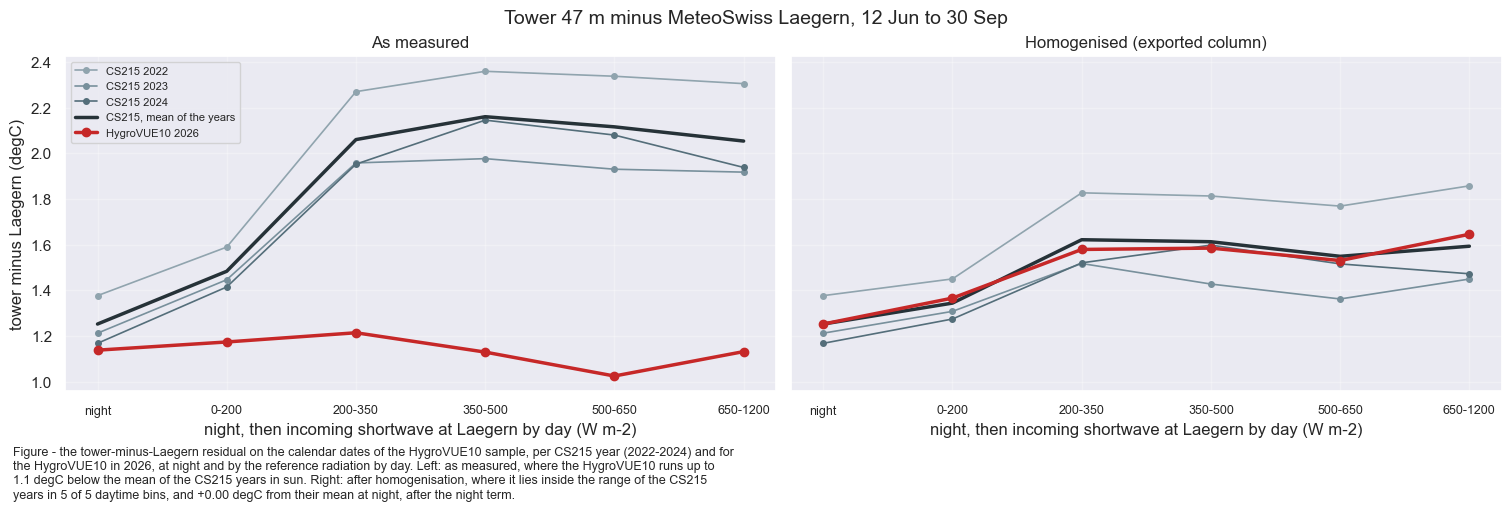

In [65]:
# The two tables above, drawn. One line per CS215 year and one for the HygroVUE10, as measured and
# homogenised, on the same axes so the two panels can be read across.
fig, axs = plt.subplots(ncols=2, figsize=(15, 5), dpi=100, layout="constrained", sharey=True)
fig.suptitle(f"Tower 47 m minus MeteoSwiss Laegern, {HV_FIT_START:%d %b} to {_hv_end:%d %b}",
             fontsize=14)
_x = np.arange(len(hv_raw_profile.columns))
_cs_colours = ['#90A4AE', '#78909C', '#546E7A', '#37474F']
for _ax, _tab, _title in [(axs[0], hv_raw_profile, 'As measured'),
                          (axs[1], hv_homog_profile, 'Homogenised (exported column)')]:
    for _y, _colour in zip(HV_CS215_YEARS, _cs_colours):
        _ax.plot(_x, _tab.loc[f"CS215 {_y}"], 'o-', color=_colour, lw=1.2, ms=4,
                 label=f"CS215 {_y}")
    _ax.plot(_x, _tab.loc['CS215, mean of the years'], '-', color='#263238', lw=2.5,
             label='CS215, mean of the years')
    _ax.plot(_x, _tab.loc[f"HygroVUE10 {HV_START.year}"], 'o-', color='#C62828', lw=2.5, ms=6,
             label=f"HygroVUE10 {HV_START.year}")
    _ax.set_xticks(_x)
    _ax.set_xticklabels([_c.replace('day, ', '').replace(' W m-2', '') for _c in _tab.columns],
                        fontsize=9)
    _ax.set_xlabel("night, then incoming shortwave at Laegern by day (W m-2)")
    _ax.set_title(_title)
    _ax.grid(alpha=0.3)
axs[0].set_ylabel("tower minus Laegern (degC)")
axs[0].legend(fontsize=8, loc='upper left')
# The caption's claims are counted off the table it draws, not written down.
_cs_rows = [f"CS215 {_y}" for _y in HV_CS215_YEARS]
_hv_row = hv_homog_profile.loc[f"HygroVUE10 {HV_START.year}"]
_inside = [_c for _c in HV_DAY_COLS.values()
           if hv_homog_profile.loc[_cs_rows, _c].min() <= _hv_row[_c] <= hv_homog_profile.loc[_cs_rows, _c].max()]
figcap(fig, f"the tower-minus-Laegern residual on the calendar dates of the HygroVUE10 sample, "
            f"per CS215 year ({HV_CS215_YEARS[0]}-{HV_CS215_YEARS[-1]}) and for the HygroVUE10 "
            f"in {HV_START.year}, at night and by the reference radiation by day. Left: as "
            f"measured, where the HygroVUE10 runs up to "
            f"{-hv_raw_profile.loc['HygroVUE10 minus CS215', list(HV_DAY_COLS.values())].min():.1f} degC "
            f"below the mean of the CS215 years in sun. Right: after homogenisation, where it lies "
            f"inside the range of the CS215 years in {len(_inside)} of {len(HV_DAY_COLS)} daytime "
            f"bins, and {hv_homog_profile.loc['HygroVUE10 minus CS215', 'night']:+.2f} degC from "
            f"their mean at night"
            + (", where no night term is applied." if HV_TERMS['night'] == 0.0 else
               ", after the night term."))

#### Limitations of the HygroVUE10 term

- **One summer.** The transfer is fitted on 12 June to 30 September 2026 and applied, as fitted,
  to every HygroVUE10 record, including 5 to 11 June. Its behaviour in winter, under snow or rime
  and at low sun is untested.
- **One reference.** Lägern is 2.5 km away and about 100 m higher, and both the fit and the score
  use it. The month hold-out tests whether the transfer carries to data it was not fitted on, not
  whether it agrees with an independent instrument.
- **The CS215 level is a mean of three summers** that differ among themselves at night by an
  amount comparable to the night term itself, so the night term is uncertain by that amount
  (printed above).
  The hold-out table shows how much it changes when one month is left out.
- **The reference level is unchanged.** Like the CS215 era, the HygroVUE10 era ends on the shield
  behaviour of the MP101A, so the limitations of step 🔟 apply to it as well.

#### What the break does to the numbers this product is used for

The figures this notebook states are computed here rather than quoted. They use **measured
records only**, so gap-filling has no influence on them.

#### 📋 Table: yearly means from measured records

In [66]:
# Yearly means from measured records only, before and after the full correction (constant and
# shield term), so they match the exported column. The shield term acts per record, so it is
# applied before resampling.
# 2016 is in neither period: the changeover happened inside it, and its measured mean misses the
# first three weeks of January, which would make it read warm.
# A yearly mean covers only what was measured; the record counts are shown because 2012 lost
# about 1,200 records, mostly in summer.
# These figures describe the product, so every era enters, each homogenised as exported. They are
# not a test of the normal CS215: that is steps 9 and 10, which hold codes 0 and 1 only.
_meas_series = ta_2004_2026['TA_T1_47_1']
_homog_series = pd.Series(
    homogenize(_meas_series, _meas_series.index, swin_gf[SWIN_COL].reindex(_meas_series.index)),
    index=_meas_series.index).where(_meas_series.notna())

_ymeas = _meas_series.resample('YE').mean()
_ncount = _meas_series.resample('YE').count()
_yhomog = _homog_series.resample('YE').mean()
_yhomog.index = _yhomog.index.year
_ymeas.index, _ncount.index = _ymeas.index.year, _ncount.index.year
_ymeas = _ymeas.loc[2005:LAST_FULL_YEAR]          # 2004 has no measurement before 20 September
_ncount = _ncount.loc[2005:LAST_FULL_YEAR]
# Eras are split by whole calendar year here, which is only correct because the break year holds
# no measurement before the break. For a mid-year break this would silently mix the two eras
# inside one annual mean.
_bk = ta_2004_2026.loc[ta_2004_2026.index.year == BREAK.year, 'TA_T1_47_1']
assert _bk[_bk.index < BREAK].notna().sum() == 0, (
    f"{BREAK.year} holds measurements before the break, so an era split by calendar year mixes "
    f"the two sensors inside that year's mean")

_yhomog = _yhomog.loc[2005:LAST_FULL_YEAR]

_split = BREAK.year
_early = _ymeas.index < _split
_recent = _ymeas.index > _split     # strictly greater: 2016 is in neither period

tabcap("yearly means from measured records only, as reported and after the full correction, "
       "with the period each year belongs to. The break year is in neither period")
display(pd.DataFrame({'measured (degC)': _ymeas, 'homogenised (degC)': _yhomog,
                      'measured records': _ncount,
                      'period': np.where(_early, f'{_ymeas.index.min()}-{_split - 1}',
                                         np.where(_recent, f'{_split + 1}-{_ymeas.index.max()}',
                                                  'excluded'))}).round(2))

Table - yearly means from measured records only, as reported and after the full correction, with the
period each year belongs to. The break year is in neither period



,measured (degC),homogenised (degC),measured records,period
TIMESTAMP_MIDDLE,,,,
2005,7.46,8.77,17486,2005-2015
2006,7.96,9.28,17494,2005-2015
2007,8.11,9.43,17507,2005-2015
2008,7.59,8.91,17548,2005-2015
2009,7.66,8.98,17036,2005-2015
2010,6.68,8.00,17351,2005-2015
2011,8.78,10.10,17499,2005-2015
2012,7.57,8.89,16306,2005-2015
2013,7.08,8.40,17434,2005-2015


#### 📋 Table: period difference and trend from measured records

In [67]:
_rows = []
for _name, _s in [('as measured', _ymeas), ('homogenised', _yhomog)]:
    _slope, _, _lo, _hi = theilslopes(_s.to_numpy(float), _s.index.to_numpy(float), alpha=0.95)
    _tau, _p = kendalltau(_s.index.to_numpy(float), _s.to_numpy(float))
    _rows.append({'series': _name,
                  f'{_ymeas.index.min()}-{_split - 1} (degC)': _s[_early].mean(),
                  f'{_split + 1}-{_ymeas.index.max()} (degC)': _s[_recent].mean(),
                  'difference (degC)': _s[_recent].mean() - _s[_early].mean(),
                  'Theil-Sen (degC/decade)': _slope * 10,
                  'lower 95 %': _lo * 10, 'upper 95 %': _hi * 10,
                  'Kendall tau': _tau, 'p': _p})
# Kept as a name: the export section shows it beside the same figures computed from the finished
# columns, because the two do not agree and the reason is worth stating.
headline_measured = pd.DataFrame(_rows).set_index('series')
tabcap("the period difference and the trend from measured records only, as measured and "
       "homogenised. The change between the two rows is entirely instrumental: the constant "
       "lifts the earlier era and the shield term cools the later one")
display(headline_measured.round(3))
# The two terms move the two periods in opposite directions, so the size of each is stated
# rather than left to be read off the table.
_early_shift = (_yhomog[_early] - _ymeas[_early]).mean()
_recent_shift = (_yhomog[_recent] - _ymeas[_recent]).mean()
print(f"The correction raises the {_split - 1}-and-earlier years by {_early_shift:+.2f} degC (the "
      f"constant, applied whole)\nand lowers the {_split + 1}-and-later ones by "
      f"{abs(_recent_shift):.2f} degC (the shield term, which depends on radiation\nand so averages "
      f"to less than its maximum). Both are instrumental, so the whole of the change in the\nperiod "
      f"difference and in the trend is the instrument, not the climate.")
print(f"The trend uses every year including {_split}; only the two period means exclude it.")

assert abs(_early_shift - OFFSET) < 1e-9, \
    "the earlier era no longer moves by exactly the constant, which is what it is defined to do"
assert _recent_shift < 0, \
    "the shield term no longer cools the later era - it can only ever remove warming"

Table - the period difference and the trend from measured records only, as measured and homogenised.
The change between the two rows is entirely instrumental: the constant lifts the earlier era and the
shield term cools the later one



,2005-2015 (degC),2017-2025 (degC),difference (degC),Theil-Sen (degC/decade),lower 95 %,upper 95 %,Kendall tau,p
series,,,,,,,,
as measured,7.848,10.323,2.475,1.802,1.16,2.483,0.590,0.000
homogenised,9.168,10.170,1.003,0.767,0.29,1.282,0.476,0.002


The correction raises the 2015-and-earlier years by +1.32 degC (the constant, applied whole)
and lowers the 2017-and-later ones by 0.15 degC (the shield term, which depends on radiation
and so averages to less than its maximum). Both are instrumental, so the whole of the change in the
period difference and in the trend is the instrument, not the climate.
The trend uses every year including 2016; only the two period means exclude it.


#### 📊 Plot: yearly means, as measured and homogenised

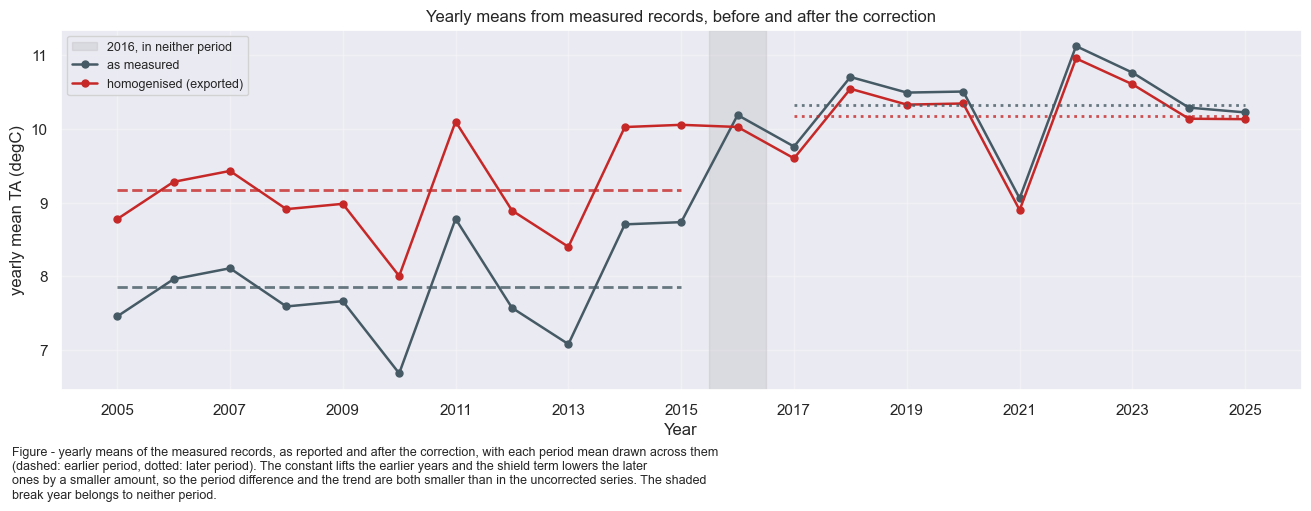

In [68]:
# The two columns as yearly means, with the periods the table above compares. Drawn from the same
# arrays, so the figure cannot disagree with the numbers beside it.
fig, ax = plt.subplots(figsize=(13, 5), dpi=100, layout="constrained")
ax.axvspan(_split - 0.5, _split + 0.5, color='#9E9E9E', alpha=0.2,
           label=f"{_split}, in neither period")
ax.plot(_ymeas.index, _ymeas.to_numpy(), 'o-', color='#455A64', lw=1.8, ms=5, label='as measured')
ax.plot(_yhomog.index, _yhomog.to_numpy(), 'o-', color='#C62828', lw=1.8, ms=5,
        label='homogenised (exported)')
for _s, _colour in [(_ymeas, '#455A64'), (_yhomog, '#C62828')]:
    for _mask, _style in [(_early, '--'), (_recent, ':')]:
        ax.hlines(_s[_mask].mean(), _s.index[_mask].min(), _s.index[_mask].max(),
                  color=_colour, lw=2, ls=_style, alpha=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("yearly mean TA (degC)")
ax.set_title("Yearly means from measured records, before and after the correction")
ax.set_xticks(list(_ymeas.index)[::2])
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
figcap(fig, "yearly means of the measured records, as reported and after the correction, with "
            "each period mean drawn across them (dashed: earlier period, dotted: later period). "
            "The constant lifts the earlier years and the shield term lowers the later ones by a "
            "smaller amount, so the period difference and the trend are both smaller than in the "
            "uncorrected series. The shaded break year belongs to neither period.")

#### What the correction does not fix

The first item is measured in steps 9️⃣ and 🔟 against MeteoSwiss, which entered neither term. The
three-year window and, for the constant, the full eras give the same result.

- **The shield error the two sensors share remains.** Both eras carry the MP101A's own error and
  read warm in sun and light wind throughout the record. **Daily maxima and diurnal ranges are
  biased warm in every year**, by a comparable amount on both sides of 2016. The step that
  survives is the `shield` row of the step table in step 🔟. Removing the shared error would
  require the aspirated scale, rejected above.
- **The radiative term depends on a gap-filled driver** (`SW_IN_T1_47_1_gfXG`). Refitting on
  measured radiation alone changes it by hundredths of a degree, because the driver is almost
  complete over the CS215 era.
- **The records reconstructed from NABEL carry too little scatter.** As values on a fitted line,
  those 1,530 records sit about 0.05 °C from NABEL, where a real measurement sits about 0.25 °C
  from it. Their means are sound; **variance, extremes and other spread statistics over the
  periods they cover are understated.** Most fall in January 2004; the export section gives the
  breakdown by month.
- **2004 has no measurement before 20 September.** 72 % of that year is modelled, and January is
  reconstructed from NABEL rather than gap-filled, because MeteoSwiss begins on 1 February 2004.
  It carries source code `3` and is the least constrained year.
- **The mechanism of the zero-point error is inferred.** The class of error is established;
  whether the 11 mV came from the probe's zero trim or from a ground offset in the cabling is not.
- **The heated CS215 (code 7) stays too warm in sun.** It is corrected as the normal CS215 only;
  step 1️⃣1️⃣ measures what remains. The night term of the CS215 after May 2025 (code 6) is smaller
  than its uncertainty. Both are listed at the end of step 1️⃣1️⃣.
- **The HygroVUE10 term rests on one summer and one reference.** Its limitations are listed at the
  end of step 1️⃣2️⃣.

***

***

## 🟦 Drivers

Three drivers feed the gap-filling:

- **Gap-filled `SW_IN`** from notebook `01`, which must run first. It is already loaded for the
  break section. Radiation drives the daily temperature cycle.
- **`SW_IN_POT`**, potential radiation from the site coordinates: day length and season, gap-free.
- **MeteoSwiss Lägern `TA_LAE_MS`**, an independent temperature measurement 2.5 km away, added
  below with an alignment guard.

NABEL (`TA_NABEL_T1_49_1`) is added per period where available.

In [69]:
# SW_IN_POT from the site coordinates.
swinpot = dv.variables.potrad(
    timestamp_index=ta_2004_2026.index,
    lat=SITE_LAT,
    lon=SITE_LON,
    utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS,
)

drivers = pd.DataFrame(index=ta_2004_2026.index)
drivers[SWIN_COL] = swin_gf[SWIN_COL]  # keeps the name it has in the file; aligned on the index
drivers['SW_IN_POT'] = swinpot

# Both drivers must be complete, otherwise records fall back to the timestamp-only model.
print(drivers.isnull().sum().rename('missing values'))
drivers.describe()

SW_IN_T1_47_1_gfXG    0
SW_IN_POT             0
Name: missing values, dtype: int64


,SW_IN_T1_47_1_gfXG,SW_IN_POT
count,398832.000000,398832.000000
mean,147.611918,300.521731
std,241.952322,383.652942
min,0.000000,0.000000
25%,0.000000,0.000000
50%,4.298509,18.896021
75%,201.665094,571.615871
max,1118.658439,1214.125501


### 🌍 MeteoSwiss Lägern

Independent air temperature 2.5 km away. Its `TIMESTAMP_END` index is shifted back 15 minutes to
the `TIMESTAMP_MID` used here. The guard asserts that the correlation with the measured tower `TA`
peaks at offset 0: a mis-shifted reference would teach the model a wrong daily cycle without any
sign in the output.

In [70]:
ta_ref = pd.read_parquet(REFPATH)[[REFCOL]]
ta_ref.index = ta_ref.index - pd.Timedelta(minutes=15)  # TIMESTAMP_END -> TIMESTAMP_MID
ta_ref.index.name = ta_2004_2026.index.name

_meas = ta_2004_2026['TA_T1_47_1']
_scores = {}
for _off in (-1, 0, 1):
    _j = pd.concat([_meas.rename('t'), ta_ref[REFCOL].shift(_off).rename('r')], axis=1).dropna()
    _scores[_off] = _j['t'].corr(_j['r'])
    print(f"  offset {_off:+d} x 30min: corr {_scores[_off]:.4f}")
assert max(_scores, key=_scores.get) == 0, f"reference is mis-aligned: {_scores}"
print("OK: offset 0 wins, the TIMESTAMP_MID conversion is correct.")

drivers[REFCOL] = ta_ref[REFCOL]
print(f"\n{REFCOL} available for {drivers[REFCOL].notna().mean() * 100:.2f}% of records")
drivers.describe()

  offset -1 x 30min: corr 0.9892
  offset +0 x 30min: corr 0.9896
  offset +1 x 30min: corr 0.9881
OK: offset 0 wins, the TIMESTAMP_MID conversion is correct.

TA_LAE_MS available for 99.56% of records


,SW_IN_T1_47_1_gfXG,SW_IN_POT,TA_LAE_MS
count,398832.000000,398832.000000,397072.000000
mean,147.611918,300.521731,8.453385
std,241.952322,383.652942,7.945543
min,0.000000,0.000000,-17.700000
25%,0.000000,0.000000,2.333333
50%,4.298509,18.896021,8.433333
75%,201.665094,571.615871,14.366667
max,1118.658439,1214.125501,33.366667


***

## 🟪 Prepare dataframes

Split into five periods, gap-filled separately. The four boundaries have different causes:

- **The sensor change on 21 January 2016.** A model trained across this 1.3 °C discontinuity
  produces values on neither era's level. The boundary is what makes the homogenisation valid for
  filled records.
- **The end of NABEL**, a change of drivers, with the same instrument.
- **The CS215 change on 16 May 2025** (step 1️⃣1️⃣) and **the probe change on 5 June 2026**
  (CS215 to HygroVUE10, step 1️⃣2️⃣), for the same reason as the first. The probe half-hour before
  each belongs to the period before it.

The onset of the excess heating (code `7`, autumn 2024) is not a boundary: the excess grew over
weeks, so there is no record at which a model could be split, and the few gaps of code `7` are
filled by the model of `P3`.

The January 2016 outage belongs to the first period, so the offset region and `P1` cover the same
span. The measured column then steps only at the sensor changes, and the homogenised column is
continuous across them. The first two cut-offs are taken from the data; the other two are
settings, checked against the data and the fieldbook in steps 1️⃣1️⃣ and 1️⃣2️⃣.

### 📋 Table: the five gap-filling periods

In [71]:
# Last year in which NABEL delivers a usable amount of data.
_nabel_per_year = ta_2004_2026['TA_NABEL_T1_49_1'].groupby(ta_2004_2026.index.year).count()
print("NABEL records per year:")
print(_nabel_per_year.to_string())
NABEL_LAST_YEAR = int(_nabel_per_year[_nabel_per_year > 0].index.max())
print(f"\nNABEL is used as driver up to and including {NABEL_LAST_YEAR}.")

# The five periods. P1 ends on the last record before the sensor change, so it carries the
# January 2016 outage: those records are modelled, and filling them with the earlier model puts
# them on the earlier era's level, which is what the offset below then corrects. P3 ends on the
# probe handling record of 16 May 2025 and holds code 7 as well; P3b is the CS215 after the
# handling (code 6) and ends on the probe swap record; P4 is the HygroVUE10 era.
_nabel_end = ta_2004_2026.loc[:f"{NABEL_LAST_YEAR}-12-31 23:59"].index[-1]
PERIODS = {
    'P1': dict(start=ta_2004_2026.index[0], stop=BREAK - pd.Timedelta('30min'), use_nabel=True,
               label=f'MP101A era, NABEL available (to {(BREAK - pd.Timedelta("30min")):%d %b %Y})'),
    'P2': dict(start=BREAK, stop=_nabel_end, use_nabel=True,
               label=f'CS215 era, NABEL available (to {_nabel_end:%d %b %Y})'),
    'P3': dict(start=_nabel_end + pd.Timedelta('30min'), stop=HANDLING_RECORD, use_nabel=False,
               label=f'CS215 era, NABEL has stopped (to {HANDLING_RECORD:%d %b %Y})'),
    'P3b': dict(start=RESET_START, stop=SWAP_RECORD, use_nabel=False,
                label=f'CS215 after the May 2025 change (to {SWAP_RECORD:%d %b %Y})'),
    'P4': dict(start=HV_START, stop=ta_2004_2026.index[-1], use_nabel=False,
               label='HygroVUE10 era, NABEL has stopped'),
}

_summary = []
for _k, _p in PERIODS.items():
    _slice = ta_2004_2026.loc[_p['start']:_p['stop']]
    _summary.append({'period': _k, 'label': _p['label'],
                     'from': _p['start'], 'to': _p['stop'], 'records': len(_slice),
                     'measured': int(_slice['TA_T1_47_1'].notna().sum()),
                     'NABEL as driver': _p['use_nabel']})
tabcap("the five gap-filling periods, their boundaries and the measured share of each. No model spans a sensor change")
display(pd.DataFrame(_summary).set_index('period'))

# The periods must tile the record exactly once, and none may span the sensor change - that is the
# whole point of the split, and it is cheap to assert.
_covered = pd.concat([pd.Series(True, index=ta_2004_2026.loc[_p['start']:_p['stop']].index)
                      for _p in PERIODS.values()])
assert len(_covered) == len(ta_2004_2026), \
    f"the periods cover {len(_covered)} of {len(ta_2004_2026)} records"
assert not _covered.index.duplicated().any(), "the periods overlap"
assert _covered.index.equals(ta_2004_2026.index), "the periods do not tile the record in order"
for _k, _p in PERIODS.items():
    assert not (_p['start'] < BREAK < _p['stop']), \
        f"period {_k} spans the sensor change - a model trained on it would learn both eras"
    # Each period lies wholly on one side of each sensor change. This form also catches a period
    # whose first or last record is the change itself.
    for _change, _at in [('the 2016 sensor change', BREAK), ('the May 2025 CS215 change', RESET_START),
                         ('the 2026 probe change', HV_START)]:
        assert _p['stop'] < _at or _p['start'] >= _at, \
            f"period {_k} spans {_change} - a model trained on it would learn both sensors"
assert PERIODS['P3']['start'] <= HANDLING_RECORD <= PERIODS['P3']['stop'], \
    "the probe handling record is not in the CS215 period before the May 2025 change"
assert PERIODS['P3b']['start'] <= SWAP_RECORD <= PERIODS['P3b']['stop'], \
    "the probe swap record is not in the CS215 period before the probe change"
assert PERIODS['P3b']['start'] == RESET_START, "P3b does not start at the May 2025 change"
# Code 7 is not a boundary: it lies wholly inside P3, whose model fills its gaps.
assert PERIODS['P3']['start'] <= EXCESS_START and HANDLING_RECORD <= PERIODS['P3']['stop'], \
    "code 7 does not lie inside P3"
_c7_gaps = int(ta_2004_2026.loc[EXCESS_START:HANDLING_RECORD - pd.Timedelta('30min'), 'TA_T1_47_1'].isna().sum())
print(f"code 7 gaps, filled by the P3 model: {_c7_gaps}")
assert PERIODS['P4']['start'] == HV_START, "the HygroVUE10 period does not start at the probe change"
# The HygroVUE10 period is one summer. It is fitted on its own rather than merged with P3, so it
# must hold enough measured records for a model; fewer would have to be said, not merged away.
for _k in ('P3b', 'P4'):
    _measured = int(ta_2004_2026.loc[PERIODS[_k]['start']:PERIODS[_k]['stop'], 'TA_T1_47_1'].notna().sum())
    assert _measured > 2_000, f"period {_k} holds only {_measured} measured records"
print("\nOK: five periods, tiling the record exactly once, none spanning a sensor change.")


NABEL records per year:
TIMESTAMP_MIDDLE
2004    17508
2005    17266
2006    17515
2007    17508
2008    17561
2009    17507
2010    17441
2011    17500
2012    17453
2013    17519
2014    17518
2015    17516
2016    17557
2017    17514
2018    17520
2019        0
2020        0
2021        0
2022        0
2023        0
2024        0
2025        0
2026        0

NABEL is used as driver up to and including 2018.
Table - the five gap-filling periods, their boundaries and the measured share of each. No model
spans a sensor change



,label,from,to,records,measured,NABEL as driver
period,,,,,,
P1,"MP101A era, NABEL available (to 21 Jan 2016)",2004-01-01 00:15:00,2016-01-21 13:45:00,211372,195592,True
P2,"CS215 era, NABEL available (to 31 Dec 2018)",2016-01-21 14:15:00,2018-12-31 23:45:00,51620,51612,True
P3,"CS215 era, NABEL has stopped (to 16 May 2025)",2019-01-01 00:15:00,2025-05-16 09:45:00,111716,110840,False
P3b,CS215 after the May 2025 change (to 05 Jun 2026),2025-05-16 10:15:00,2026-06-05 11:15:00,18483,18482,False
P4,"HygroVUE10 era, NABEL has stopped",2026-06-05 11:45:00,2026-09-30 23:45:00,5641,5641,False


code 7 gaps, filled by the P3 model: 1

OK: five periods, tiling the record exactly once, none spanning a sensor change.


***

## 🟥 Gap-filling

### Method

`SWINGapFillerXGBoost` (notebook `01`) is specific to radiation: it zeroes nighttime gaps and
negative predictions, removes a nighttime offset and interpolates the clearness index.
**None of this is valid for temperature**; it would write 0 °C into every nighttime and frost gap.
This notebook uses the general `XGBoostTS` with an explicit `FeatureEngineer` (what
`SWINGapFillerXGBoost` wraps internally) and otherwise follows `01`: drivers plus timestamp
features, SHAP-based feature reduction, and interpolation of short gaps.

- **`features_lag=[]`.** The model predicts only records with every feature present, so lagging a
  gappy driver would send more records to the weaker timestamp-only fallback.
- **`SW_IN_POT` is excluded from the rolling and EMA stages.** It follows from the timestamp, so
  smoothed versions add features without adding information.
- **`shap_max_rows=10_000`.** SHAP is the slowest step, computed four times per call (train,
  reduce, retrain, fill). Mean importances converge well before the full record, so rows are
  capped as in `SWINGapFillerXGBoost`. Only the importances and the feature reduction use the
  sample, which is reproducible through `random_state`; predictions and scores do not.
- **Hyperparameters are set explicitly**, to the values `SWINGapFillerXGBoost` uses, because
  `XGBoostTS` ships no tuned defaults.

**Short gaps** (up to 1 h) are then filled by linear interpolation and flagged `4`. The target is
excluded from its own features, so the model cannot see a gap's measured neighbours. Temperature is
continuous across midnight, so the interpolation is not restricted to single days.

In [72]:
SHAP_MAX_ROWS = 10_000  # rows used for SHAP importances, see the note above


def short_gap_mask(series: pd.Series, limit: int) -> pd.Series:
    """True where `series` is missing AND its whole gap is at most `limit` records long.

    Whole runs are selected explicitly. Using pandas' `interpolate(limit=)` instead would fill
    the first `limit` records of a long gap as well, which is not wanted: those values would sit
    on a straight line spanning the entire gap.
    """
    missing = series.isna()
    run_length = missing.groupby((~missing).cumsum()).transform('sum')
    return missing & (run_length <= limit)


def gapfill_ta(target: pd.Series,
               drivers: pd.DataFrame,
               interpolate_limit: int = 2,
               reduce_features: bool = True,
               verbose: int = 1):
    """Gap-fill a temperature series with XGBoost, then interpolate the remaining short gaps.

    Returns (model, gapfilled, flag). `gapfilled` carries the `_gfXG` name, `flag` follows
    FLAG_LEGEND.
    """
    input_df = pd.concat([target, drivers], axis=1)

    engineer = dv.gapfilling.FeatureEngineer(
        target_col=target.name,
        features_lag=[],  # see the note above
        features_rolling=[4, 8, 24, 48],  # 2h, 4h, 12h, 24h on 30MIN data
        features_rolling_stats=['median'],
        features_rolling_exclude_cols=['SW_IN_POT'],  # deterministic, see the note above
        features_ema=[6, 24],  # 3h, 12h
        features_ema_exclude_cols=['SW_IN_POT'],
        vectorize_timestamps=True,
        add_continuous_record_number=True,
        verbose=0,
    )
    features_df = engineer.fit_transform(input_df)
    print(f"Features: {features_df.shape[1] - 1} over {len(features_df):,} records")

    model = dv.gapfilling.XGBoostTS(
        input_df=features_df,
        target_col=target.name,
        verbose=verbose,
        shap_max_rows=SHAP_MAX_ROWS,
        n_estimators=3000,
        max_depth=6,
        early_stopping_rounds=20,
        random_state=42,
        n_jobs=-1,
    )
    model.trainmodel(showplot_scores=False, showplot_importance=False)
    if reduce_features:
        model.reduce_features()
        model.trainmodel(showplot_scores=False, showplot_importance=False)
    model.fillgaps(showplot_scores=False, showplot_importance=False)

    gapfilled = model.results.gapfilled.copy()
    flag = model.results.flag.copy()

    if interpolate_limit:
        short = short_gap_mask(target, interpolate_limit)
        interp = target.interpolate(method='time', limit_area='inside')
        fill_locs = short & interp.notna()
        gapfilled[fill_locs] = interp[fill_locs]
        flag[fill_locs] = 4
        print(f"Short-gap interpolation: {int(fill_locs.sum())} records")

    gapfilled = gapfilled.rename(f"{target.name}_gfXG")
    flag = flag.rename(f"FLAG_{target.name}_ISFILLED")
    return model, gapfilled, flag

***

### 🟥 Gap-filling, one model per period

Each period is fitted separately, so no model sees more than one sensor era. `P1` and `P2` use
measured NABEL (`TA_NABEL_T1_49_1`, 49 m, same tower) with its gaps, MeteoSwiss Lägern
(`TA_LAE_MS`), gap-filled `SW_IN` and `SW_IN_POT`. Lägern carries the signal where NABEL is
missing. NABEL is no longer gap-filled from the tower first, which had let the tower partly predict
itself. `P3`, `P3b` and `P4` have no NABEL.

In [73]:
%%time

TARGET = "TA_T1_47_1"

# One fit per period. Keeping the fitted objects lets the scores, the feature importances and the
# heatmaps below be shown per period without refitting anything.
results = {}
for _key, _p in PERIODS.items():
    print(f"\n{'=' * 78}\n{_key}: {_p['label']}\n{'=' * 78}")
    _ta = ta_2004_2026.loc[_p['start']:_p['stop']].copy()
    _dr = drivers.loc[_p['start']:_p['stop']].copy()
    if _p['use_nabel']:
        # NABEL enters as measured (gappy); Laegern, already in drivers, covers its gaps.
        _dr = pd.concat([_ta[['TA_NABEL_T1_49_1']], _dr], axis=1)
    else:
        _ta = _ta.drop(columns='TA_NABEL_T1_49_1')
    _model, _gapfilled, _flag = gapfill_ta(target=_ta[TARGET], drivers=_dr)
    results[_key] = dict(model=_model, gapfilled=_gapfilled, flag=_flag, ta=_ta, **_p)



P1: MP101A era, NABEL available (to 21 Jan 2016)
Features: 61 over 211,372 records


! Some features are incomplete (<211372 values): TA_NABEL_T1_49_1 (210800), TA_LAE_MS (209790), 
.TA_NABEL_T1_49_1_MEAN4 (210892), .TA_LAE_MS_MEAN4 (209796), .TA_NABEL_T1_49_1_SD4 (210892), 
.TA_LAE_MS_SD4 (209796), .TA_NABEL_T1_49_1_MEAN8 (210946), .TA_LAE_MS_MEAN8 (209804), 
.TA_NABEL_T1_49_1_SD8 (210946), .TA_LAE_MS_SD8 (209804), .TA_NABEL_T1_49_1_MEAN24 (211074), 
.TA_LAE_MS_MEAN24 (209836), .TA_NABEL_T1_49_1_SD24 (211074), .TA_LAE_MS_SD24 (209836), 
.TA_NABEL_T1_49_1_MEAN48 (211210), .TA_LAE_MS_MEAN48 (209869), .TA_NABEL_T1_49_1_SD48 (211210), 
.TA_LAE_MS_SD48 (209869), .TA_NABEL_T1_49_1_ROLLMEDIAN4 (210892), .TA_LAE_MS_ROLLMEDIAN4 (209796), 
.TA_NABEL_T1_49_1_ROLLMEDIAN8 (210946), .TA_LAE_MS_ROLLMEDIAN8 (209804), 
.TA_NABEL_T1_49_1_ROLLMEDIAN24 (211074), .TA_LAE_MS_ROLLMEDIAN24 (209836), 
.TA_NABEL_T1_49_1_ROLLMEDIAN48 (211210), .TA_LAE_MS_ROLLMEDIAN48 (209869), .TA_LAE_MS_EMA6 (209883),
.TA_LAE_MS_EMA24 (209883)

! Not all target values can be predicted based on the full model.

Short-gap interpolation: 169 records

P2: CS215 era, NABEL available (to 31 Dec 2018)
Features: 61 over 51,620 records


! Some features are incomplete (<51620 values): TA_NABEL_T1_49_1 (51603), .TA_NABEL_T1_49_1_MEAN4 
(51617), .TA_NABEL_T1_49_1_SD4 (51617), .TA_NABEL_T1_49_1_ROLLMEDIAN4 (51617)

! Not all target values can be predicted based on the full model.

Short-gap interpolation: 1 records

P3: CS215 era, NABEL has stopped (to 16 May 2025)
Features: 46 over 111,716 records


! Some features are incomplete (<111716 values): TA_LAE_MS (111538), .TA_LAE_MS_MEAN4 (111544), 
.TA_LAE_MS_SD4 (111544), .TA_LAE_MS_MEAN8 (111552), .TA_LAE_MS_SD8 (111552), .TA_LAE_MS_MEAN24 
(111584), .TA_LAE_MS_SD24 (111584), .TA_LAE_MS_MEAN48 (111622), .TA_LAE_MS_SD48 (111622), 
.TA_LAE_MS_ROLLMEDIAN4 (111544), .TA_LAE_MS_ROLLMEDIAN8 (111552), .TA_LAE_MS_ROLLMEDIAN24 (111584), 
.TA_LAE_MS_ROLLMEDIAN48 (111622)

! Not all target values can be predicted based on the full model.

Short-gap interpolation: 8 records

P3b: CS215 after the May 2025 change (to 05 Jun 2026)
Features: 46 over 18,483 records
Short-gap interpolation: 0 records

P4: HygroVUE10 era, NABEL has stopped
Features: 46 over 5,641 records
Short-gap interpolation: 0 records
CPU times: total: 1h 46min 26s
Wall time: 7min 37s


#### Results: scores, flag counts and feature importances

#### 📋 Table: held-out scores and fill methods per period

In [74]:
for _key, _r in results.items():
    print(f"\n{'=' * 78}\n{_key}: {_r['label']}\n{'=' * 78}")
    print("Held-out (train/test) scores:")
    tabcap(f"held-out (train/test) scores of the {_key} model")
    display(pd.Series(_r['model'].results.scores_traintest))
    print("Flag counts:")
    tabcap(f"how {_key} filled the gaps of its period, by method")
    display(_r['flag'].value_counts().sort_index().rename(index=FLAG_LEGEND))



P1: MP101A era, NABEL available (to 21 Jan 2016)
Held-out (train/test) scores:
Table - held-out (train/test) scores of the P1 model



mae      1.317702e-01
medae    9.161758e-02
mse      3.673045e-02
rmse     1.916519e-01
mape     5.356912e+10
maxe     2.793776e+00
r2       9.994327e-01
dtype: float64

Flag counts:
Table - how P1 filled the gaps of its period, by method



FLAG_TA_T1_47_1_ISFILLED
0 = observed                                                                  195592
1 = gap-filled by the XGBoost model                                            14042
2 = gap-filled by the timestamp-only fallback model (a driver was missing)      1569
4 = gap-filled by linear interpolation (short gap)                               169
Name: count, dtype: int64


P2: CS215 era, NABEL available (to 31 Dec 2018)
Held-out (train/test) scores:
Table - held-out (train/test) scores of the P2 model



...

FLAG_TA_T1_47_1_ISFILLED
0 = observed                           18482
1 = gap-filled by the XGBoost model        1
Name: count, dtype: int64


P4: HygroVUE10 era, NABEL has stopped
Held-out (train/test) scores:
Table - held-out (train/test) scores of the P4 model



mae      0.267335
medae    0.201315
mse      0.126244
rmse     0.355309
mape     0.013520
maxe     1.834635
r2       0.994807
dtype: float64

Flag counts:
Table - how P4 filled the gaps of its period, by method



FLAG_TA_T1_47_1_ISFILLED
0 = observed    5641
Name: count, dtype: int64

#### 📋 Table: feature importances per period

In [75]:
for _key, _r in results.items():
    print(f"{_key}: {_r['label']}")
    tabcap(f"feature importances of the {_key} model")
    display(_r['model'].results.feature_importances)


P1: MP101A era, NABEL available (to 21 Jan 2016)
Table - feature importances of the P1 model



,SHAP_IMPORTANCE,SHAP_SD
TA_NABEL_T1_49_1,6.019064,3.849415
TA_LAE_MS,0.405539,0.291401
.TA_NABEL_T1_49_1_ROLLMEDIAN4,0.193795,0.184234
SW_IN_T1_47_1_gfXG,0.151289,0.091508
SW_IN_POT,0.066081,0.034606
...,...,...
.TA_LAE_MS_SD8,0.013000,0.012860
.TA_NABEL_T1_49_1_MEAN8,0.012828,0.013146
.TA_NABEL_T1_49_1_SD24,0.012438,0.013495
.WEEK_SIN,0.010753,0.012865


P2: CS215 era, NABEL available (to 31 Dec 2018)
Table - feature importances of the P2 model



,SHAP_IMPORTANCE,SHAP_SD
TA_NABEL_T1_49_1,6.132328,3.822480
TA_LAE_MS,0.518760,0.331413
SW_IN_T1_47_1_gfXG,0.317568,0.180380
.TA_NABEL_T1_49_1_ROLLMEDIAN4,0.231307,0.130746
SW_IN_POT,0.114548,0.063333
...,...,...
.TA_LAE_MS_SD8,0.011069,0.010695
.TA_NABEL_T1_49_1_SD8,0.010831,0.011944
.TA_LAE_MS_MEAN8,0.010514,0.008345
.YEARMONTH,0.007977,0.015844


P3: CS215 era, NABEL has stopped (to 16 May 2025)
Table - feature importances of the P3 model



,SHAP_IMPORTANCE,SHAP_SD
TA_LAE_MS,4.962816,3.223619
.TA_LAE_MS_MEAN4,0.578488,0.370776
.TA_LAE_MS_ROLLMEDIAN4,0.346276,0.194795
SW_IN_T1_47_1_gfXG,0.266760,0.153889
.DOY_COS,0.241229,0.199213
...,...,...
.YEARMONTH,0.038018,0.040594
.SW_IN_T1_47_1_gfXG_MEAN8,0.036984,0.027131
.WEEK_SIN,0.032377,0.037774
.SW_IN_T1_47_1_gfXG_SD8,0.028087,0.030518


P3b: CS215 after the May 2025 change (to 05 Jun 2026)
Table - feature importances of the P3b model



,SHAP_IMPORTANCE,SHAP_SD
TA_LAE_MS,3.856257,2.678650
.TA_LAE_MS_MEAN4,1.240146,0.698544
.TA_LAE_MS_EMA6,0.940947,0.592452
.TA_LAE_MS_ROLLMEDIAN4,0.180441,0.119766
.TA_LAE_MS_MEAN48,0.171395,0.138222
...,...,...
.YEARDOY,0.035325,0.038911
.TA_LAE_MS_SD24,0.033255,0.029901
.RECORDNUMBER,0.029547,0.034199
.SW_IN_T1_47_1_gfXG_ROLLMEDIAN48,0.029372,0.039793


P4: HygroVUE10 era, NABEL has stopped
Table - feature importances of the P4 model



,SHAP_IMPORTANCE,SHAP_SD
TA_LAE_MS,3.185150,2.083030
.TA_LAE_MS_MEAN4,0.405673,0.354143
.TA_LAE_MS_ROLLMEDIAN4,0.364598,0.286303
.SW_IN_T1_47_1_gfXG_EMA24,0.112727,0.081444
SW_IN_T1_47_1_gfXG,0.101744,0.072281
.SW_IN_T1_47_1_gfXG_MEAN24,0.098093,0.078797
.RECORDNUMBER,0.091482,0.076930
.SW_IN_T1_47_1_gfXG_ROLLMEDIAN48,0.062952,0.068077
.TA_LAE_MS_SD48,0.053205,0.051783
.SW_IN_T1_47_1_gfXG_SD48,0.046463,0.046218


#### 📊 Plot: heatmaps per gap-filling period

The measured series, the gap-filled result and the NABEL reference for each period. `P3`, `P3b`
and `P4` have no NABEL panel. That is the reason `P3` is fitted separately from `P2`; `P3b` and
`P4` are fitted separately because the sensor state changed.


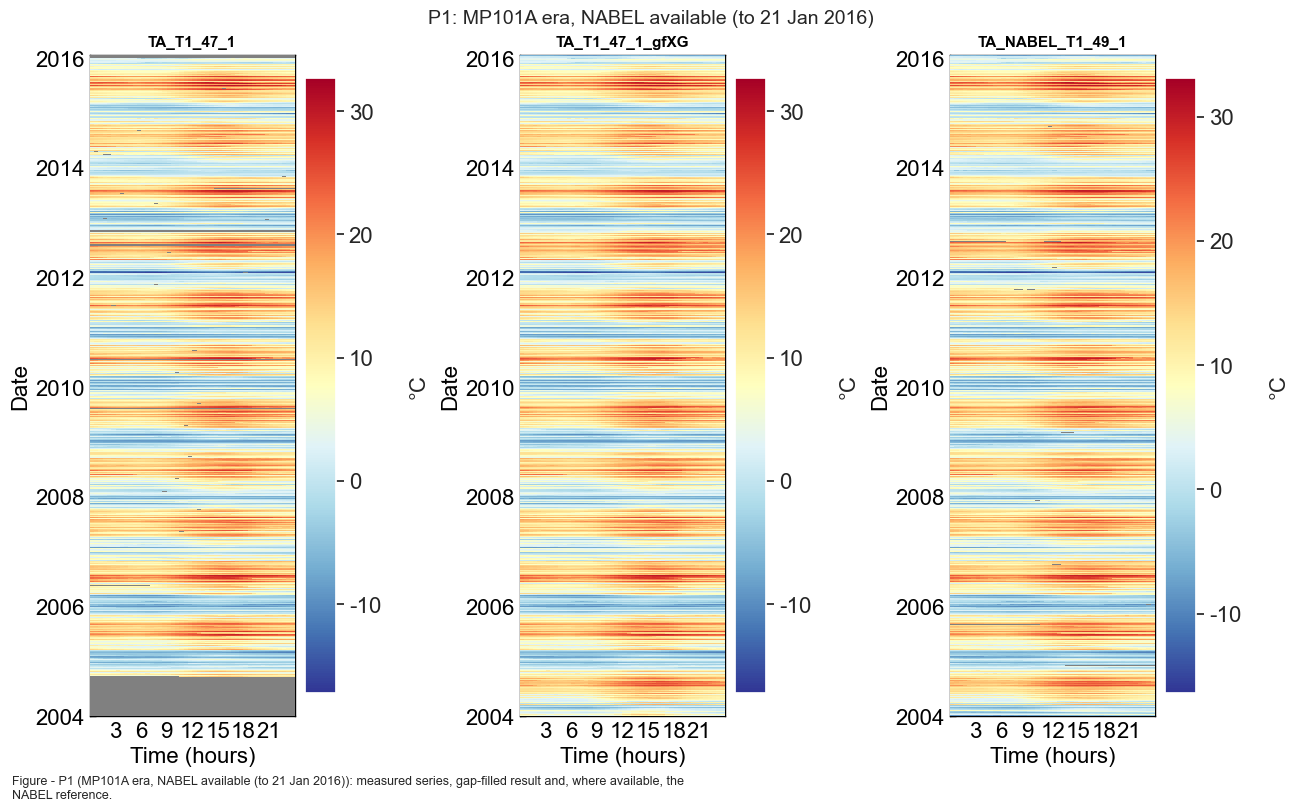

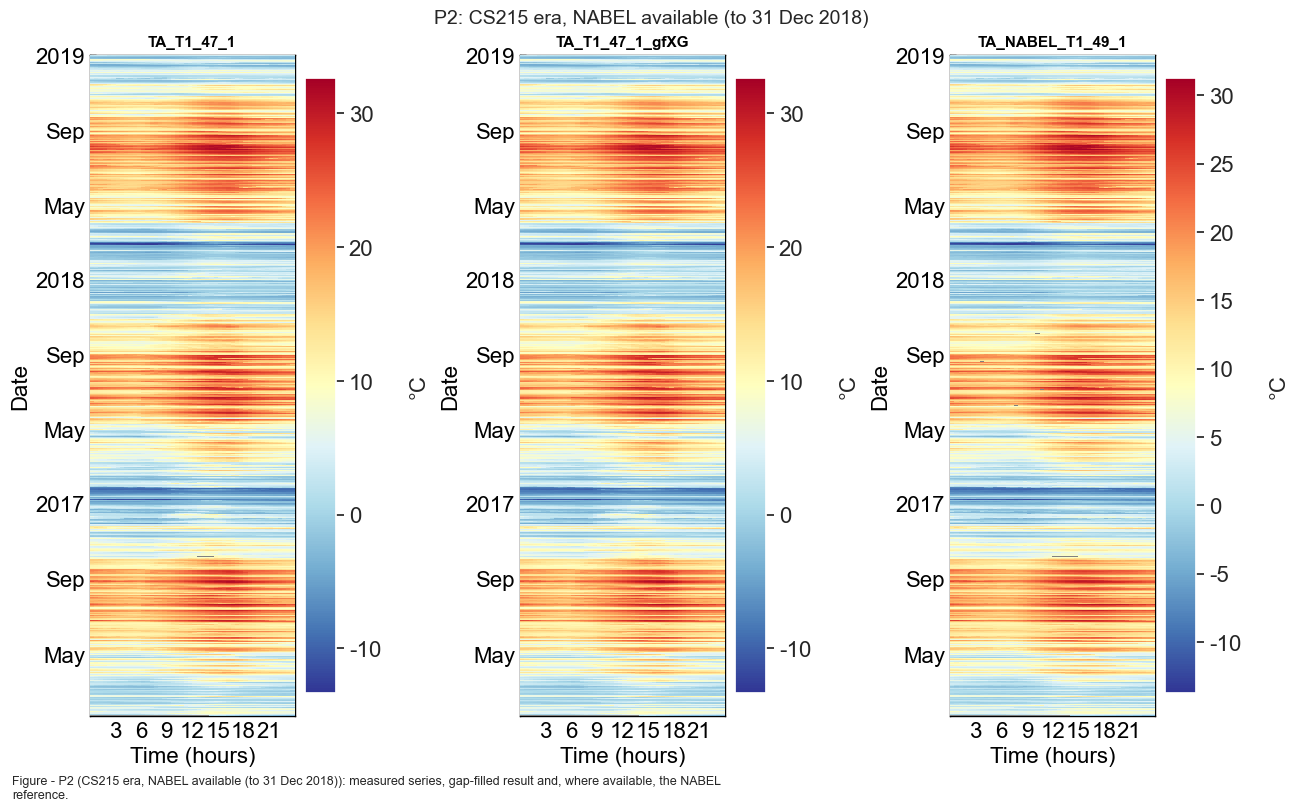

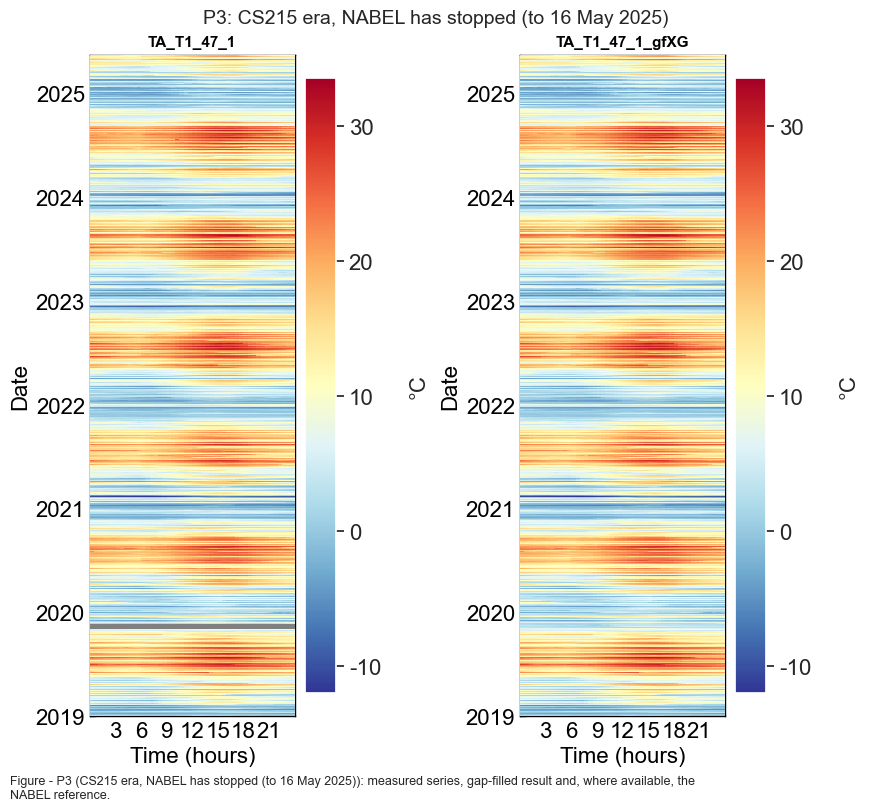

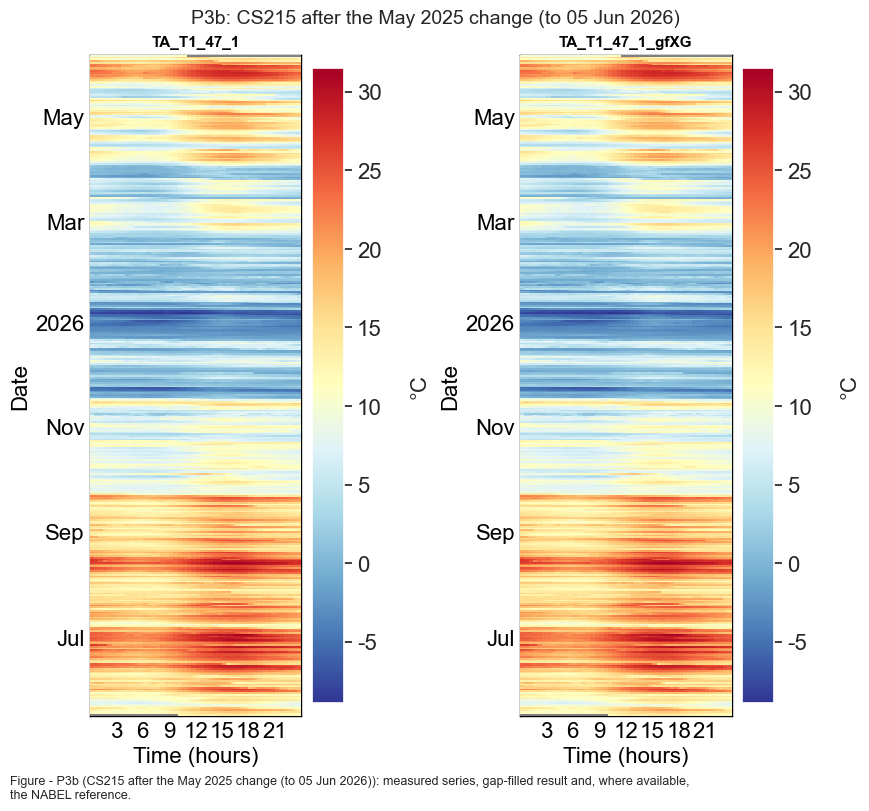

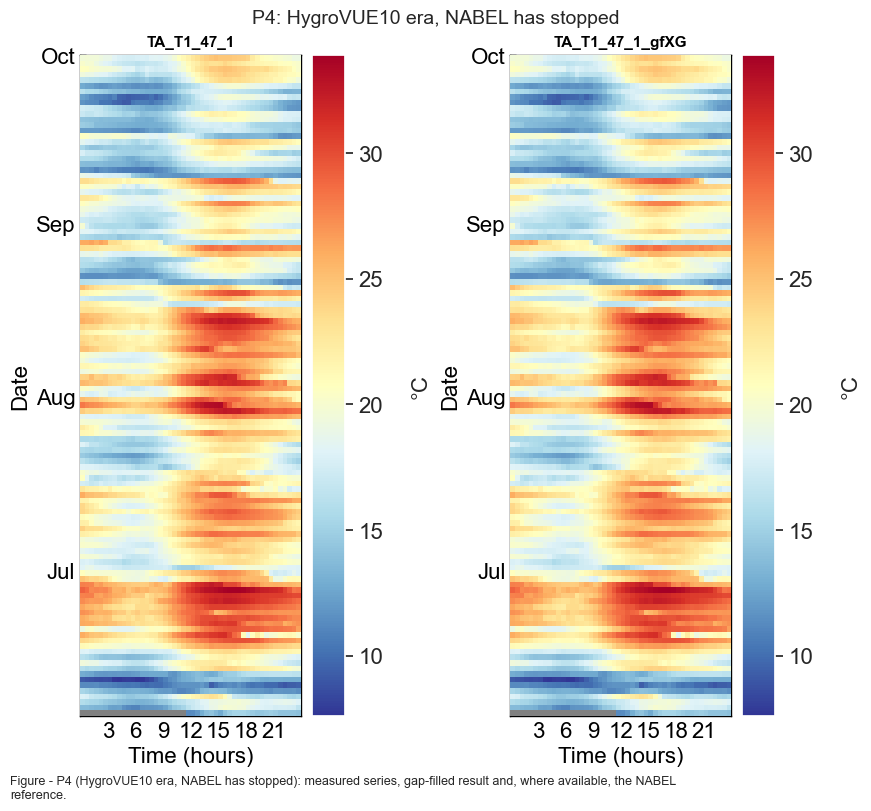

In [76]:
for _key, _r in results.items():
    _cols = [c for c in ['TA_T1_47_1', 'TA_T1_47_1_gfXG', 'TA_NABEL_T1_49_1']
             if c in _r['ta'].columns or c == 'TA_T1_47_1_gfXG']
    _plotdf = _r['ta'].copy()
    _plotdf['TA_T1_47_1_gfXG'] = _r['gapfilled']
    fig, axs = plt.subplots(ncols=len(_cols), figsize=(4.3 * len(_cols), 8), dpi=100,
                            layout="constrained")
    fig.suptitle(f"{_key}: {_r['label']}", fontsize=14)
    for _ax, _col in zip(np.atleast_1d(axs), _cols):
        dv.plotting.HeatmapDateTime(series=_plotdf[_col]).plot(
            ax=_ax, cb_digits_after_comma=0, zlabel='°C',
            format_style=dv.plotting.FormatStyle(title=_col, title_fontsize=11))
    figcap(fig, f"{_key} ({_r['label']}): measured series, gap-filled result and, where available, the NABEL reference.")


***

## ➡️ Prepare dataframe for export

In [77]:
VALCOL = "TA_T1_47_1_gfXG"
FLAGCOL = "FLAG_TA_T1_47_1_ISFILLED"
HOMOGCOL = "TA_T1_47_1_HOMOGENIZED_gfXG"
SOURCECOL = "FLAG_TA_T1_47_1_SOURCE"

# Values and flags come from the same fit per period, so they are paired before the periods are
# stacked. The periods were asserted above to tile the record exactly once.
export_df = pd.concat([pd.concat([_r['gapfilled'], _r['flag']], axis=1)
                       for _r in results.values()], axis=0)
export_df


,TA_T1_47_1_gfXG,FLAG_TA_T1_47_1_ISFILLED
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,7.687806,2
2004-01-01 00:45:00,7.687806,2
2004-01-01 01:15:00,7.430779,2
2004-01-01 01:45:00,7.430779,2
2004-01-01 02:15:00,6.550650,2
...,...,...
2026-09-30 21:45:00,20.036860,0
2026-09-30 22:15:00,19.797794,0
2026-09-30 22:45:00,19.679122,0


### 🩹 Records the gap-filler could only fill from the clock

XGBoost predicts only where **every** feature is present. Otherwise the record falls to the
timestamp-only fallback (`ISFILLED == 2`), which follows the season but not the weather and writes
one prediction per hour to both half-hours.

Most such records are in **January 2004** (table below), before MeteoSwiss Lägern begins on
1 February 2004. NABEL, two metres above the target on the same tower, is complete that month.
These records are therefore reconstructed from NABEL with a straight line (slope and offset)
fitted on the measured records of the same sensor era, and re-coded `ISFILLED == 5`. Records
where NABEL is missing as well keep code `2`. The cell assigns values rather than adjusting them,
so re-running it changes nothing.

#### 📋 Table: tower-on-NABEL fit per sensor era

In [78]:
# Fallback records that NABEL can repair. The fit is per sensor era: the tower-to-NABEL
# relationship differs between the two by the offset this notebook exists to document.
_nabel = ta_2004_2026['TA_NABEL_T1_49_1'].reindex(export_df.index)
_fallback = export_df[FLAGCOL] == FILL_FALLBACK
_measured = export_df[FLAGCOL] == FILL_OBSERVED

_eras = {'MP101A': export_df.index < BREAK,
         'CS215': (export_df.index >= BREAK) & (export_df.index < RESET_START),
         'CS215 after May 2025': (export_df.index >= RESET_START) & (export_df.index < HV_START),
         'HygroVUE10': export_df.index >= HV_START}
_report = []
for _era_name, _era_mask in _eras.items():
    _fit = _measured & _era_mask & _nabel.notna()
    _fix = _fallback & _era_mask & _nabel.notna()
    if _fix.sum() == 0:
        _report.append({'era': _era_name, 'repairable': 0, 'slope': np.nan, 'intercept': np.nan,
                        'fitted on': int(_fit.sum())})
        continue
    assert _fit.sum() > 10_000, \
        f"{_era_name}: only {int(_fit.sum())} measured records with NABEL to fit on"
    _slope, _intercept = np.polyfit(_nabel[_fit].to_numpy(), export_df.loc[_fit, VALCOL].to_numpy(), 1)
    # A guard on the fit: the two sensors measure the same air, so the slope must be near one.
    assert 0.9 < _slope < 1.1, f"{_era_name}: tower-on-NABEL slope {_slope:.3f} is not near 1"
    # Assignment, not adjustment - re-running the cell reproduces the same values.
    export_df.loc[_fix, VALCOL] = _slope * _nabel[_fix] + _intercept
    export_df.loc[_fix, FLAGCOL] = FILL_FROM_NABEL
    _report.append({'era': _era_name, 'repairable': int(_fix.sum()), 'slope': _slope,
                    'intercept': _intercept, 'fitted on': int(_fit.sum())})
tabcap("the tower-on-NABEL fit used to reconstruct the timestamp-only fallback records, per sensor era, with the number repaired")
display(pd.DataFrame(_report).set_index('era').round(4))

Table - the tower-on-NABEL fit used to reconstruct the timestamp-only fallback records, per sensor
era, with the number repaired



,repairable,slope,intercept,fitted on
era,,,,
MP101A,1530,1.0133,-1.0693,195060
CS215,0,NaN,NaN,51600
CS215 after May 2025,0,NaN,NaN,0
HygroVUE10,0,NaN,NaN,0


#### 📋 Table: when the NABEL reconstructions occur

In [79]:
# Where they are. They are not all in January 2004, and a limitation stated as if they were
# would mislead anyone looking at another period.
_where = export_df.index[export_df[FLAGCOL] == FILL_FROM_NABEL]
tabcap("when the records reconstructed from NABEL occur: mostly in January 2004, but not only")
display(pd.Series(1, index=_where).groupby([_where.year, _where.month]).sum()
        .rename('records reconstructed from NABEL').to_frame())

_left = int((export_df[FLAGCOL] == FILL_FALLBACK).sum())
print(f"still on the timestamp-only fallback (NABEL missing too): {_left} records")
assert (export_df[FLAGCOL] == FILL_FROM_NABEL).sum() > 0, "no fallback record was reconstructed"


Table - when the records reconstructed from NABEL occur: mostly in January 2004, but not only



records reconstructed from NABEL
TIMESTAMP_MIDDLE TIMESTAMP_MIDDLE                                  
2004             1                                             1488
                 2                                                1
2012             7                                               41

still on the timestamp-only fallback (NABEL missing too): 43 records


In [80]:
# The homogenised column, from the corrections derived in the break section:
#   - the step-8 constant, added to the MP101A era (one night level);
#   - the CS215 shield's radiative excess, subtracted from the CS215 (codes 0 and 7) and the
#     HygroVUE10 eras (one daytime behaviour);
#   - the night term of step 11, subtracted from the CS215 after May 2025 (code 6) instead of it;
#   - the HygroVUE10 transfer of step 12, which first brings that era onto the normal CS215 level.
# The measured column stays as reported, apart from the NABEL reconstruction above.
# Both terms apply to modelled records too: no model spans the sensor change, the NABEL
# reconstruction is fitted per era, and the shield term uses the SW_IN the models used as a driver.
# The audit below checks the first per year and per fill method.
_sw_export = swin_gf[SWIN_COL].reindex(export_df.index)
assert _sw_export.notna().all(), (
    "SW_IN is missing on part of the export index, so the shield term cannot be applied there")
export_df[HOMOGCOL] = homogenize(export_df[VALCOL], export_df.index, _sw_export)
export_df[SOURCECOL] = source_flag.reindex(export_df.index).astype(int)

export_df = export_df[[VALCOL, FLAGCOL, HOMOGCOL, SOURCECOL]]
export_df


,TA_T1_47_1_gfXG,FLAG_TA_T1_47_1_ISFILLED,TA_T1_47_1_HOMOGENIZED_gfXG,FLAG_TA_T1_47_1_SOURCE
TIMESTAMP_MIDDLE,,,,
2004-01-01 00:15:00,-3.771351,5,-2.451677,3
2004-01-01 00:45:00,-3.670024,5,-2.350349,3
2004-01-01 01:15:00,-3.636248,5,-2.316573,3
2004-01-01 01:45:00,-3.737576,5,-2.417901,3
2004-01-01 02:15:00,-3.906455,5,-2.586781,3
...,...,...,...,...
2026-09-30 21:45:00,20.036860,0,20.151199,4
2026-09-30 22:15:00,19.797794,0,19.912133,4
2026-09-30 22:45:00,19.679122,0,19.793461,4


Sanity checks: both value columns complete, a continuous 30MIN index without duplicates, both
flags on every record. Unlike for `SW_IN`, there is no non-negativity check.

The correction is also **audited**. The homogenised column must differ from the measured one by
exactly the derived terms (the constant before the break, the shield term after it, the night
term of step 1️⃣1️⃣ instead of it for code `6`, and in the HygroVUE10 era the transfer of step 1️⃣2️⃣
as well), and must remove the night-time step it was
derived for. A correction that left the step in place would make
the break look handled.

#### 📋 Table: exported records by fill method

In [81]:
print(f"Records:         {len(export_df)}")
print(f"Missing values:  {export_df[VALCOL].isnull().sum()} ({VALCOL})")
print(f"Missing values:  {export_df[HOMOGCOL].isnull().sum()} ({HOMOGCOL})")
print(f"Missing flags:   {export_df[FLAGCOL].isnull().sum()} / {export_df[SOURCECOL].isnull().sum()}")
print(f"Duplicate index: {export_df.index.duplicated().sum()}")
print(f"Index gaps:      {(export_df.index.to_series().diff().dropna() != pd.Timedelta('30min')).sum()}")
print(f"Min / max:       {export_df[VALCOL].min():.2f} / {export_df[VALCOL].max():.2f} degC")

print("\nFill provenance:")
_counts = export_df[FLAGCOL].value_counts().sort_index()
_pct = 100 * _counts / len(export_df)
tabcap("how each exported record was produced, by fill method")
display(pd.DataFrame({'count': _counts, '%': _pct.round(2)}).rename(index=FLAG_LEGEND))
print(f"Measured: {100 * (export_df[FLAGCOL] == 0).mean():.2f}%  |  "
      f"Filled: {100 * (export_df[FLAGCOL] > 0).mean():.2f}%")

Records:         398832
Missing values:  0 (TA_T1_47_1_gfXG)
Missing values:  0 (TA_T1_47_1_HOMOGENIZED_gfXG)
Missing flags:   0 / 0
Duplicate index: 0
Index gaps:      0
Min / max:       -17.20 / 33.90 degC

Fill provenance:
Table - how each exported record was produced, by fill method



,count,%
FLAG_TA_T1_47_1_ISFILLED,,
0 = observed,382167,95.82
1 = gap-filled by the XGBoost model,14914,3.74
2 = gap-filled by the timestamp-only fallback model (a driver was missing),43,0.01
4 = gap-filled by linear interpolation (short gap),178,0.04
5 = reconstructed from NABEL at 49 m on the same tower (the model lacked a driver),1530,0.38


Measured: 95.82%  |  Filled: 4.18%


#### 📋 Table: exported records by sensor

In [82]:
print("\nSensor provenance:")
_sc = export_df[SOURCECOL].value_counts().sort_index()
tabcap("which sensor and acquisition system each exported record belongs to")
display(pd.DataFrame({'count': _sc, '%': (100 * _sc / len(export_df)).round(2)}
                     ).rename(index=FLAG_SOURCE_LEGEND))

# --- structural checks ------------------------------------------------------------------------
assert export_df[VALCOL].notna().all() and export_df[HOMOGCOL].notna().all(), \
    "a gap-filled column must not contain missing values"
assert export_df[FLAGCOL].isin(FLAG_LEGEND).all(), "unknown code in the fill flag"
assert export_df[SOURCECOL].isin(FLAG_SOURCE_LEGEND).all(), "unknown code in the source flag"
assert export_df.index[-1] == pd.Timestamp(PERIOD_END), (
    f"the export ends at {export_df.index[-1]}, not at PERIOD_END ({PERIOD_END})")

# --- the homogenisation is exactly what it claims to be ---------------------------------------
# Four eras by time: MP101A before the break, CS215 with the shield term from the break to the
# May 2025 change (codes 0 and 7 and the handling record), CS215 after it (code 6 and the swap
# record), HygroVUE10 after the probe change.
_delta = export_df[HOMOGCOL] - export_df[VALCOL]
_pre = export_df.index < BREAK
_post = (export_df.index >= BREAK) & (export_df.index < RESET_START)   # CS215 with the shield term
_c6 = (export_df.index >= RESET_START) & (export_df.index < HV_START)  # CS215 after May 2025
_hv = export_df.index >= HV_START                                      # the HygroVUE10 era
assert _pre.sum() + _post.sum() + _c6.sum() + _hv.sum() == len(export_df), \
    "the four eras do not cover the export"
assert np.allclose(_delta[_pre], OFFSET), \
    "the pre-break era was not shifted by exactly the derived offset"
assert np.allclose(_delta[_post], -radiative_excess(_sw_export[_post])), \
    "the CS215 era does not carry exactly the radiative excess derived in the break section"
# Code 7 is homogenised exactly as code 0, and code 6 by the night term alone: one constant, the
# same at night and by day, with no radiation dependence.
_c7 = (export_df[SOURCECOL] == SOURCE_CS215_HEATED).to_numpy()
assert _c7.sum() > 0 and np.allclose(_delta[_c7], -radiative_excess(_sw_export[_c7])), \
    "code 7 is not homogenised exactly as the normal CS215"
assert np.allclose(_delta[_c6], -C6_TERMS['night']), \
    "the CS215 after May 2025 does not carry exactly the night term of step 11"
_c6_night = _c6 & NIGHT.reindex(export_df.index).fillna(False).astype(bool).to_numpy()
assert _c6_night.sum() > 1_000 and np.allclose(_delta[_c6_night], -C6_TERMS['night']), \
    "a night record of the CS215 after May 2025 was not moved by exactly the night term"
_hv_term = hv_excess(_sw_export[_hv]) + HV_TERMS['night']
assert np.allclose(_delta[_hv], -radiative_excess(_sw_export[_hv]) - _hv_term), \
    "the HygroVUE10 era does not carry exactly its transfer of step 12 plus the radiative excess"
# The shield term acts in daylight only, so a CS215 record with no sun must be untouched. This is
# what keeps the night level of step 8 intact, and it is the first thing a wrong sign would break.
_dark = _post & (_sw_export <= 0)
assert _dark.sum() > 50_000, f"only {int(_dark.sum())} dark records in the CS215 era to check"
assert np.allclose(_delta[_dark], 0.0), \
    "a CS215 record with no incoming radiation was modified by the shield term"
# A HygroVUE10 record with no sun moves by the night term of step 12 only.
_hv_dark = _hv & (_sw_export <= 0)
assert _hv_dark.sum() > 1_000, f"only {int(_hv_dark.sum())} dark records in the HygroVUE10 era to check"
assert np.allclose(_delta[_hv_dark], -HV_TERMS['night']), \
    "a HygroVUE10 record with no incoming radiation was moved by more than the night term"
# The shield term can only ever cool, by a bounded amount: in the CS215 era it is the whole
# correction, in the HygroVUE10 era it is what remains after the transfer. The transfer itself
# warms in sun, because the HygroVUE10 reads cooler than the CS215 there.
assert (_delta[_post] <= 1e-9).all(), "the shield term warmed a record of the CS215 era"
assert _delta[_post].min() > -1.5, \
    f"the shield term removes up to {-_delta[_post].min():.2f} degC, far more than it was fitted to"
assert ((_delta[_hv] + _hv_term) <= 1e-9).all(), "the shield term warmed a record of the HygroVUE10 era"
assert _delta[_hv].abs().max() < 1.5, \
    f"the HygroVUE10 era moves by up to {_delta[_hv].abs().max():.2f} degC, far more than it was fitted to"
assert (export_df.loc[export_df.index < BREAK, SOURCECOL] != SOURCE_CS215).all(), \
    "a record before the break is flagged as the CS215 era"
_normal = _post & (export_df.index < EXCESS_START)
assert (export_df.loc[_normal, SOURCECOL] == SOURCE_CS215).all(), \
    "a record of the normal CS215 era is not flagged as code 0"
assert (export_df.loc[_post & ~_normal & (export_df.index != HANDLING_RECORD), SOURCECOL]
        == SOURCE_CS215_HEATED).all(), "a record of the heated CS215 is not flagged as code 7"
assert (export_df.loc[_c6 & (export_df.index != SWAP_RECORD), SOURCECOL] == SOURCE_CS215_MAY2025).all(), \
    "a record of the CS215 after May 2025 is not flagged as code 6"
assert (export_df.loc[_hv, SOURCECOL] == SOURCE_HYGROVUE).all(), \
    "a record after the probe change is not flagged as the HygroVUE10 era"
# The two probe half-hours: modelled, flagged as such, and homogenised with the period that
# modelled them - the handling record as the CS215 before it, the swap record as code 6.
assert (export_df[SOURCECOL] == SOURCE_SWAP).sum() == 2 and \
    (export_df.loc[[HANDLING_RECORD, SWAP_RECORD], SOURCECOL] == SOURCE_SWAP).all(), \
    "the probe half-hours are not the only records flagged as code 5"
assert (export_df.loc[[HANDLING_RECORD, SWAP_RECORD], FLAGCOL] != FILL_OBSERVED).all(), \
    "a probe half-hour is flagged as measured"
assert np.isclose(_delta[HANDLING_RECORD], -radiative_excess([_sw_export[HANDLING_RECORD]])[0]), \
    "the probe handling record is not homogenised as the CS215 before the change"
assert np.isclose(_delta[SWAP_RECORD], -C6_TERMS['night']), \
    "the probe swap record is not homogenised as the CS215 after May 2025"

# --- the break year is corrected like any other ------------------------------------------------
# The whole-record checks above would pass on a product that treated the break year specially,
# since that year is a fraction of a percent of the record, so it is checked on both sides of the
# changeover. Its first three weeks are the outage: modelled on the MP101A level, they carry the
# constant (source code 2 means era undetermined, not uncorrected). From the changeover on, the
# year is CS215 and carries the shield term.
_bk_before = (export_df.index.year == BREAK.year) & (export_df.index < BREAK)
_bk_after = (export_df.index.year == BREAK.year) & (export_df.index >= BREAK)
assert _bk_before.sum() > 0 and _bk_after.sum() > 0, \
    "the break year does not straddle the break, so it cannot be checked on both sides"
assert np.allclose(_delta[_bk_before], OFFSET), \
    "the part of the break year before the changeover did not receive the constant"
assert np.allclose(_delta[_bk_after], -radiative_excess(_sw_export[_bk_after])), \
    "the part of the break year after the changeover does not carry exactly the shield term"
assert (export_df.loc[_bk_before, SOURCECOL] == SOURCE_CHANGEOVER).all(), \
    "the break year before the changeover is not flagged as the changeover"
assert np.allclose(_delta[export_df[SOURCECOL] == SOURCE_CHANGEOVER], OFFSET), \
    "a changeover record did not receive the constant - the outage that contains the sensor swap " \
    "is modelled on the MP101A level and must be corrected onto the CS215 level like the rest of " \
    "that era"

# --- the correction removes the step it was derived to remove ---------------------------------
# Re-derived here from the exported column against NABEL, not carried over from the section above,
# so that a change anywhere between the two is caught.
_audit = pd.concat([export_df[HOMOGCOL], export_df[VALCOL],
                    ta_2004_2026['TA_NABEL_T1_49_1']], axis=1).dropna()
_audit = _audit[NIGHT.reindex(_audit.index).fillna(False)]
_before = _audit.loc[:LAST_BEFORE]
_after = _audit.loc[BREAK:'2018']
for _col, _label in [(VALCOL, 'measured   '), (HOMOGCOL, 'homogenised')]:
    _step = ((_after[_col] - _after['TA_NABEL_T1_49_1']).mean()
             - (_before[_col] - _before['TA_NABEL_T1_49_1']).mean())
    print(f"\nNight-time step against NABEL, {_label}: {_step:+.3f} degC")
    if _col == HOMOGCOL:
        assert abs(_step) < 0.15, (
            f"the homogenised column still steps by {_step:+.3f} degC at the break - the "
            f"correction did not do what it was derived to do")

export_df.describe()



Sensor provenance:
Table - which sensor and acquisition system each exported record belongs to



,count,%
FLAG_TA_T1_47_1_SOURCE,,
"0 = Campbell CS215, SDI-12, 21 Jan 2016 - 21 Oct 2024 (the reference era of the homogenisation)",153428,38.47
"1 = Rotronic MP101A, analog single-ended, 2004 - 31 Dec 2015 (reads about 1.3 degC low)",197739,49.58
"2 = acquisition changeover, 01 - 21 Jan 2016: no measurement, sensor era undetermined",988,0.25
"3 = before the tower record begins (2004): no measurement, values are modelled throughout",12645,3.17
"4 = Campbell HygroVUE10, SDI-12, from 05 Jun 2026 11:30 (reads cooler than the CS215 in sun)",5641,1.41
"5 = probe handling or swap half-hour (16 May 2025 09:30-10:00, 05 Jun 2026 11:00-11:30): measured value removed, modelled and homogenised with its period",2,0.00
"6 = Campbell CS215 after the 16 May 2025 change, 16 May 2025 10:00 - 05 Jun 2026 11:00: no daytime shield excess, night term only",18482,4.63
"7 = Campbell CS215 with excess daytime heating, 22 Oct 2024 - 16 May 2025 09:30: homogenised as code 0, too warm in sun",9907,2.48



Night-time step against NABEL, measured   : +1.313 degC

Night-time step against NABEL, homogenised: -0.007 degC


,TA_T1_47_1_gfXG,FLAG_TA_T1_47_1_ISFILLED,TA_T1_47_1_HOMOGENIZED_gfXG,FLAG_TA_T1_47_1_SOURCE
count,398832.000000,398832.000000,398832.000000,398832.000000
mean,9.080403,0.058576,9.715703,1.104387
std,8.238321,0.370730,8.131148,1.638055
min,-17.200001,0.000000,-15.880326,0.000000
25%,2.670000,0.000000,3.387647,0.000000
50%,9.015589,0.000000,9.643293,1.000000
75%,15.180000,0.000000,15.809809,1.000000
max,33.895510,5.000000,34.380819,7.000000


#### 📊 Plot: heatmaps of the two exported columns

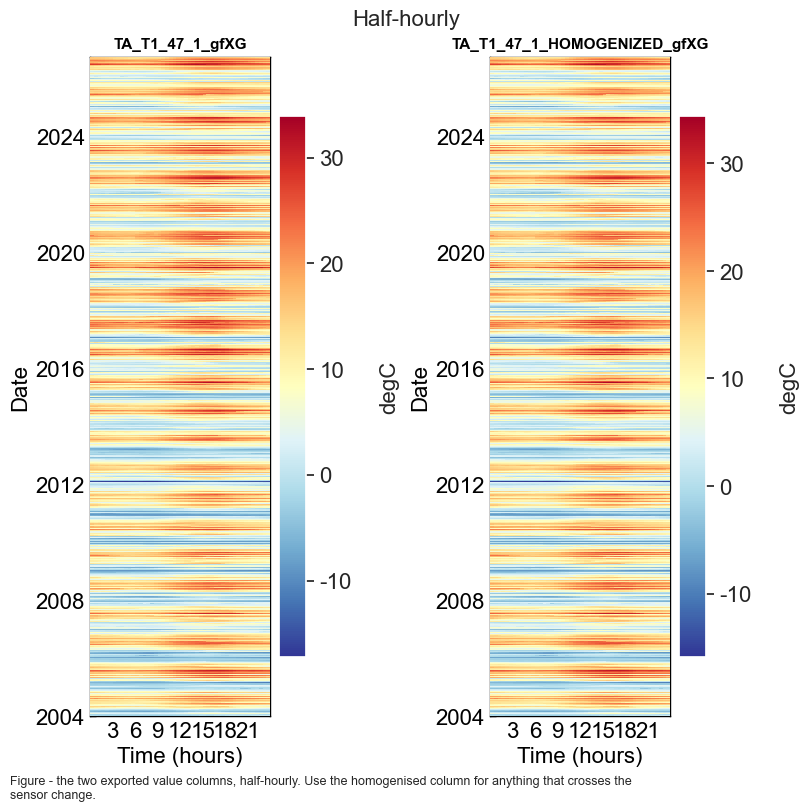

In [83]:
fig, axs = plt.subplots(ncols=2, figsize=(8, 8), dpi=100, layout="constrained")
fig.suptitle('Half-hourly', fontsize=16)
for _ax, _col in zip(axs, [VALCOL, HOMOGCOL]):
    dv.plotting.HeatmapDateTime(series=export_df[_col]).plot(
        ax=_ax, cb_digits_after_comma=0, zlabel='degC',
        format_style=dv.plotting.FormatStyle(title=_col, title_fontsize=11))
figcap(fig, "the two exported value columns, half-hourly. Use the homogenised column for anything that crosses the sensor change.")

#### Does the reconstruction method work? A month where the answer is known

The level and spread tests below cannot fail for the reconstructed records, because these were
fitted to NABEL. The **method** is tested instead: the line is refitted *without* January and
predicts the measured Januaries of the same era. The residual is a real error estimate, compared
with the scatter between the two co-located sensors, the floor no reconstruction can beat.

#### 📋 Table: January hold-out of the NABEL reconstruction

In [84]:
# Refit without January, predict the measured Januaries of the MP101A era.
_m = (export_df[FLAGCOL] == FILL_OBSERVED) & (export_df.index < BREAK) & _nabel.notna()
_jan = _m & (export_df.index.month == 1)
_rest = _m & (export_df.index.month != 1)
assert _jan.sum() > 5_000, f"only {int(_jan.sum())} measured January records to test on"

_s_ho, _i_ho = np.polyfit(_nabel[_rest].to_numpy(), export_df.loc[_rest, VALCOL].to_numpy(), 1)
_resid = export_df.loc[_jan, VALCOL] - (_s_ho * _nabel[_jan] + _i_ho)
_floor = (export_df.loc[_m, VALCOL] - _nabel[_m]).std()   # sensor-to-sensor scatter, all hours

print(f"fitted without January on {int(_rest.sum()):,} records: "
      f"slope {_s_ho:.4f}, intercept {_i_ho:+.4f}")
print(f"predicting {int(_jan.sum()):,} measured January records "
      f"({export_df.index[_jan].year.min()}-{export_df.index[_jan].year.max()}):")
print(f"  bias {_resid.mean():+.3f} degC | RMSE {np.sqrt((_resid ** 2).mean()):.3f} degC")
print(f"  scatter between the two sensors anyway (the floor): {_floor:.3f} degC")
tabcap("hold-out test of the NABEL reconstruction: a fit made without January predicts the measured Januaries, per year")
display(_resid.groupby(_resid.index.year).agg(records='count', bias='mean').round(3))

# The reconstruction line is fitted over all hours and applied to a whole month, so the daytime
# has to be checked as well: the two sensors' shields differ, and that difference is a daytime one.
for _when, _mask in [('night', NIGHT.reindex(_resid.index).fillna(False)),
                     ('day  ', ~NIGHT.reindex(_resid.index).fillna(False))]:
    _r = _resid[_mask]
    print(f"  {_when}: bias {_r.mean():+.3f} degC | RMSE {np.sqrt((_r ** 2).mean()):.3f} degC "
          f"(n={len(_r):,})")

assert abs(_resid.mean()) < 0.25, (
    f"reconstructing a January from NABEL is biased by {_resid.mean():+.3f} degC - the line fitted "
    f"on the rest of the year does not transfer to winter")
assert np.sqrt((_resid ** 2).mean()) < 2 * _floor, (
    f"reconstruction RMSE {np.sqrt((_resid ** 2).mean()):.3f} degC is more than twice the "
    f"{_floor:.3f} degC the two sensors differ by anyway")


fitted without January on 178,832 records: slope 1.0149, intercept -1.0889
predicting 16,228 measured January records (2005-2015):
  bias +0.063 degC | RMSE 0.415 degC
  scatter between the two sensors anyway (the floor): 0.380 degC
Table - hold-out test of the NABEL reconstruction: a fit made without January predicts the measured
Januaries, per year



,records,bias
TIMESTAMP_MIDDLE,,
2005,1367,0.225
2006,1486,0.282
2007,1487,-0.111
2008,1487,-0.031
2009,1487,0.164
2010,1487,0.099
2011,1488,0.156
2012,1487,0.102
2013,1478,0.094


  night: bias -0.027 degC | RMSE 0.299 degC (n=9,998)
  day  : bias +0.207 degC | RMSE 0.552 degC (n=6,230)


#### Every modelled record sits on the era it belongs to, and varies like it

The offset is added to every pre-break record, which is valid only if modelled values share the
measured era's level. Two night-time tests against NABEL:

**Level, per year and per fill method.** A yearly average can hide opposite errors that cancel: an
earlier version passed a per-year check while holding 11,150 records 1.1 °C too cold and 1,495
records 5.5 °C too warm.

**Spread**, the stronger test. A timestamp-only climatology can have the right mean, but it
scatters against NABEL several degrees more widely than a measurement.

**Neither test is evidence for the records reconstructed from NABEL.** Fitted to NABEL, they match
its level and scatter *less* than a measurement. They rest on the slope guard of the fit and on the
held-out January test above.

#### 📋 Table: night bias before the break by fill method

In [85]:
# Night bias against NABEL for everything before the break, by year and fill method.
_chk = pd.concat([export_df[[VALCOL, FLAGCOL]], ta_2004_2026['TA_NABEL_T1_49_1']],
                 axis=1).dropna()
_chk = _chk[NIGHT.reindex(_chk.index).fillna(False) & (_chk.index < BREAK)]
_chk['bias'] = _chk[VALCOL] - _chk['TA_NABEL_T1_49_1']
_chk['YEAR'] = _chk.index.year

_ref = _chk[_chk[FLAGCOL] == FILL_OBSERVED]['bias']
LEVEL, SPREAD = _ref.mean(), _ref.std()
print(f"measured MP101A era at night: level {LEVEL:+.3f} degC, spread (SD) {SPREAD:.3f} degC "
      f"(n={len(_ref):,})")

_tab = (_chk.groupby(['YEAR', FLAGCOL])['bias']
        .agg(records='count', level='mean', spread='std'))
_tab['level departure'] = (_tab['level'] - LEVEL).abs()
_tab['spread ratio'] = _tab['spread'] / SPREAD
_tab = _tab.rename(index=FLAG_LEGEND, level=1)
tabcap("night bias against NABEL before the break, by year and fill method. Each population is tested on its own")
display(_tab.round(2))

# Assert per (year, fill method) group that is large enough for its statistics to mean anything.
TOLERANCE, SPREAD_RATIO_MAX, MIN_NIGHTS = 0.5, 5.0, 100
_tested = []
for (_yr, _flag), _row in _tab.iterrows():
    if _row['records'] < MIN_NIGHTS or _flag == FLAG_LEGEND[FILL_OBSERVED]:
        continue
    _tested.append((_yr, _flag.split(' = ')[0]))
    assert _row['level departure'] < TOLERANCE, (
        f"{_yr}, fill method {_flag!r}: sits {_row['level departure']:.2f} degC from the measured "
        f"level of its era. The homogenisation offset is not valid for those records.")
    assert _row['spread ratio'] < SPREAD_RATIO_MAX, (
        f"{_yr}, fill method {_flag!r}: scatters {_row['spread ratio']:.1f}x more widely against "
        f"NABEL than the measurements do. Those values carry a season but not the weather.")
_first_year = int(_chk['YEAR'].min())
assert any(_y == _first_year for _y, _ in _tested), (
    f"{_first_year} was not tested: no modelled group reached {MIN_NIGHTS} night records. That is "
    f"the year with most of the record's fills, so a check that skips it is not checking the "
    f"thing it exists for.")
print(f"OK: {len(_tested)} (year, fill method) groups tested - {_tested}")


measured MP101A era at night: level -1.084 degC, spread (SD) 0.250 degC (n=93,754)
Table - night bias against NABEL before the break, by year and fill method. Each population is
tested on its own



records  level  spread  level departure  spread ratio
YEAR FLAG_TA_T1_47_1_ISFILLED                                                                                 
2004 0 = observed                                           2812  -0.85    0.27             0.23          1.06
     1 = gap-filled by the XGBoost model                    4638  -0.76    0.19             0.32          0.75
     5 = reconstructed from NABEL at 49 m on the sam...      918  -1.08    0.05             0.00          0.20
2005 0 = observed                                           8236  -0.97    0.23             0.11          0.90
     4 = gap-filled by linear interpolation (short gap)        3  -0.92    0.27             0.16          1.06
...                                                          ...    ...     ...              ...           ...
2014 0 = observed                                           8358  -1.30    0.35             0.22          1.41
     4 = gap-filled by linear interpolation (short gap)        9  -1.23    0.26             0.14          1.03
2015 0 = observed                                           8362  -1.06    0.18             0.03          0.73
     4 = gap-filled by linear interpolation (short gap)        6  -1.15    0.31             0.07          1.22
2016 1 = gap-filled by the XGBoost model                     614  -1.19    0.17             0.11          0.67

[32 rows x 5 columns]

OK: 5 (year, fill method) groups tested - [(2004, '1'), (2004, '5'), (2009, '1'), (2012, '1'), (2016, '1')]


***

#### The same figures from the finished columns

The break section computes these figures from **measured records only**. A user following the note
below computes them from the **exported columns**, which include the modelled share, and gets
slightly different numbers, so both are shown. Measured-only values are free of the model but
seasonally biased where a year's gaps cluster; the complete columns are free of that bias but
include the model. Their difference shows how much the gap-filling moves these statistics.

#### 📋 Table: headline figures, measured only and from the export

In [86]:
_yp = export_df[[VALCOL, HOMOGCOL]].resample('YE').mean()
_yp.index = _yp.index.year
_yp = _yp.loc[2005:LAST_FULL_YEAR]  # 2026 is partial
_e, _r = _yp.index < BREAK.year, _yp.index > BREAK.year

_rows = []
for _col, _name in [(VALCOL, 'as measured'), (HOMOGCOL, 'homogenised')]:
    _s = _yp[_col]
    _slope, _, _lo, _hi = theilslopes(_s.to_numpy(float), _s.index.to_numpy(float), alpha=0.95)
    _tau, _p = kendalltau(_s.index.to_numpy(float), _s.to_numpy(float))
    _rows.append({'series': _name,
                  f'{_yp.index.min()}-{BREAK.year - 1} (degC)': _s[_e].mean(),
                  f'{BREAK.year + 1}-{_yp.index.max()} (degC)': _s[_r].mean(),
                  'difference (degC)': _s[_r].mean() - _s[_e].mean(),
                  'Theil-Sen (degC/decade)': _slope * 10,
                  'lower 95 %': _lo * 10, 'upper 95 %': _hi * 10,
                  'Kendall tau': _tau, 'p': _p})
headline_product = pd.DataFrame(_rows).set_index('series')

_both = pd.concat([headline_measured.assign(computed_from='measured records only'),
                   headline_product.assign(computed_from='the exported columns')])
tabcap("the headline period difference and trend from measured records only and from the complete exported columns. A measured-only mean is seasonally biased wherever a year's gaps cluster")
display(_both.set_index('computed_from', append=True).round(3))

_gap = abs(headline_product.loc['homogenised', 'difference (degC)']
           - headline_measured.loc['homogenised', 'difference (degC)'])
print(f"The two ways of computing the homogenised period difference disagree by {_gap:.3f} degC, "
      f"which is\nthe influence of the {100 * (export_df[FLAGCOL] > 0).mean():.1f} % of the "
      f"product that is modelled. Both are reported; neither is\nsuppressed.")
assert _gap < 0.5, (
    f"the gap-filled and measured-only headline figures differ by {_gap:.2f} degC - large enough "
    f"that the modelled records, not the sensors, would be driving the reported difference")


Table - the headline period difference and trend from measured records only and from the complete
exported columns. A measured-only mean is seasonally biased wherever a year's gaps cluster



,,2005-2015 (degC),2017-2025 (degC),difference (degC),Theil-Sen (degC/decade),lower 95 %,upper 95 %,Kendall tau,p
series,computed_from,,,,,,,,
as measured,measured records only,7.848,10.323,2.475,1.802,1.160,2.483,0.590,0.000
homogenised,measured records only,9.168,10.170,1.003,0.767,0.290,1.282,0.476,0.002
as measured,the exported columns,7.904,10.294,2.390,1.760,1.312,2.367,0.629,0.000
homogenised,the exported columns,9.223,10.142,0.919,0.769,0.338,1.283,0.476,0.002


The two ways of computing the homogenised period difference disagree by 0.084 degC, which is
the influence of the 4.2 % of the product that is modelled. Both are reported; neither is
suppressed.


***

## 📘 Note for downstream users

**Which column to use.**

- Within one sensor era: `TA_T1_47_1_gfXG`, the values the instrument reported.
- Across **21 January 2016**, **16 May 2025** or **5 June 2026** (period means, trends, rankings
  of years, anomalies against a multi-year reference): `TA_T1_47_1_HOMOGENIZED_gfXG`. The measured
  column steps by about 1.3 °C at the first date for instrumental reasons, more than the climate
  signal over this record; it reads too warm in sun from autumn 2024 to 16 May 2025 and without
  the usual shield excess after it; and its HygroVUE10 era reads cooler in sun than the CS215.
- The homogenised column differs from the measured one **in every era**: by a constant before
  2016; in the CS215 era (codes `0` and `7`) by a radiation-dependent amount that is zero at night
  and largest in strong sun; in the CS215 after May 2025 (code `6`) by the constant night term of
  step 1️⃣1️⃣; and in the HygroVUE10 era by the radiation-dependent amount and the HygroVUE10
  transfer of step 1️⃣2️⃣, which raises it in sun, plus the constant night term of step 1️⃣2️⃣. The
  difference between the two columns is therefore not a constant.

**Which flag to filter on.**

- `FLAG_TA_T1_47_1_ISFILLED == 0` selects measured records; all others are modelled. Code `5`
  marks records reconstructed from NABEL on the same tower, code `2` the few filled from the clock
  only.
- `FLAG_TA_T1_47_1_SOURCE`: `1` Rotronic MP101A era, `0` Campbell CS215 era, `7` the heated
  CS215 (autumn 2024 to 16 May 2025), `6` the CS215 after its change of 16 May 2025, `4` Campbell
  HygroVUE10 era from 5 June 2026, `2` the 988 records of the January 2016 outage (neither era),
  `3` the months before the tower record begins in September 2004, `5` the probe handling and probe
  swap half-hours. **Codes `2`, `3` and `5` are everything no instrument stands behind**; drop them
  where provenance must be certain. **Drop code `7` for daytime statistics** (daily maxima,
  diurnal ranges): it stays too warm in sun after homogenisation.

Both value columns share both flags: the homogenisation changes values, not provenance.

**Known limitations.** The homogenised column puts the later era onto the earlier era's radiation
shield, so the shield error both sensors **share** remains: both read warm in sun and light wind
relative to an aspirated measurement. Daily maxima and diurnal ranges are biased warm, by a
comparable amount on both sides of 2016. The residual step is measured on every run in *What the
correction does not fix* above. That section also details two limitations the homogenisation does
not address: records reconstructed from NABEL carry too little scatter, so spread statistics over
their periods are understated, and 2004 has no measurement before 20 September. Code `7` is
under-corrected in sun, and the night term of code `6` is smaller than its uncertainty
(step 1️⃣1️⃣). The HygroVUE10 transfer is fitted on one summer against one reference and applied as fitted to the whole
HygroVUE10 era (step 1️⃣2️⃣). The record ends on 30 September 2026, so the 2026 annual mean covers
January to September only.

The evidence is re-derived on every run in *The 2016 acquisition break*, including its steps 1️⃣1️⃣
and 1️⃣2️⃣ for the May 2025 change and the June 2026 probe change.

## 💾 Save to file

In [87]:
filepath = dv.save_parquet(filename=OUTNAME, data=export_df, outpath=OUTPATH)
export_df.to_csv(Path(OUTPATH) / f"{OUTNAME}.csv")
print(f"Saved to: {filepath}")

> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\02_METEO_TA_GAPFILLED_2004-2026.09.parquet (0.089 seconds).

Saved to: F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS\02_METEO_TA_GAPFILLED_2004-2026.09.parquet


### Verify the written file

Reading the parquet back and checking it directly, rather than trusting the in-memory frame.

#### 📋 Table: yearly means and measured share, from the written file

In [88]:
_written = dv.load_parquet(filepath=str(Path(OUTPATH) / f"{OUTNAME}.parquet"))

print(f"columns:   {list(_written.columns)}")
print(f"index:     {_written.index[0]} -> {_written.index[-1]}  ({len(_written):,} records)")
print(f"measured:  {int((_written[FLAGCOL] == FILL_OBSERVED).sum()):,} "
      f"({100 * (_written[FLAGCOL] == FILL_OBSERVED).mean():.2f}%)")
for _c in (VALCOL, HOMOGCOL):
    print(f"{_c}: median {float(_written[_c].median()):.3f} degC, "
          f"min / max {float(_written[_c].min()):.2f} / {float(_written[_c].max()):.2f} degC")

assert list(_written.columns) == [VALCOL, FLAGCOL, HOMOGCOL, SOURCECOL], (
    "unexpected columns in the written file")
assert len(_written) == len(export_df), "record count changed on write"
assert _written.index.equals(export_df.index), "index changed on write"
# Both value columns are documented as complete, and the plausible range is checked here on the
# file itself rather than on the frame that was handed to the writer.
for _c in (VALCOL, HOMOGCOL):
    assert _written[_c].notna().all(), f"{_c} has gaps in the written file, but it is exported complete"
    assert -40 < float(_written[_c].min()) and float(_written[_c].max()) < 45, (
        f"{_c} is outside the plausible range for this site in the written file")
assert (set(_written[FLAGCOL].unique()) <= set(FLAG_LEGEND)), (
    "the written file carries a fill code that FLAG_LEGEND does not document")
assert (set(_written[SOURCECOL].unique()) <= set(FLAG_SOURCE_LEGEND)), (
    "the written file carries a source code that FLAG_SOURCE_LEGEND does not document")
# The homogenisation is the reason this product has a second value column, so the read-back reports
# what it did on each side of the break rather than only that the column arrived. The correction is
# two terms, so the later era takes a range of values rather than a single one.
_diff = _written[HOMOGCOL] - _written[VALCOL]
_before = _diff[_written.index < BREAK]
_after = _diff[(_written.index >= BREAK) & (_written.index < RESET_START)]
_c6_after = _diff[(_written.index >= RESET_START) & (_written.index < HV_START)]
_hv_after = _diff[_written.index >= HV_START]
print()
print(f"homogenised - measured: before the break {_before.min():+.4f} to {_before.max():+.4f} degC "
      f"({_before.round(4).nunique():,} distinct), CS215 era {_after.min():+.4f} to {_after.max():+.4f} "
      f"degC ({_after.round(4).nunique():,} distinct), CS215 after May 2025 {_c6_after.min():+.4f} to "
      f"{_c6_after.max():+.4f} degC ({_c6_after.round(4).nunique():,} distinct), HygroVUE10 era "
      f"{_hv_after.min():+.4f} to {_hv_after.max():+.4f} degC ({_hv_after.round(4).nunique():,} distinct)")
assert _c6_after.round(9).nunique() == 1, "the CS215 after May 2025 carries more than its one constant"
# The era codes of the probe change arrive in the file as they were assigned.
assert (_written.loc[_written.index >= HV_START, SOURCECOL] == SOURCE_HYGROVUE).all(), \
    "the written file does not flag every record after the probe change as the HygroVUE10 era"
assert (_written[SOURCECOL] == SOURCE_SWAP).sum() == 2 and \
    (_written.loc[[HANDLING_RECORD, SWAP_RECORD], SOURCECOL] == SOURCE_SWAP).all(), \
    "the written file does not flag the two probe half-hours alone"
for _code in (SOURCE_CS215_HEATED, SOURCE_CS215_MAY2025):
    assert (_written[SOURCECOL] == _code).sum() == (export_df[SOURCECOL] == _code).sum(), \
        f"the written file carries a different number of code-{_code} records"
print()
print("Written file verified.")

tabcap("yearly means of both value columns and the measured share, read back from the written parquet file")
display(pd.DataFrame({
    'as measured (degC)': _written[VALCOL].groupby(_written.index.year).mean().round(3),
    'homogenised (degC)': _written[HOMOGCOL].groupby(_written.index.year).mean().round(3),
    'measured (%)': (100 * (_written[FLAGCOL] == FILL_OBSERVED)).groupby(_written.index.year).mean().round(1),
}))

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\02_METEO_TA_GAPFILLED_2004-2026.09.parquet (0.016 seconds).

columns:   ['TA_T1_47_1_gfXG', 'FLAG_TA_T1_47_1_ISFILLED', 'TA_T1_47_1_HOMOGENIZED_gfXG', 'FLAG_TA_T1_47_1_SOURCE']
index:     2004-01-01 00:15:00 -> 2026-09-30 23:45:00  (398,832 records)
measured:  382,167 (95.82%)
TA_T1_47_1_gfXG: median 9.016 degC, min / max -17.20 / 33.90 degC
TA_T1_47_1_HOMOGENIZED_gfXG: median 9.643 degC, min / max -15.88 / 34.38 degC

homogenised - measured: before the break +1.3197 to +1.3197 degC (1 distinct), CS215 era -0.5877 to +0.0000 degC (5,878 distinct), CS215 after May 2025 -0.0576 to -0.0576 degC (1 distinct), HygroVUE10 era +0.1143 to +0.5254 degC (1,871 distinct)

Written file verified.
Table - yearly means of both value columns and the measured share, read back from the written
parquet file



,as measured (degC),homogenised (degC),measured (%)
TIMESTAMP_MIDDLE,,,
2004,7.518,8.837,28.0
2005,7.430,8.750,99.8
2006,7.960,9.280,99.9
2007,8.109,9.429,99.9
2008,7.589,8.908,99.9
2009,7.941,9.261,97.2
2010,6.822,8.142,99.0
2011,8.787,10.106,99.9
2012,7.754,9.074,92.8


***

## End of notebook.

In [89]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-22 17:34:06
Finished: 2026-10-22 17:43:29
Runtime:  00:09:22 (hh:mm:ss)
